# Données, performance et allocation de portefeuille

Ce notebook regroupe toutes les étapes du projet :
- **Étape 1** (§ 0 à 8) — base de données et analyse exploratoire des rendements ;
- **Étape 2** (§ 9 à 16) — mesures de performance et de risque, appliquées au portefeuille équipondéré et à SPY ;
- **Étape 3** (§ 17 à 21) — optimisation de Markowitz : frontière efficiente, variance minimale, Sharpe maximal, estimateur de Ledoit-Wolf ;
- **Étape 4** (§ 22 et 23) — risk parity (contributions au risque égales) ;
- **Étape 5** (§ 24 et 25) — Hierarchical Risk Parity (HRP) ;
- **Étape 6** (§ 26 à 33) — backtest glissant avec frais de transaction, et extension par modèle de changement de régime (HMM).

Chaque méthode est suivie d'un tableau récapitulatif et de graphiques, et toutes sont évaluées avec les mêmes mesures (§ 11).

# Étape 1 — Base de données et analyse exploratoire des rendements

**Objectif.** Constituer la base de données de tout le projet, puis décrire les propriétés statistiques des rendements qui orientent le choix des mesures de risque des étapes suivantes.

**Données.** Prix de clôture ajustés (dividendes et divisions d'actions) de 39 grandes entreprises américaines réparties en 11 secteurs, et de l'ETF SPY, qui réplique l'indice S&P 500 et sert de référence de marché. Fréquence journalière, du 2 janvier 2015 au 31 décembre 2025. Source : Yahoo Finance, via la bibliothèque `yfinance`.

**Démarche.**
1. Téléchargement et mise en cache des prix (§ 2).
2. Contrôle et traitement des valeurs manquantes (§ 3).
3. Construction du taux sans risque journalier (§ 4).
4. Calcul et contrôle des rendements journaliers (§ 5).
5. Analyse exploratoire : forme de la distribution, dépendance entre actions, volatilité (§ 6).

**Sorties** (dossier `data/`, réutilisées aux étapes suivantes) :

| Fichier | Contenu |
|---|---|
| `prix_nettoyes.csv` | prix ajustés : une ligne par jour de bourse, une colonne par ticker |
| `rendements.csv` | rendements simples journaliers |
| `taux_sans_risque.csv` | taux sans risque journalier (`rf`) |
| `secteurs.csv` | secteur de chaque action |
| `rendements_references.csv` | rendements journaliers du portefeuille équipondéré et de SPY (étape 2) |
| `mesures_references.csv` | mesures de performance et de risque des deux références (étape 2) |
| `rendements_backtest.csv` | rendements journaliers de toutes les stratégies du backtest (étape 6) |
| `mesures_backtest.csv` | mesures de performance, de risque et de rotation des stratégies du backtest (étape 6) |

> Les valeurs citées dans les interprétations proviennent du cache `data/prix_bruts.csv` du 10/10/2026. Un nouveau téléchargement peut les modifier légèrement, car Yahoo Finance révise rétroactivement les prix ajustés.

## 0. Installation

À exécuter une seule fois si les bibliothèques sont absentes : retirer le `#`, exécuter la cellule, puis redémarrer le noyau. `%pip` installe les paquets dans l'environnement Python du noyau actif, et non dans un autre interpréteur installé sur la machine.

`yfinance` n'est nécessaire que pour le premier téléchargement : si `data/prix_bruts.csv` existe, la bibliothèque n'est pas importée.

In [1]:
# %pip install yfinance pandas numpy matplotlib seaborn scipy scikit-learn

## 1. Paramètres

Les choix méthodologiques sont regroupés ici pour être justifiés et modifiés à un seul endroit.

| Paramètre | Valeur | Justification |
|---|---|---|
| `JOURS_PAR_AN` | 252 | nombre usuel de séances par an sur les marchés américains ; sert à annualiser |
| `MAX_JOURS_COMBLES` | 2 | un trou court peut être comblé par le dernier prix sans effet notable ; au-delà, le prix reporté deviendrait artificiel |
| `SEUIL_MANQUANTS` | 5 % | une série trop incomplète fausserait les statistiques et les corrélations |
| `FENETRE_VOL` | 63 | environ un trimestre de bourse ; compromis entre réactivité et stabilité de l'estimation |

L'univers de 39 actions est fixé a priori. L'ordre des secteurs dans `SECTEURS` détermine l'ordre des actions dans la matrice de corrélation (§ 6.3).

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

# Période d'étude
DEBUT = "2015-01-01"
FIN = "2026-01-01"            # date de fin exclue par yfinance : la période couvre toute l'année 2025

# Paramètres méthodologiques (justifiés dans la cellule précédente)
JOURS_PAR_AN = 252            # nombre de séances par an, pour annualiser
MAX_JOURS_COMBLES = 2         # nombre max de jours consécutifs comblés par le dernier prix connu
SEUIL_MANQUANTS = 0.05        # une action est écartée au-delà de 5 % de jours manquants
FENETRE_VOL = 63              # fenêtre glissante d'environ 3 mois de bourse

DOSSIER = Path("data")
DOSSIER.mkdir(exist_ok=True)

# Univers : 39 actions classées par secteur
SECTEURS = {
    "Technologie": ["AAPL", "MSFT", "NVDA", "ORCL", "CSCO", "ADBE"],
    "Communication": ["GOOGL", "META", "DIS", "VZ"],
    "Consommation cyclique": ["AMZN", "HD", "MCD", "NKE"],
    "Consommation de base": ["PG", "KO", "PEP", "WMT", "COST"],
    "Santé": ["JNJ", "UNH", "PFE", "MRK", "ABT"],
    "Finance": ["JPM", "BAC", "GS", "V", "BRK-B"],
    "Énergie": ["XOM", "CVX"],
    "Industrie": ["CAT", "HON", "UNP", "BA"],
    "Services publics": ["NEE", "DUK"],
    "Matériaux": ["SHW"],
    "Immobilier": ["AMT"],
}
SECTEUR_DE = {t: s for s, tickers in SECTEURS.items() for t in tickers}   # ticker -> secteur
ACTIONS = list(SECTEUR_DE)    # tickers dans l'ordre des secteurs
REFERENCE = "SPY"             # ETF répliquant le S&P 500 : référence de marché
TAUX = "^IRX"                 # taux annualisé des bons du Trésor à 13 semaines, en %

print(f"{len(ACTIONS)} actions + {REFERENCE}")

39 actions + SPY


## 2. Téléchargement des prix

Les prix sont téléchargés une seule fois puis mis en cache dans `data/prix_bruts.csv`. Les exécutions suivantes lisent ce fichier, ce qui rend les résultats reproductibles même si Yahoo Finance révise ses données ou en bloque l'accès.

Avec `auto_adjust=True`, la colonne `Close` contient le prix de clôture **ajusté** des dividendes et des divisions d'actions. Les rendements calculés à partir de ces prix sont donc des **rendements totaux** (dividendes réinvestis), sans faux sauts lors des divisions d'actions.

Le ticker `^IRX` (taux des bons du Trésor à 13 semaines) est téléchargé avec les actions ; il ne sert qu'au § 4.

In [3]:
FICHIER_BRUT = DOSSIER / "prix_bruts.csv"

# Téléchargement des prix de clôture ajustés depuis Yahoo Finance
def telecharger(tickers, debut, fin):
    import yfinance as yf                     # importé ici : inutile si le cache existe
    donnees = yf.download(tickers, start=debut, end=fin, auto_adjust=True,
                          progress=False, group_by="column", threads=True)
    prix = donnees["Close"]
    if isinstance(prix, pd.Series):           # cas d'un seul ticker
        prix = prix.to_frame(tickers[0])
    return prix

# Lecture du cache s'il existe ; sinon téléchargement puis mise en cache
if FICHIER_BRUT.exists():
    prix_bruts = pd.read_csv(FICHIER_BRUT, index_col=0, parse_dates=True)
    print("Prix chargés depuis le cache")
else:
    prix_bruts = telecharger(ACTIONS + [REFERENCE, TAUX], DEBUT, FIN)
    prix_bruts.to_csv(FICHIER_BRUT)
    print("Prix téléchargés depuis Yahoo Finance")

# Dates sans fuseau horaire, puis contrôle des tickers absents ou entièrement vides
prix_bruts.index = pd.to_datetime(prix_bruts.index).tz_localize(None)
manquent = [t for t in ACTIONS + [REFERENCE, TAUX] if t not in prix_bruts or prix_bruts[t].isna().all()]
print(prix_bruts.shape, "| tickers vides :", manquent or "aucun")
prix_bruts.tail()

Prix chargés depuis le cache
(2766, 41) | tickers vides : aucun


,AAPL,ABT,ADBE,AMT,AMZN,BA,BAC,BRK-B,CAT,COST,...,PG,SHW,SPY,UNH,UNP,V,VZ,WMT,XOM,^IRX
Date,,,,,,,,,,,,,,,,,,,,,
2025-12-24,273.0667,122.5328,352.9800,167.9662,232.3800,218.1600,55.3622,501.3400,580.2144,868.0289,...,141.3440,323.0460,685.0295,321.2289,231.5450,353.0202,37.8042,110.9037,116.8754,3.5550
2025-12-26,272.6578,122.5623,353.8000,169.5133,232.5200,216.4400,55.2835,498.3000,579.4589,869.5123,...,141.5885,323.1353,684.9600,325.3965,229.9590,352.8810,37.9543,111.0329,116.7676,3.5430
2025-12-29,273.0169,122.2972,353.1600,170.6000,232.0700,217.2500,54.4764,501.0500,575.0956,864.0266,...,141.4222,322.9268,682.5190,322.5626,231.0327,352.4933,37.9543,111.8179,118.1596,3.5380
2025-12-30,272.3387,123.4851,352.5100,171.4635,232.5300,218.5000,54.4075,503.7100,573.8831,861.8463,...,140.9135,323.8502,681.6856,325.7202,229.5847,351.5092,38.1605,111.2118,118.6106,3.5400
2025-12-31,271.1220,123.0041,349.9900,170.3477,230.8200,217.1200,54.1319,502.6500,569.3904,858.5507,...,140.1897,321.7353,676.6350,323.7099,227.8706,348.6166,38.1887,110.7050,117.9734,3.5470


**Résultat.** La table brute compte 2 766 dates et 41 colonnes (39 actions, SPY et `^IRX`) ; aucun ticker n'est vide.

**En cas d'échec du téléchargement** (erreur *rate limit* ou tableau vide) :
1. attendre quelques minutes et relancer, ou télécharger par lots d'une dizaine de tickers ;
2. à défaut, utiliser un jeu de données public de cours du S&P 500 (par exemple sur Kaggle), le mettre au format « une ligne par date, une colonne par ticker » et l'enregistrer sous `data/prix_bruts.csv`. La suite fonctionne sans modification à deux conditions : utiliser les prix **ajustés** (colonne *Adj Close*) et inclure une colonne `^IRX`, nécessaire au § 4.

## 3. Traitement des valeurs manquantes

**Méthode**, appliquée dans cet ordre :
1. **Alignement sur le calendrier de SPY.** Seules les dates où SPY a coté sont conservées : elles définissent les jours de bourse.
2. **Exclusion des séries trop incomplètes.** Une action est écartée si plus de 5 % de ses jours de bourse sont manquants.
3. **Report du dernier prix connu** sur au plus 2 jours consécutifs. Le report se fait uniquement vers l'avant : combler avec un prix futur introduirait un biais d'anticipation (*look-ahead bias*).
4. **Suppression des dates encore incomplètes**, pour que toutes les séries partagent exactement le même calendrier.

Reporter le dernier prix revient à supposer un rendement nul ce jour-là : c'est acceptable pour quelques jours isolés, pas sur de longues périodes.

In [4]:
def nettoyer_prix(prix_bruts, reference, actions, max_combles, seuil):
    # 1. Alignement sur les jours de bourse de la référence
    jours_bourse = prix_bruts.index[prix_bruts[reference].notna()]
    prix = prix_bruts.loc[jours_bourse, actions + [reference]]

    # 2. Exclusion des actions trop incomplètes
    part_manquante = prix.isna().mean().sort_values(ascending=False)
    ecartees = part_manquante[part_manquante > seuil].index.tolist()
    prix = prix.drop(columns=ecartees)

    # 3. Report du dernier prix connu, vers l'avant uniquement
    prix = prix.ffill(limit=max_combles)

    # 4. Suppression des dates encore incomplètes (trous de plus de 2 jours, début de série),
    #    pour que toutes les séries partagent le même calendrier
    lignes_incompletes = prix.isna().any(axis=1)
    prix = prix.loc[~lignes_incompletes]
    rapport = {
        "jours_bourse": len(jours_bourse),
        "actions_ecartees": ecartees,
        "jours_retires": int(lignes_incompletes.sum()),
        "jours_gardes": len(prix),
    }
    return prix, part_manquante, rapport

prix, part_manquante, rapport = nettoyer_prix(prix_bruts, REFERENCE, ACTIONS, MAX_JOURS_COMBLES, SEUIL_MANQUANTS)
# Mise à jour de l'univers si des actions ont été écartées
ACTIONS = [t for t in ACTIONS if t in prix.columns]

print(rapport)
print("\nPart de jours manquants avant nettoyage (10 plus élevées) :")
print((part_manquante.head(10) * 100).round(2).astype(str) + " %")

{'jours_bourse': 2766, 'actions_ecartees': [], 'jours_retires': 0, 'jours_gardes': 2766}

Part de jours manquants avant nettoyage (10 plus élevées) :
AAPL     0.0 %
MSFT     0.0 %
MRK      0.0 %
ABT      0.0 %
JPM      0.0 %
BAC      0.0 %
GS       0.0 %
V        0.0 %
BRK-B    0.0 %
XOM      0.0 %
dtype: object


**Résultat.** Sur les 2 766 jours de bourse, aucune valeur n'est manquante pour les 40 séries : aucune action n'est écartée, aucun prix n'est reporté et aucune date n'est supprimée. Les règles ci-dessus n'ont donc eu aucun effet sur cet échantillon. Elles sont conservées pour que le traitement reste valide si la source ou l'univers d'actions change.

## 4. Taux sans risque

**Choix de la variable.** Le taux sans risque est approché par le taux des bons du Trésor américain à 3 mois (`^IRX`) : le risque de défaut de l'État américain est considéré comme négligeable et, sur une échéance de 3 mois, la valeur du titre varie très peu. Ce taux servira de référence pour mesurer le rendement **excédentaire** des placements risqués (par exemple dans le ratio de Sharpe).

**Transformations.**
1. `^IRX` est exprimé en % annuel : il est divisé par 100.
2. Les jours de bourse sans valeur de `^IRX` (un seul dans l'échantillon) reçoivent la dernière valeur connue.
3. Conversion en taux journalier composé : $r_f^{\text{jour}} = (1 + r_f^{\text{an}})^{1/252} - 1$.
4. Décalage d'un jour : le rendement du jour *t* est associé au taux connu à la clôture du jour *t − 1*, seule information disponible en début de journée.

**Limite.** `^IRX` est un taux d'escompte annualisé selon les conventions du marché monétaire, et non un taux composé sur 252 jours. La conversion est donc une approximation, dont l'effet est négligeable au regard des rendements des actions.

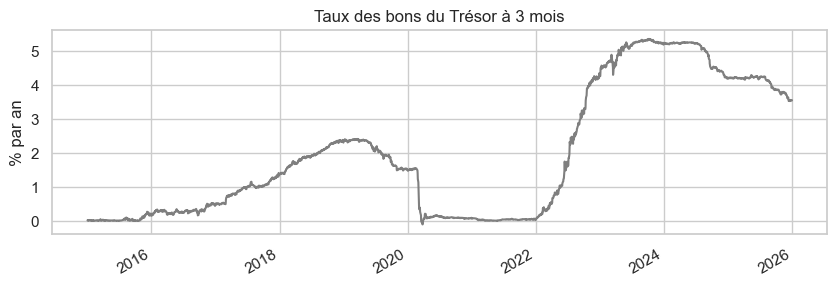

In [5]:
# Taux annuel en décimal, aligné sur les jours de bourse (dernière valeur connue si absente)
taux_annuel = prix_bruts[TAUX].reindex(prix.index).ffill() / 100
# Taux journalier composé, décalé d'un jour : seul le taux de la veille est connu
taux_journalier = ((1 + taux_annuel) ** (1 / JOURS_PAR_AN) - 1).shift(1).rename("rf")

fig, ax = plt.subplots(figsize=(10, 3))
(taux_annuel * 100).plot(ax=ax, color="tab:gray")
ax.set(title="Taux des bons du Trésor à 3 mois", ylabel="% par an", xlabel="")
plt.show()

**Observations.** Le taux annuel varie entre −0,1 % et 5,3 % sur la période :
- proche de 0 % en 2015, puis hausse progressive jusqu'à environ 2,4 % début 2019 ;
- retour vers 0 % de mars 2020 à début 2022, avec 7 valeurs légèrement négatives en mars 2020 ;
- hausse rapide en 2022–2023 jusqu'à 5,3 % (octobre 2023), puis baisse vers 3,5 % fin 2025.

En moyenne, le taux sans risque représente environ 1,9 % par an sur la période.

**Contexte** (information extérieure aux données). Ces phases suivent la politique monétaire de la Réserve fédérale : remontée progressive des taux en 2016–2018, baisse d'urgence lors de la crise du Covid-19, puis resserrement rapide face à l'inflation en 2022–2023.

**Conséquence.** Le taux sans risque n'est pas constant : la même performance d'une action n'a pas la même valeur relative en 2021 (taux ≈ 0 %) et en 2023 (taux ≈ 5 %). Les étapes suivantes utiliseront donc la série journalière `rf`, et non une valeur moyenne fixe.

## 5. Rendements journaliers

**Définition.** Rendement simple : $r_t = \dfrac{P_t}{P_{t-1}} - 1$, où $P_t$ est le prix ajusté de clôture du jour *t*.

**Choix du rendement simple plutôt que logarithmique.** Le rendement d'un portefeuille est exactement la moyenne pondérée des rendements simples des actifs qui le composent, propriété utilisée aux étapes suivantes et que n'ont pas les rendements logarithmiques. En contrepartie, les rendements simples ne s'additionnent pas dans le temps : le rendement sur plusieurs jours s'obtient par composition, $\prod_t (1 + r_t) - 1$.

**Contrôle de qualité.** Les rendements supérieurs à 30 % en valeur absolue sont listés puis vérifiés : ils peuvent signaler une erreur de données (prix aberrant, division d'actions mal ajustée).

In [6]:
rendements = prix.pct_change().iloc[1:]       # le premier jour n'a pas de rendement
# Alignement du taux sans risque sur les dates des rendements
taux_journalier = taux_journalier.reindex(rendements.index).fillna(0)

# Contrôle de qualité : rendements journaliers supérieurs à 30 % en valeur absolue
extremes = rendements.stack()
extremes = extremes[extremes.abs() > 0.30]
print(rendements.shape)
print("Rendements journaliers au-delà de ±30 % :")
print(extremes.sort_values() if len(extremes) else "aucun")

(2765, 40)
Rendements journaliers au-delà de ±30 % :
Date            
2025-09-10  ORCL   0.3595
dtype: float64


**Résultat.** La base compte 2 765 rendements journaliers (le premier jour est perdu par construction) pour 40 séries. Un seul rendement dépasse 30 % en valeur absolue : **ORCL, +36,0 % le 10/09/2025**. Il correspond à un mouvement de marché réel, la réaction du cours à la publication des résultats trimestriels d'Oracle, et non à une erreur de données : il est conservé.

## 6. Analyse exploratoire

Cette section examine trois propriétés des rendements qui conditionnent le choix des méthodes de mesure du risque : la forme de leur distribution (§ 6.1–6.2), la dépendance entre actions (§ 6.3) et la stabilité de la volatilité dans le temps (§ 6.4).

### 6.1 Statistiques descriptives et test de normalité

Les statistiques sont calculées pour chaque série sur l'ensemble de la période.

| Colonne | Définition |
|---|---|
| `rendement_annuel` | rendement annualisé composé : $\left(\prod_t (1+r_t)\right)^{252/n} - 1$ |
| `volatilite_annuelle` | écart-type des rendements journaliers × $\sqrt{252}$ |
| `asymetrie` | coefficient d'asymétrie (*skewness*) ; 0 pour une loi normale |
| `kurtosis_exces` | kurtosis en excès ; 0 pour une loi normale, positif si les valeurs extrêmes sont plus fréquentes |
| `pire_jour`, `meilleur_jour` | plus petit et plus grand rendement journalier observés |
| `p_jarque_bera` | p-valeur du test de normalité de Jarque-Bera |

**Annualisation de la volatilité.** Le facteur $\sqrt{252}$ suppose des rendements journaliers indépendants et de même loi : leurs variances s'additionnent alors d'un jour à l'autre. Comme le § 6.4 montre que la volatilité varie dans le temps, la volatilité annualisée doit être lue comme une **moyenne sur la période**, et non comme un niveau de risque constant.

**Test de Jarque-Bera.**
- Hypothèse nulle H₀ : les rendements journaliers suivent une loi normale.
- Statistique : $JB = \dfrac{n}{6}\left(S^2 + \dfrac{K^2}{4}\right)$, où $S$ est l'asymétrie et $K$ le kurtosis en excès.
- Sous H₀, $JB$ suit asymptotiquement une loi du $\chi^2$ à 2 degrés de liberté, dont la p-valeur vaut exactement $e^{-JB/2}$.
- Décision : rejet de H₀ au seuil de 5 % si p < 0,05.

**Intérêt du test.** Plusieurs outils classiques, comme la VaR paramétrique gaussienne ou le résumé du risque par la seule volatilité, supposent des rendements normaux. Le test vérifie si cette hypothèse est tenable avant de les utiliser.

In [7]:
def statistiques(r):
    n = r.count()                                 # nombre de rendements par série
    s = r.skew()                                  # asymétrie
    k = r.kurt()                                  # kurtosis en excès
    jb = n / 6 * (s**2 + k**2 / 4)                # statistique de Jarque-Bera
    return pd.DataFrame({
        "secteur": [SECTEUR_DE.get(t, "Référence") for t in r.columns],
        "rendement_annuel": (1 + r).prod() ** (JOURS_PAR_AN / n) - 1,
        "volatilite_annuelle": r.std() * np.sqrt(JOURS_PAR_AN),
        "asymetrie": s,
        "kurtosis_exces": k,
        "pire_jour": r.min(),
        "meilleur_jour": r.max(),
        "p_jarque_bera": np.exp(-jb / 2),          # P(khi-deux à 2 ddl > jb) = exp(-jb/2)
    }, index=r.columns)

# Tri par volatilité décroissante
stats = statistiques(rendements).sort_values("volatilite_annuelle", ascending=False)
stats

,secteur,rendement_annuel,volatilite_annuelle,asymetrie,kurtosis_exces,pire_jour,meilleur_jour,p_jarque_bera
NVDA,Technologie,0.7209,0.4869,0.5588,8.2747,-0.1876,0.2981,0.0000
BA,Industrie,0.0608,0.4005,0.2397,15.9493,-0.2385,0.2432,0.0000
META,Communication,0.2150,0.3753,-0.2420,20.6765,-0.2639,0.2328,0.0000
ADBE,Technologie,0.1545,0.3296,-0.4077,9.6438,-0.1679,0.1772,0.0000
AMZN,Consommation cyclique,0.2796,0.3293,0.4149,6.1892,-0.1405,0.1413,0.0000
ORCL,Technologie,0.1619,0.3212,2.4225,46.9320,-0.1379,0.3595,0.0000
NKE,Consommation cyclique,0.0401,0.3102,-0.0446,13.7416,-0.1998,0.1553,0.0000
BAC,Finance,0.1313,0.3075,0.2074,9.9845,-0.1540,0.1780,0.0000
CAT,Industrie,0.2123,0.2997,-0.0711,4.5668,-0.1428,0.1163,0.0000
CVX,Énergie,0.0732,0.2914,-0.2553,23.0421,-0.2212,0.2274,0.0000


**Observations.**
- **Rendement et volatilité.** Les rendements annualisés vont de 2,6 % (PFE) à 72,1 % (NVDA), contre 13,5 % pour SPY. Les volatilités vont de 17,8 % (KO) à 48,7 % (NVDA). SPY (17,8 %) est presque aussi peu volatil que KO, l'action la moins volatile, alors qu'il est composé d'actions individuellement plus risquées : c'est l'effet de la diversification.
- **Plus de risque ne garantit pas plus de rendement.** Sur les 39 actions, rendement et volatilité sont positivement corrélés (0,62), mais avec des exceptions marquées : BA a la deuxième volatilité la plus élevée (40,1 %) pour un rendement de 6,1 % par an.
- **Normalité.** Le kurtosis en excès va de 4,6 (CAT) à 46,9 (ORCL) : il est nettement positif pour les 40 séries. La p-valeur de Jarque-Bera est inférieure à 10⁻⁴ partout (affichée 0,0000) : **la normalité est rejetée pour toutes les séries**.
- **Asymétrie.** Elle est faible et de signe variable (19 valeurs négatives sur 40), entre −1,06 (UNH) et +0,56 (NVDA), à l'exception d'ORCL (+2,42). L'écart à la normalité vient donc surtout du kurtosis, c'est-à-dire des queues épaisses.

**Interprétation.** Les jours de forte variation sont beaucoup plus fréquents que ne le prévoit une loi normale de même moyenne et de même écart-type. Une mesure du risque fondée sur la seule volatilité, ou une VaR gaussienne, **sous-estimerait la probabilité des pertes extrêmes**.

**Précautions.**
- Avec environ 2 765 observations par série, le test rejette même de petits écarts à la normalité. Ici, les écarts sont importants (kurtosis d'au moins 4,6) : la conclusion ne tient pas à la seule taille de l'échantillon.
- Le test suppose des observations indépendantes, hypothèse contredite par la variation de la volatilité dans le temps (§ 6.4). Les p-valeurs sont donc approximatives, mais l'ampleur des écarts rend la conclusion robuste.
- Les moments d'ordre 3 et 4 sont très sensibles à quelques observations. Sans la séance du 10/09/2025, le kurtosis d'ORCL passe de 46,9 à 15,0 et son asymétrie de 2,42 à 0,51.
- Les rendements annualisés sont des **performances passées**, mesurées sur un univers soumis au biais de survie (§ 8) : ce ne sont pas des estimations des rendements futurs.

### 6.2 Forme de la distribution

Les histogrammes comparent la distribution observée des rendements journaliers de six séries (le marché et cinq actions de secteurs différents) à la densité d'une loi normale de même moyenne et de même écart-type.

**Note de lecture.** L'axe horizontal est limité à ±12 %. Les rendements situés au-delà ne sont pas affichés : 18 jours pour NVDA, 4 pour JPM, 3 pour XOM, 2 pour AAPL. Les histogrammes sous-représentent donc les queues de distribution ; le comptage de la cellule suivante les prend en compte.

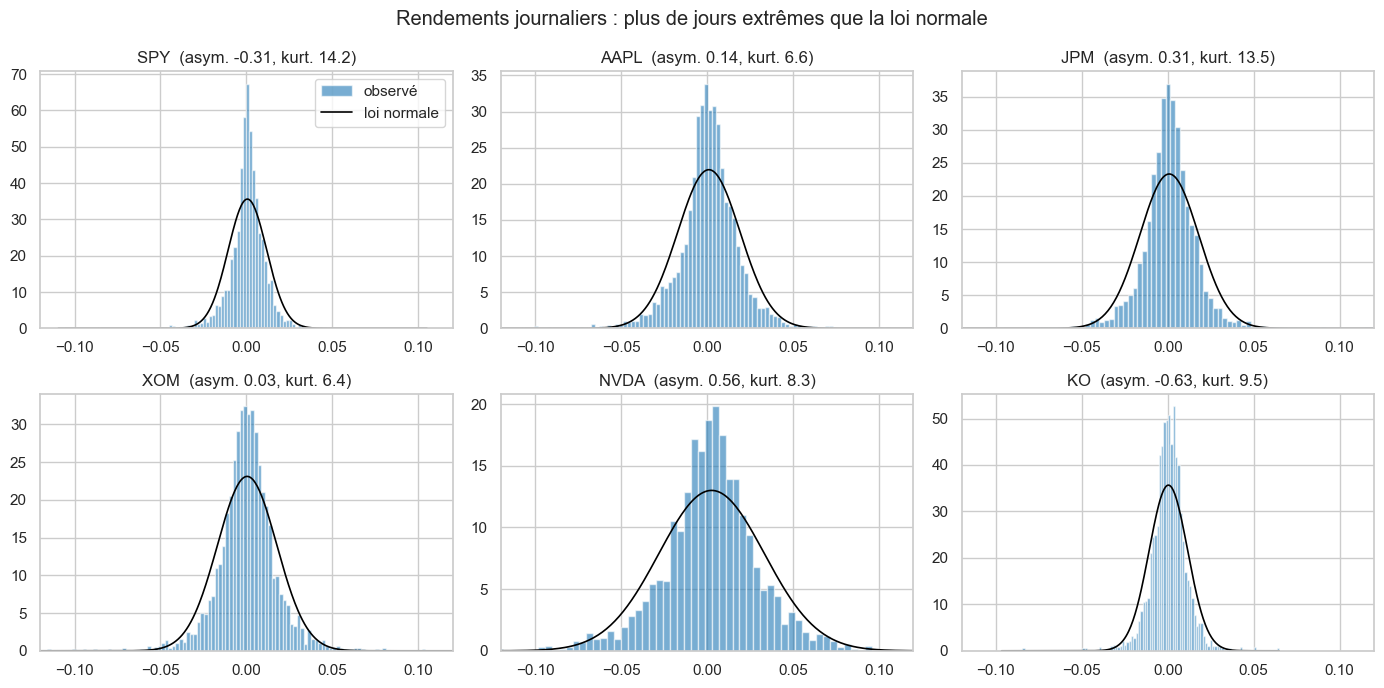

In [8]:
# Histogramme des rendements et densité normale de même moyenne et de même écart-type
def histogramme(ax, r, nom):
    mu, sigma = r.mean(), r.std()
    ax.hist(r, bins=120, density=True, color="tab:blue", alpha=0.6, label="observé")
    x = np.linspace(r.min(), r.max(), 400)
    ax.plot(x, np.exp(-((x - mu) ** 2) / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)),
            color="black", lw=1.2, label="loi normale")
    # Axe limité à ±12 % : les rendements plus extrêmes ne sont pas affichés
    ax.set(title=f"{nom}  (asym. {r.skew():.2f}, kurt. {r.kurt():.1f})", xlim=(-0.12, 0.12))

# Le marché et cinq actions de secteurs différents
exemples = [REFERENCE, "AAPL", "JPM", "XOM", "NVDA", "KO"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, t in zip(axes.flat, exemples):
    histogramme(ax, rendements[t], t)
axes[0, 0].legend()
fig.suptitle("Rendements journaliers : plus de jours extrêmes que la loi normale")
plt.tight_layout()
plt.show()

**Lecture.** Pour les six séries, la distribution observée est plus concentrée autour de 0 que la loi normale (pic plus haut et plus étroit), avec moins de rendements intermédiaires et davantage de rendements extrêmes. Par exemple, pour SPY, 54,7 % des jours sont à moins d'un demi-écart-type de la moyenne (38,3 % sous la loi normale), et 16,1 % entre 1 et 2 écarts-types (27,2 % sous la loi normale). C'est la forme caractéristique d'une distribution à kurtosis en excès positif (*leptokurtique*).

In [9]:
# Fréquence des rendements à plus de 3 écarts-types de la moyenne, comparée à la loi normale (0,27 %)
z = (rendements - rendements.mean()) / rendements.std()
freq_3sigma = (z.abs() > 3).mean().sort_values(ascending=False) * 100
print(f"Loi normale : 0.27 % des jours. Observé, en moyenne : {freq_3sigma.mean():.2f} %")
freq_3sigma.head(10).round(2)

Loi normale : 0.27 % des jours. Observé, en moyenne : 1.47 %


NEE    1.7700
MRK    1.6600
COST   1.6600
CSCO   1.6600
PG     1.6600
V      1.6600
BAC    1.6300
AMZN   1.5900
NKE    1.5900
UNH    1.5900
dtype: float64

**Résultat.** Sous une loi normale, 0,27 % des jours devraient s'écarter de plus de 3 écarts-types de la moyenne. On en observe en moyenne 1,47 %, de 1,08 % (CVX) à 1,77 % (NEE), soit **environ 5 fois plus** que prévu. Pour SPY, 1,41 % des jours, soit 39 séances, sont dans ce cas.

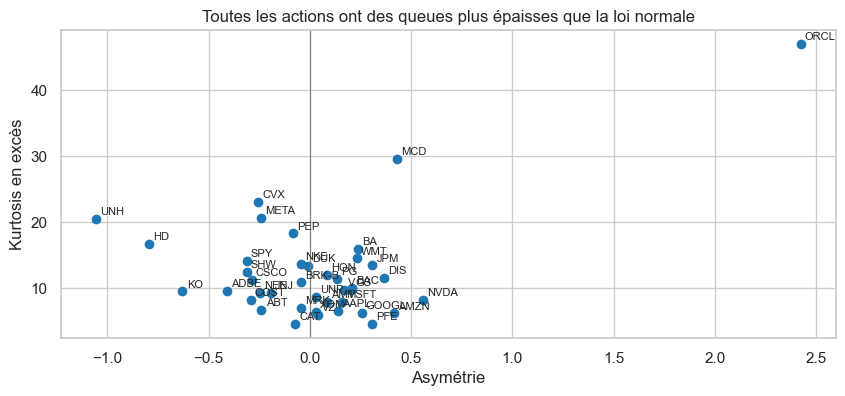

In [10]:
# Un point par série : sous la loi normale, tous les points seraient proches de (0, 0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(stats["asymetrie"], stats["kurtosis_exces"], color="tab:blue")
for t, ligne in stats.iterrows():
    ax.annotate(t, (ligne["asymetrie"], ligne["kurtosis_exces"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axvline(0, color="gray", lw=0.8)
ax.set(xlabel="Asymétrie", ylabel="Kurtosis en excès", title="Toutes les actions ont des queues plus épaisses que la loi normale")
plt.show()

**Lecture.** Tous les points sont nettement au-dessus de l'axe horizontal (kurtosis d'au moins 4,6), et la plupart restent proches de l'axe vertical (asymétrie entre −1,1 et +0,6). Deux séries s'écartent du nuage : ORCL, sous l'effet d'une seule séance exceptionnelle (§ 6.1), et MCD (kurtosis 29,6).

Un kurtosis élevé ne signifie pas une volatilité élevée : MCD et PEP font partie des actions les moins volatiles (environ 19–20 % par an) mais ont des kurtosis parmi les plus élevés. La volatilité mesure l'amplitude habituelle des variations ; le kurtosis mesure la fréquence relative des variations exceptionnelles.

**Conclusion des § 6.1 et 6.2.** Les rendements journaliers ne suivent pas une loi normale, principalement en raison de queues épaisses. Cela justifie de compléter la volatilité par des mesures de risque fondées sur la distribution observée des pertes, comme la **VaR et la CVaR historiques**, qui ne supposent aucune loi particulière.

### 6.3 Corrélations entre actions

La matrice de corrélation des rendements journaliers des 39 actions (SPY exclu) mesure à quel point les actions évoluent ensemble. Plus les corrélations sont élevées, plus le gain de diversification d'un portefeuille est faible. Les actions sont ordonnées par secteur pour faire apparaître d'éventuels blocs sectoriels.

Ce sont des corrélations linéaires (Pearson) calculées sur toute la période : elles décrivent une dépendance moyenne, dont l'évolution dans le temps est examinée ensuite.

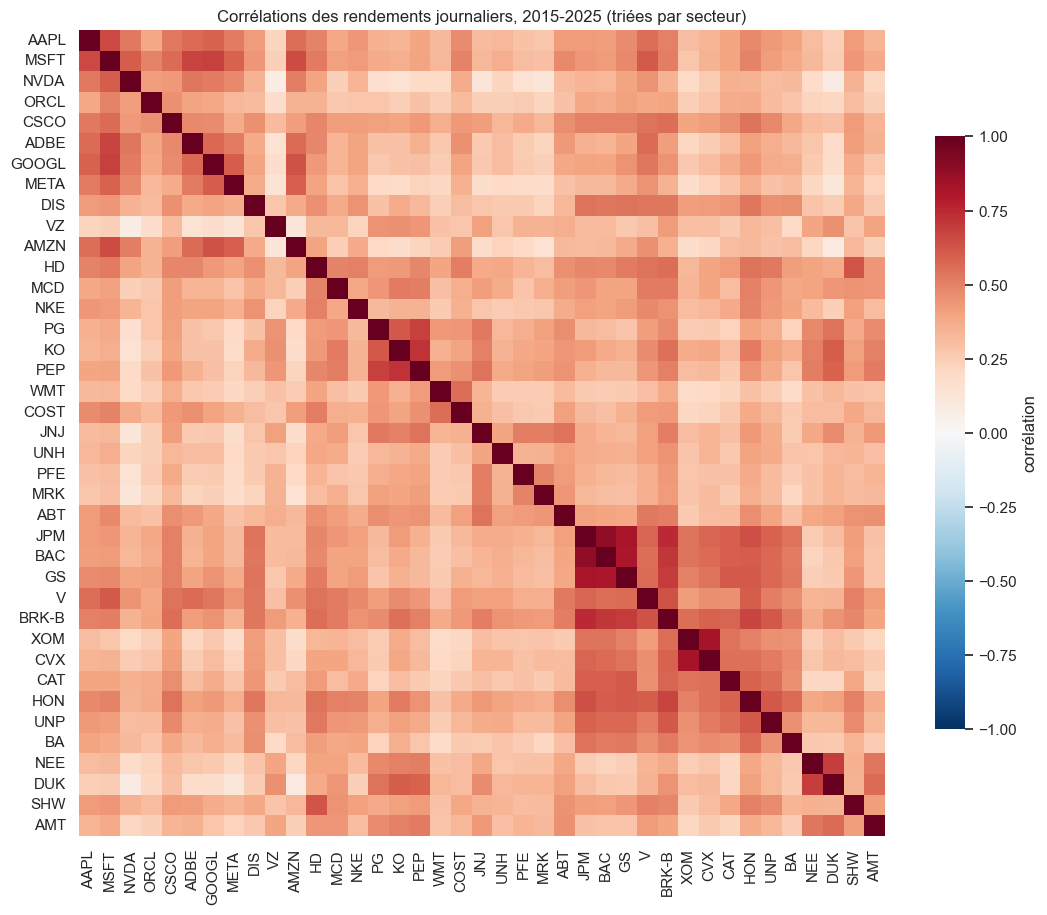

Corrélation moyenne entre deux actions : 0.38
Paires les plus corrélées :
JPM  BAC     0.8800
XOM  CVX     0.8300
JPM  GS      0.8300
BAC  GS      0.8200
JPM  BRK-B   0.7500
dtype: float64
Paires les moins corrélées :
NVDA  VZ    0.0700
      DUK   0.0800
AMZN  DUK   0.0900
META  DUK   0.1200
NVDA  JNJ   0.1300
dtype: float64


In [11]:
correlation = rendements[ACTIONS].corr()   # actions seules, dans l'ordre des secteurs

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(correlation, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.7, "label": "corrélation"}, ax=ax)
ax.set_title("Corrélations des rendements journaliers, 2015-2025 (triées par secteur)")
plt.show()

# Triangle supérieur strict : chaque paire d'actions est comptée une seule fois
triangle = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
print(f"Corrélation moyenne entre deux actions : {triangle.mean():.2f}")
print("Paires les plus corrélées :")
print(triangle.sort_values(ascending=False).head(5).round(2))
print("Paires les moins corrélées :")
print(triangle.sort_values().head(5).round(2))

**Observations.**
- La corrélation moyenne entre deux actions est de **0,38**. Toutes les paires sont positivement corrélées (minimum 0,07), signe d'une influence commune du marché.
- Les corrélations sont plus fortes à l'intérieur d'un même secteur (moyenne **0,52**) qu'entre secteurs différents (**0,37**), ce qui se traduit par des blocs sur la diagonale de la matrice. Les quatre paires les plus corrélées sont intra-sectorielles : JPM–BAC (0,88), XOM–CVX (0,83), JPM–GS (0,83), BAC–GS (0,82).
- Les paires les moins corrélées associent une action technologique ou de commerce en ligne (NVDA, AMZN, META) à une action des télécommunications, des services publics ou de la santé : NVDA–VZ (0,07), NVDA–DUK (0,08), AMZN–DUK (0,09).

**Interprétation.** Diversifier entre secteurs réduit davantage le risque que diversifier au sein d'un secteur. Aucune paire n'étant négativement corrélée, la diversification entre ces actions atténue le risque sans pouvoir le compenser.

#### Évolution de la corrélation dans le temps

Pour vérifier si la dépendance entre actions est stable, la corrélation moyenne entre toutes les paires est recalculée sur une fenêtre glissante de 63 jours. Les zones colorées signalent deux périodes de forte baisse du marché : le krach du Covid-19 (20 février – 30 avril 2020) et le marché baissier de 2022.

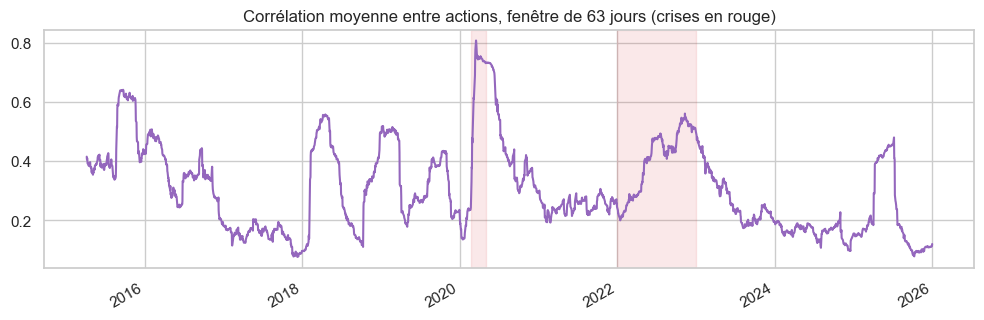

In [12]:
# Corrélation moyenne entre toutes les paires d'actions, sur une fenêtre glissante de 63 jours
def correlation_moyenne(r):
    c = r.corr().to_numpy()
    return c[np.triu_indices_from(c, k=1)].mean()

correl_glissante = pd.Series(
    [correlation_moyenne(rendements[ACTIONS].iloc[i - FENETRE_VOL:i]) for i in range(FENETRE_VOL, len(rendements) + 1)],
    index=rendements.index[FENETRE_VOL - 1:],
)

fig, ax = plt.subplots(figsize=(12, 3.5))
correl_glissante.plot(ax=ax, color="tab:purple")
# Périodes de forte baisse du marché : krach du Covid-19 et marché baissier de 2022
for debut, fin in [("2020-02-20", "2020-04-30"), ("2022-01-01", "2022-12-31")]:
    ax.axvspan(debut, fin, color="tab:red", alpha=0.1)
ax.set(title="Corrélation moyenne entre actions, fenêtre de 63 jours (crises en rouge)", xlabel="")
plt.show()

**Observations.** La corrélation moyenne glissante varie de 0,08 (décembre 2017) à **0,81 (16 mars 2020)**, avec une médiane de 0,28. Le maximum coïncide avec le krach du Covid-19. En 2022, la hausse est plus modérée : la moyenne annuelle (0,40) est comparable à celle de 2015 (0,47).

**Interprétation.** La dépendance entre actions n'est pas stable. Lors du choc de mars 2020, les actions ont baissé ensemble et la diversification a le moins protégé au moment où elle aurait été la plus utile. Ce constat repose toutefois sur un seul épisode extrême : l'année 2022 montre qu'une période de baisse ne s'accompagne pas toujours d'une hausse comparable des corrélations.

**Conséquence.** Une matrice de corrélation estimée sur toute la période sous-estime la dépendance lors des chocs de marché. Il faudra en tenir compte pour évaluer le risque des portefeuilles.

### 6.4 Volatilité

Deux questions sont examinées : quelles actions sont les plus volatiles sur l'ensemble de la période, et la volatilité est-elle stable dans le temps ?

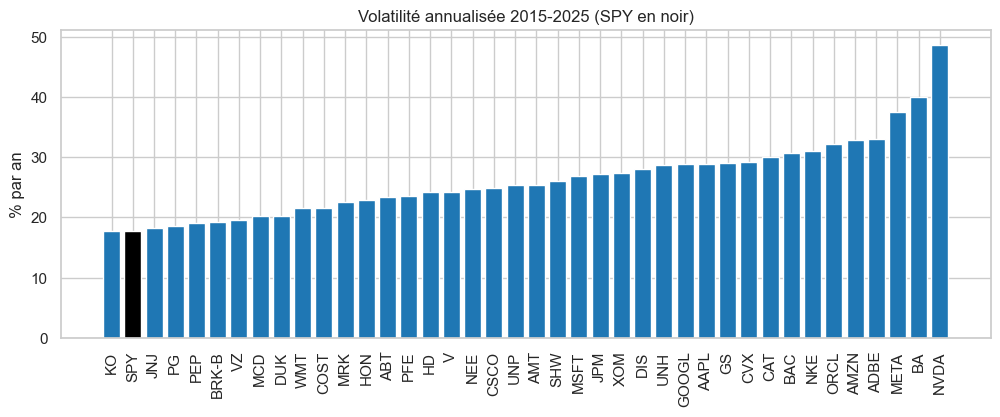

secteur
Référence               0.1780
Consommation de base    0.1970
Services publics        0.2250
Santé                   0.2330
Immobilier              0.2540
Matériaux               0.2600
Finance                 0.2610
Consommation cyclique   0.2710
Énergie                 0.2830
Communication           0.2850
Industrie               0.2960
Technologie             0.3240
Name: volatilite_annuelle, dtype: float64

In [13]:
# Volatilité annualisée sur toute la période, SPY en noir
vol = stats["volatilite_annuelle"].sort_values()
couleurs = ["black" if t == REFERENCE else "tab:blue" for t in vol.index]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(vol.index, vol * 100, color=couleurs)
ax.set(ylabel="% par an", title="Volatilité annualisée 2015-2025 (SPY en noir)")
ax.tick_params(axis="x", rotation=90)
plt.show()

# Moyenne simple des volatilités des actions de chaque secteur
stats.groupby("secteur")["volatilite_annuelle"].mean().sort_values().round(3)

**Observations.** La volatilité annualisée va de 17,8 % (KO) à 48,7 % (NVDA). En moyenne par secteur, la consommation de base (19,7 %) et les services publics (22,5 %) sont les moins volatils, la technologie (32,4 %) la plus volatile.

**Précautions.** La moyenne sectorielle est une moyenne simple des volatilités individuelles, et non la volatilité d'un portefeuille sectoriel, qui serait plus faible grâce à la diversification. Plusieurs secteurs ne comptent qu'une ou deux actions (Matériaux et Immobilier : une ; Énergie et Services publics : deux) : leur moyenne reflète ces actions particulières et ne peut pas être généralisée au secteur.

#### Évolution de la volatilité dans le temps

La volatilité est réestimée sur une fenêtre glissante de 63 jours, puis annualisée, pour SPY et trois actions aux profils différents : NVDA (technologie, très volatile), XOM (énergie) et KO (consommation de base, peu volatile).

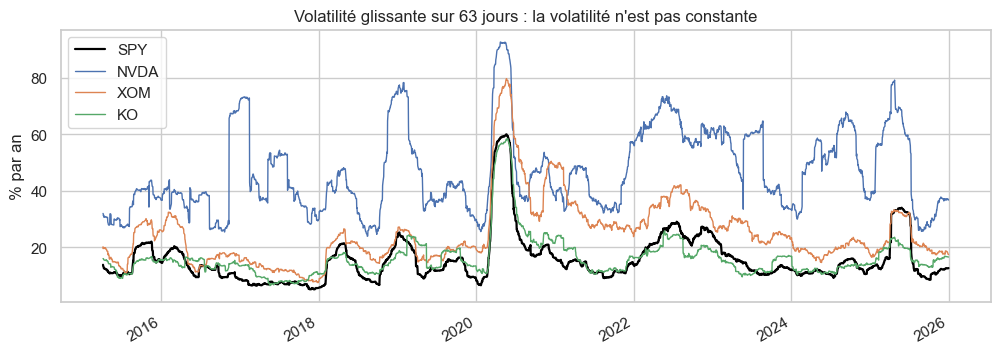

In [14]:
# Volatilité sur 63 jours glissants, annualisée
vol_glissante = rendements.rolling(FENETRE_VOL).std() * np.sqrt(JOURS_PAR_AN)

fig, ax = plt.subplots(figsize=(12, 4))
for t in [REFERENCE, "NVDA", "XOM", "KO"]:
    (vol_glissante[t] * 100).plot(ax=ax, lw=1.6 if t == REFERENCE else 1, label=t,
                                  color="black" if t == REFERENCE else None)
ax.set(ylabel="% par an", xlabel="", title="Volatilité glissante sur 63 jours : la volatilité n'est pas constante")
ax.legend()
plt.show()

**Observations.** La volatilité varie fortement dans le temps pour les quatre séries. Celle de SPY passe d'un minimum de 5,1 % (décembre 2017) à un maximum de 60 % (mai 2020) ; celle de KO, de 6,5 % à 58,5 %. Les quatre séries atteignent leur maximum au printemps 2020 : ce choc a touché toutes les actions en même temps. Visuellement, les périodes agitées sont regroupées dans le temps (*volatility clustering*), un phénomène qui n'est pas testé formellement ici.

**Note de lecture.** Les maximums sont atteints en avril–mai 2020, après le pic du krach de mars : une fenêtre de 63 jours réagit avec retard et garde la trace d'un choc pendant toute sa durée.

**Interprétation.** Une volatilité unique estimée sur 11 ans ne représente le risque d'aucune période particulière. Le mélange de périodes calmes et agitées est aussi une explication possible des queues épaisses observées au § 6.1 (hypothèse non testée ici).

**Conséquence.** Mesurer le risque à une date donnée nécessite une estimation sur fenêtre glissante, ou un modèle à volatilité variable.

## 7. Sauvegarde

Les quatre fichiers de sortie sont enregistrés dans `data/` et servent d'entrée aux étapes suivantes. `prix_bruts.csv` y figure déjà en tant que cache.

In [15]:
# Fichiers d'entrée des étapes suivantes
prix.to_csv(DOSSIER / "prix_nettoyes.csv")
rendements.to_csv(DOSSIER / "rendements.csv")
taux_journalier.to_frame().to_csv(DOSSIER / "taux_sans_risque.csv")
pd.Series(SECTEUR_DE, name="secteur").rename_axis("ticker").loc[ACTIONS].to_csv(DOSSIER / "secteurs.csv")

# Contrôle : fichiers produits et taille
for f in sorted(DOSSIER.glob("*.csv")):
    print(f"{f.name:25s} {f.stat().st_size / 1e6:.1f} Mo")

mesures_references.csv    0.0 Mo
prix_bruts.csv            2.1 Mo
prix_nettoyes.csv         2.0 Mo
rendements.csv            2.4 Mo
rendements_references.csv 0.2 Mo
secteurs.csv              0.0 Mo
taux_sans_risque.csv      0.1 Mo


## 8. Synthèse et limites

**Données.** 39 actions et SPY, 2 766 jours de bourse (2 765 rendements) du 02/01/2015 au 31/12/2025. Aucune valeur manquante : aucune action écartée, aucun prix reporté, aucune date supprimée. Un seul rendement dépasse 30 % en valeur absolue (ORCL, +36 % le 10/09/2025) ; il est vérifié et conservé.

**Principaux résultats.**

| Propriété | Résultat | Conséquence méthodologique |
|---|---|---|
| Distribution | normalité rejetée pour les 40 séries ; kurtosis en excès de 4,6 à 46,9 ; écarts de plus de 3 écarts-types environ 5 fois plus fréquents que sous la loi normale | compléter la volatilité par la VaR et la CVaR historiques |
| Dépendance | corrélation moyenne de 0,38 ; plus forte au sein d'un secteur (0,52) qu'entre secteurs (0,37) ; jusqu'à 0,81 en mars 2020 sur fenêtre glissante | diversifier entre secteurs ; ne pas se fier à la corrélation moyenne lors des chocs de marché |
| Volatilité | de 17,8 % (KO) à 48,7 % (NVDA) sur la période ; très variable dans le temps (SPY : de 5 % à 60 %) | estimer le risque sur fenêtre glissante |
| Taux sans risque | de −0,1 % à 5,3 % par an ; 1,9 % en moyenne | utiliser la série journalière `rf`, et non une valeur fixe |

**Limites.**
- **Biais de survie et de sélection.** Les 39 actions sont choisies parmi les grandes entreprises actuelles, c'est-à-dire parmi celles qui ont réussi sur la période ; les entreprises qui ont chuté ou disparu depuis 2015 sont absentes. Les rendements absolus (par exemple 72 % par an pour NVDA) sont donc surestimés et ne doivent pas être lus comme des rendements attendus. Les méthodes pourront être comparées entre elles, mais toutes seront évaluées sur ce même univers favorable : leurs performances absolues seront optimistes.
- **Univers restreint.** 39 grandes entreprises américaines ; plusieurs secteurs ne sont représentés que par une ou deux actions.
- **Hypothèses statistiques.** L'annualisation par $\sqrt{252}$ et le test de Jarque-Bera supposent des rendements indépendants, hypothèse contredite par la variation de la volatilité dans le temps.
- **Taux sans risque.** Approximé à partir d'un taux d'escompte annualisé (`^IRX`).

# Étape 2 — Mesures de performance et de risque

**Objectif.** Coder les mesures qui serviront à comparer tous les portefeuilles du projet, puis les appliquer à deux références : le portefeuille équipondéré des 39 actions et SPY.

**Mesures.**

| Mesure | Ce qu'elle résume |
|---|---|
| Rendement annualisé | croissance moyenne du capital, par an |
| Volatilité annualisée | amplitude habituelle des variations |
| Ratio de Sharpe | rendement excédentaire obtenu par unité de volatilité |
| Max drawdown | pire perte cumulée, d'un sommet au creux suivant |
| VaR historique | perte journalière dépassée seulement dans 5 % (ou 1 %) des cas |
| CVaR historique | perte journalière moyenne lors de ces jours les plus défavorables |

**Références.**
- **Portefeuille équipondéré** (1/39 dans chaque action) : la règle d'allocation la plus simple, qui n'estime aucun paramètre. Une méthode d'optimisation des étapes suivantes n'est utile que si elle fait mieux que cette référence naïve.
- **SPY** : le marché américain dans son ensemble (pondéré par les capitalisations).

**Entrées** : les rendements journaliers (§ 5) et le taux sans risque journalier (§ 4) construits à l'étape 1, déjà en mémoire.

**Sorties** : `data/rendements_references.csv` (rendements journaliers des deux références) et `data/mesures_references.csv` (tableau des mesures).

## 9. Paramètres de l'étape 2

| Paramètre | Valeur | Justification |
|---|---|---|
| `JOURS_PAR_AN` | 252 | même convention d'annualisation qu'à l'étape 1 (§ 1) |
| `NIVEAUX` | 95 %, 99 % | niveaux de confiance usuels de la VaR ; 99 % décrit des pertes plus rares, mais repose sur environ 28 observations seulement |

La VaR et la CVaR sont calculées à **horizon d'un jour** et exprimées en **% de la valeur du portefeuille**, comme des pertes (nombres positifs). Elles ne sont pas annualisées : la règle « × √h » supposerait des rendements indépendants et de même loi, hypothèse rejetée au § 6.1.

In [16]:
from statistics import NormalDist

NIVEAUX = [0.95, 0.99]        # niveaux de confiance de la VaR et de la CVaR
EQUI = "Équipondéré"
rf = taux_journalier          # taux sans risque journalier du § 4

# Contrôle : mêmes dates pour les rendements et le taux sans risque, aucune valeur manquante
assert rendements.index.equals(rf.index)
assert rendements.notna().all().all() and rf.notna().all()
print(f"{len(ACTIONS)} actions + {REFERENCE} | {len(rendements)} jours, "
      f"du {rendements.index[0]:%d/%m/%Y} au {rendements.index[-1]:%d/%m/%Y}")

39 actions + SPY | 2765 jours, du 05/01/2015 au 31/12/2025


## 10. Portefeuille équipondéré

**Construction.** Le poids de chaque action est fixé à $w_i = 1/39$ **chaque jour** : le portefeuille est rééquilibré quotidiennement. Son rendement journalier est alors la moyenne simple des rendements des actions :

$$r_t^{EW} = \sum_{i=1}^{39} \frac{1}{39}\, r_{i,t}$$

Cette égalité est exacte parce que les rendements sont simples (choix justifié au § 5).

**Pourquoi un rééquilibrage quotidien.** Sans rééquilibrage (stratégie *buy and hold*), les poids dérivent avec les prix : les actions qui montent prennent une part croissante du portefeuille, qui cesse d'être équipondéré. La cellule suivante mesure l'ampleur de cette dérive.

**Hypothèse.** Aucun coût de transaction n'est pris en compte. En pratique, un rééquilibrage mensuel ou trimestriel donnerait des résultats proches pour un coût bien plus faible.

In [17]:
poids = pd.Series(1 / len(ACTIONS), index=ACTIONS)
assert np.isclose(poids.sum(), 1)

# Rendements des deux références
r_ref = pd.DataFrame({
    EQUI: rendements[ACTIONS] @ poids,     # rééquilibré chaque jour à 1/39
    REFERENCE: rendements[REFERENCE],
})

# Variante sans rééquilibrage : 1/39 investi au départ, puis les poids dérivent avec les prix
valeur_actions = (1 + rendements[ACTIONS]).cumprod()
poids_finaux = (valeur_actions.iloc[-1] / valeur_actions.iloc[-1].sum()).sort_values(ascending=False)
print("Poids au 31/12/2025 sans rééquilibrage (5 plus élevés) :")
print((poids_finaux.head(5) * 100).round(1).astype(str) + " %")

Poids au 31/12/2025 sans rééquilibrage (5 plus élevés) :
NVDA     68.6 %
AMZN      2.7 %
MSFT      2.2 %
GOOGL     2.1 %
AAPL      2.0 %
Name: 2025-12-31 00:00:00, dtype: object


**Résultat.** Sans rééquilibrage, NVDA représenterait **68,6 %** du portefeuille fin 2025 (contre 2,6 % au départ), et aucune autre action ne dépasserait 2,7 %. Le portefeuille serait devenu un placement concentré sur une seule action, sans rapport avec la référence équipondérée recherchée. Le rééquilibrage quotidien est donc indispensable pour que la référence garde son sens tout au long des 11 ans.

## 11. Définition des mesures

Notations : $r_t$ rendement simple du jour *t*, $r_{f,t}$ taux sans risque journalier (§ 4), $n$ nombre de jours, $V_t = \prod_{s \le t}(1 + r_s)$ valeur d'un placement de 1 au départ ($V_0 = 1$).

| Mesure | Formule | Remarques |
|---|---|---|
| Rendement annualisé | $\left(\prod_t (1+r_t)\right)^{252/n} - 1$ | rendement composé : c'est le taux annuel constant qui mène à la même valeur finale |
| Volatilité annualisée | $\hat\sigma(r_t) \times \sqrt{252}$ | même définition qu'à l'étape 1 ; une **moyenne** sur la période, car la volatilité varie dans le temps |
| Ratio de Sharpe | $\dfrac{\overline{r_t - r_{f,t}}}{\hat\sigma(r_t - r_{f,t})} \times \sqrt{252}$ | calculé sur les rendements **excédentaires** journaliers, avec la série `rf` du jour (et non un taux moyen fixe) |
| Max drawdown | $\min_t \left( \dfrac{V_t}{\max_{s \le t} V_s} - 1 \right)$ | pire baisse depuis un sommet antérieur ; négatif par convention |
| VaR historique à $\alpha$ | $-q_{1-\alpha}(r_t)$ | $q_{1-\alpha}$ : quantile empirique d'ordre $1-\alpha$ des rendements journaliers |
| CVaR historique à $\alpha$ | $-\,\text{moyenne}\{ r_t : r_t \le q_{1-\alpha} \}$ | perte moyenne au-delà de la VaR ; aussi appelée *Expected Shortfall* |

**Choix méthodologiques.**
- **Sharpe arithmétique.** Le numérateur est une moyenne arithmétique des rendements excédentaires, ce qui est la définition usuelle. Il n'est donc pas égal à (rendement annualisé composé − taux sans risque) / volatilité : la moyenne arithmétique dépasse le rendement composé d'environ $\sigma^2/2$.
- **VaR et CVaR historiques.** Elles utilisent directement la distribution observée des rendements, sans supposer de loi. C'est la conséquence du § 6 : la normalité est rejetée pour toutes les séries (queues épaisses). Une version gaussienne est calculée au § 13 uniquement pour montrer l'erreur qu'elle commettrait.
- **Quantile empirique** : méthode par défaut de pandas (interpolation linéaire entre les deux observations voisines). Avec 2 765 jours, le choix de la méthode d'interpolation a un effet négligeable.
- **Pourquoi la CVaR en plus de la VaR.** La VaR indique un seuil mais rien sur l'ampleur des pertes au-delà. Deux portefeuilles de même VaR peuvent avoir des pertes extrêmes très différentes ; la CVaR les distingue. Elle est de plus sous-additive (la CVaR d'un portefeuille ne dépasse jamais la somme des CVaR de ses composantes), propriété que la VaR n'a pas toujours.

In [18]:
def rendement_annualise(r):
    return (1 + r).prod() ** (JOURS_PAR_AN / r.count()) - 1

def volatilite_annualisee(r):
    return r.std() * np.sqrt(JOURS_PAR_AN)

def ratio_sharpe(r, rf):
    excedent = r - rf
    return excedent.mean() / excedent.std() * np.sqrt(JOURS_PAR_AN)

def drawdowns(r):
    # Valeur d'un placement de 1, en partant de V0 = 1 (la veille du premier rendement)
    valeur = (1 + r).cumprod()
    sommet = valeur.cummax().clip(lower=1)
    return valeur / sommet - 1

def max_drawdown(r):
    return drawdowns(r).min()

def var_historique(r, niveau):
    return -r.quantile(1 - niveau)

def cvar_historique(r, niveau):
    seuil = r.quantile(1 - niveau)
    return -r[r <= seuil].mean()

def mesures(r, rf, niveaux=NIVEAUX):
    # Toutes les mesures d'une série de rendements journaliers
    resultat = {
        "rendement_annualise": rendement_annualise(r),
        "volatilite_annualisee": volatilite_annualisee(r),
        "sharpe": ratio_sharpe(r, rf),
        "max_drawdown": max_drawdown(r),
    }
    for niveau in niveaux:
        resultat[f"var_{niveau:.0%}"] = var_historique(r, niveau)
        resultat[f"cvar_{niveau:.0%}"] = cvar_historique(r, niveau)
    return pd.Series(resultat)

**Contrôle des fonctions** sur des séries dont le résultat se calcule à la main.

In [19]:
# 1. Valeur 1 -> 1,1 -> 0,55 -> 0,66 : la pire baisse va de 1,1 à 0,55, soit -50 %
test = pd.Series([0.10, -0.50, 0.20])
assert np.isclose(max_drawdown(test), -0.5)
# 2. Une baisse dès le premier jour compte depuis la valeur initiale 1
assert np.isclose(max_drawdown(pd.Series([-0.20, 0.10])), -0.2)
# 3. Une série qui ne fait que monter n'a pas de drawdown
assert max_drawdown(pd.Series([0.01] * 10)) == 0
# 4. 1 % par jour pendant 252 jours donne 1,01^252 - 1 sur un an, sans volatilité
constant = pd.Series([0.01] * JOURS_PAR_AN)
assert np.isclose(rendement_annualise(constant), 1.01**252 - 1)
assert np.isclose(volatilite_annualisee(constant), 0)
# 5. Rendements -100 %, -99 %, ..., -1 % : la VaR à 95 % est l'opposé du quantile 5 % (-95,05 %),
#    la CVaR est la moyenne des 5 pires rendements (-100 % à -96 %), soit 98 %
pertes = pd.Series(-np.arange(1, 101) / 100)
assert np.isclose(var_historique(pertes, 0.95), 0.9505)
assert np.isclose(cvar_historique(pertes, 0.95), 0.98)
# 6. Sharpe : un rendement égal au taux sans risque plus un bruit de moyenne nulle donne un Sharpe nul
bruit = pd.Series([0.01, -0.01] * 50)
assert np.isclose(ratio_sharpe(0.0002 + bruit, pd.Series(0.0002, index=bruit.index)), 0)
print("Tous les contrôles sont vérifiés")

Tous les contrôles sont vérifiés


## 12. Résultats sur la période complète

In [20]:
tableau = r_ref.apply(mesures, rf=rf).T
tableau

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,var_95%,cvar_95%,var_99%,cvar_99%
Équipondéré,0.1672,0.1665,0.8969,-0.3204,0.0150,0.0249,0.0294,0.0446
SPY,0.1346,0.1779,0.6909,-0.3372,0.0167,0.0272,0.0322,0.0468


In [21]:
# Même tableau, en pourcentages pour la lecture (le Sharpe reste un ratio)
lecture = tableau.copy()
colonnes_pct = [c for c in lecture.columns if c != "sharpe"]
lecture[colonnes_pct] = (lecture[colonnes_pct] * 100).round(2)
lecture["sharpe"] = lecture["sharpe"].round(2)
lecture

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,var_95%,cvar_95%,var_99%,cvar_99%
Équipondéré,16.7200,16.6500,0.9000,-32.0400,1.5000,2.4900,2.9400,4.4600
SPY,13.4600,17.7900,0.6900,-33.7200,1.6700,2.7200,3.2200,4.6800


**Observations.**
- **Rendement et risque.** Le portefeuille équipondéré a rapporté **16,7 % par an**, contre **13,5 %** pour SPY, avec une volatilité légèrement plus faible (**16,6 %** contre **17,8 %**). Son ratio de Sharpe est donc nettement plus élevé : **0,90** contre **0,69**.
- **Pertes extrêmes.** Toutes les mesures de perte sont un peu plus faibles pour l'équipondéré : max drawdown de **−32,0 %** contre **−33,7 %**, VaR à 99 % de **2,94 %** contre **3,22 %**, CVaR à 99 % de **4,46 %** contre **4,68 %**. Les écarts sont faibles : les deux portefeuilles traversent les mêmes crises.
- **Lecture de la VaR et de la CVaR à 95 %.** Pour l'équipondéré, un jour sur vingt en moyenne, la perte dépasse **1,50 %** de la valeur du portefeuille ; ces jours-là, la perte moyenne est de **2,49 %**. La CVaR dépasse nettement la VaR (de 66 % à 95 %, de 52 % à 99 %) : au-delà du seuil, les pertes restent importantes.

**Pourquoi l'équipondéré est-il moins volatil que SPY, qui contient 500 actions ?** SPY est pondéré par les capitalisations : en fin de période, une poignée de grandes entreprises technologiques y pèse lourd. L'équipondéré donne le même poids à chaque secteur représenté par ses actions, dont la consommation de base, la santé et les services publics, les moins volatils au § 6.4. Avec 39 actions dont la corrélation moyenne est de 0,38, l'essentiel du gain de diversification est déjà obtenu.

**Les deux références sont très proches.** La corrélation de leurs rendements journaliers est de 0,97 (cellule suivante). Les différences de mesures tiennent donc à des écarts de quelques dixièmes de point par jour, cumulés sur 11 ans.

**Précaution majeure : biais de survie.** L'univers de 39 actions est choisi parmi les grandes entreprises de 2025 (§ 8). Le rendement de l'équipondéré est donc favorisé par construction, alors que SPY est un placement réellement investissable sur toute la période, avec les entreprises qui ont décliné. **La supériorité de l'équipondéré en rendement et en Sharpe ne peut pas être attribuée à la règle 1/N.** La comparaison des mesures de **risque** est moins affectée, mais les entreprises disparues ou en difficulté, absentes de l'univers, auraient aussi alourdi les pertes.

In [22]:
# Proximité des deux références
correlation_refs = r_ref[EQUI].corr(r_ref[REFERENCE])
beta = r_ref.cov().loc[EQUI, REFERENCE] / r_ref[REFERENCE].var()
print(f"Corrélation des rendements journaliers : {correlation_refs:.2f}")
print(f"Bêta de l'équipondéré par rapport à SPY : {beta:.2f}")

# Précision du ratio de Sharpe : écart-type d'estimation sous hypothèse de rendements i.i.d. (Lo, 2002)
annees = len(r_ref) / JOURS_PAR_AN
erreur_sharpe = np.sqrt((1 + tableau["sharpe"] ** 2 / 2) / annees)
print("\nIntervalle de confiance à 95 % du Sharpe (approximation i.i.d.) :")
for nom in tableau.index:
    s, e = tableau.loc[nom, "sharpe"], erreur_sharpe[nom]
    print(f"  {nom:12s} {s:.2f}  [{s - 1.96 * e:.2f} ; {s + 1.96 * e:.2f}]")

Corrélation des rendements journaliers : 0.97
Bêta de l'équipondéré par rapport à SPY : 0.91

Intervalle de confiance à 95 % du Sharpe (approximation i.i.d.) :
  Équipondéré  0.90  [0.20 ; 1.60]
  SPY          0.69  [0.03 ; 1.35]


**Précision du ratio de Sharpe.** Sur 11 ans, un ratio de Sharpe est estimé avec un écart-type d'environ 0,35 : l'intervalle de confiance à 95 % va d'environ 0,2 à 1,6 pour l'équipondéré et de 0,0 à 1,35 pour SPY. Les deux intervalles se recouvrent largement. Comme les deux séries sont presque parfaitement corrélées, leur **différence** est estimée plus précisément que chaque ratio séparément ; mais le biais de survie, lui, n'est pas mesuré par cet intervalle et suffit à rendre la comparaison fragile. Cette formule suppose en outre des rendements indépendants et de même loi : avec des queues épaisses et une volatilité variable, la vraie incertitude est plus grande.

### 12.1 Évolution de la valeur et drawdowns

Les deux graphiques montrent la valeur d'un placement de 1 $ au 2 janvier 2015 (échelle logarithmique, pour que des variations relatives égales aient la même hauteur) et la baisse depuis le dernier sommet (drawdown).

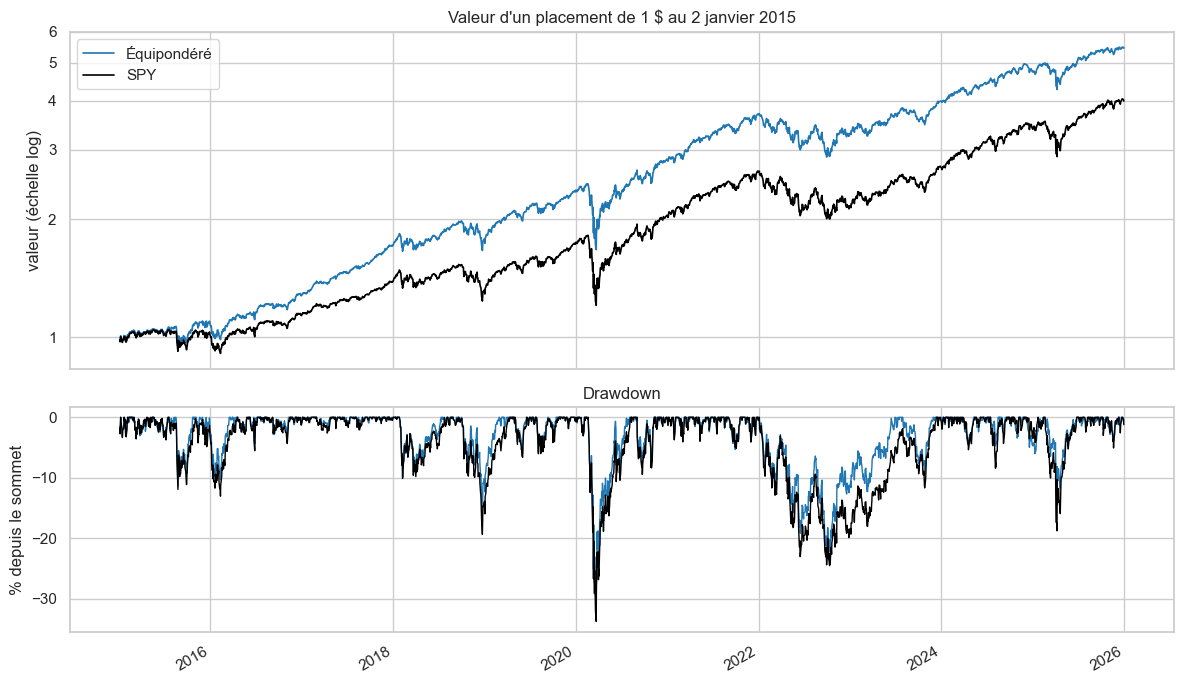

Valeur finale de 1 $ : {'Équipondéré': 5.46, 'SPY': 4.0}


In [23]:
valeur = (1 + r_ref).cumprod()
dd = r_ref.apply(drawdowns)
couleurs_refs = {EQUI: "tab:blue", REFERENCE: "black"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for nom in r_ref:
    valeur[nom].plot(ax=ax1, color=couleurs_refs[nom], lw=1.2, label=nom)
    (dd[nom] * 100).plot(ax=ax2, color=couleurs_refs[nom], lw=1, label=nom)
ax1.set(yscale="log", ylabel="valeur (échelle log)", title="Valeur d'un placement de 1 $ au 2 janvier 2015")
ax1.set_yticks([1, 2, 3, 4, 5, 6], labels=["1", "2", "3", "4", "5", "6"])
ax1.minorticks_off()
ax1.legend()
ax2.set(ylabel="% depuis le sommet", xlabel="", title="Drawdown")
plt.tight_layout()
plt.show()

print("Valeur finale de 1 $ :", valeur.iloc[-1].round(2).to_dict())

In [24]:
# Détail du pire drawdown et de la plus longue période sous le dernier sommet
def details_drawdown(r):
    d = drawdowns(r)
    creux = d.idxmin()
    sommet = d[:creux][d[:creux] == 0].index.max()            # dernier sommet avant le creux
    apres = d[creux:][d[creux:] == 0].index
    retour = apres.min() if len(apres) else pd.NaT             # premier retour au sommet
    # Plus longue période consécutive sous un sommet antérieur, en jours de bourse
    sous_sommet = (d < 0).astype(int)
    episodes = sous_sommet.groupby((sous_sommet == 0).cumsum()).sum()
    return pd.Series({
        "max_drawdown": d.min(),
        "sommet": sommet.date(), "creux": creux.date(),
        "retour_au_sommet": retour.date() if pd.notna(retour) else "non atteint",
        "jours_sommet_creux": d[sommet:creux].shape[0] - 1,
        "jours_creux_retour": d[creux:retour].shape[0] - 1 if pd.notna(retour) else np.nan,
        "plus_longue_periode_sous_sommet_jours": int(episodes.max()),
    })

r_ref.apply(details_drawdown).T

,max_drawdown,sommet,creux,retour_au_sommet,jours_sommet_creux,jours_creux_retour,plus_longue_periode_sous_sommet_jours
Équipondéré,-0.3204,2020-02-19,2020-03-23,2020-08-04,23,93,380
SPY,-0.3372,2020-02-19,2020-03-23,2020-08-10,23,97,488


**Observations.**
- 1 $ investi en janvier 2015 vaut environ **5,5 $** fin 2025 avec l'équipondéré, et **4,0 $** avec SPY.
- **Le pire drawdown est celui du krach du Covid-19 pour les deux références** : du sommet du 19/02/2020 au creux du 23/03/2020, soit 23 séances, l'équipondéré perd 32,0 % et SPY 33,7 %. La valeur précédente est retrouvée en août 2020 (environ 5 mois et demi après le sommet).
- **La plus longue période sous le sommet n'est pas celle de la plus forte baisse.** En 2022, la baisse est moins profonde (−22,5 % pour l'équipondéré, −24,5 % pour SPY) mais beaucoup plus lente à effacer : le sommet de début janvier 2022 n'est retrouvé qu'en juillet 2023 pour l'équipondéré (380 séances, environ un an et demi) et en décembre 2023 pour SPY (488 séances, près de deux ans), contre environ 115 séances pour l'épisode de 2020. Le max drawdown, qui ne mesure que la profondeur, ne rend pas compte de cette durée.

**Interprétation.** Le max drawdown est la mesure la plus parlante pour un investisseur (« combien aurais-je pu perdre au pire ? »), mais elle repose sur **un seul épisode**. Sur cette période, elle décrit le krach du Covid-19 et rien d'autre ; une autre fenêtre d'étude donnerait une valeur différente.

## 13. VaR historique et VaR gaussienne

Pour mesurer l'effet des queues épaisses mis en évidence à l'étape 1, la VaR et la CVaR historiques sont comparées à leurs versions **gaussiennes**, qui supposent des rendements normaux de même moyenne $\mu$ et même écart-type $\sigma$ :

$$\text{VaR}^{N}_\alpha = -(\mu + \sigma\, z_{1-\alpha}), \qquad \text{CVaR}^{N}_\alpha = -\left(\mu - \sigma \frac{\varphi(z_{1-\alpha})}{1-\alpha}\right)$$

où $z_{1-\alpha}$ est le quantile de la loi normale centrée réduite et $\varphi$ sa densité.

La dernière colonne compte la **fréquence observée** des jours où la perte dépasse la VaR gaussienne. Si la VaR était correcte, cette fréquence serait proche de $1-\alpha$ (5 % ou 1 %).

In [25]:
loi_normale = NormalDist()

def comparaison_var(r, niveau):
    mu, sigma = r.mean(), r.std()
    z = loi_normale.inv_cdf(1 - niveau)
    var_n = -(mu + sigma * z)
    return pd.Series({
        "var_historique": var_historique(r, niveau),
        "var_gaussienne": var_n,
        "cvar_historique": cvar_historique(r, niveau),
        "cvar_gaussienne": -(mu - sigma * loi_normale.pdf(z) / (1 - niveau)),
        "frequence_attendue": 1 - niveau,
        "frequence_depassement_var_gaussienne": (r < -var_n).mean(),
    })

comparaison = pd.concat(
    {(nom, f"{niveau:.0%}"): comparaison_var(r_ref[nom], niveau) for nom in r_ref for niveau in NIVEAUX},
    axis=1,
).T
(comparaison * 100).round(2)

var_historique  var_gaussienne  cvar_historique  \
Équipondéré 95%          1.5000          1.6600           2.4900   
            99%          2.9400          2.3700           4.4600   
SPY         95%          1.6700          1.7900           2.7200   
            99%          3.2200          2.5500           4.6800   

                 cvar_gaussienne  frequence_attendue  \
Équipondéré 95%           2.1000              5.0000   
            99%           2.7300              1.0000   
SPY         95%           2.2600              5.0000   
            99%           2.9300              1.0000   

                 frequence_depassement_var_gaussienne  
Équipondéré 95%                                3.9400  
            99%                                1.7700  
SPY         95%                                4.2700  
            99%                                1.9200

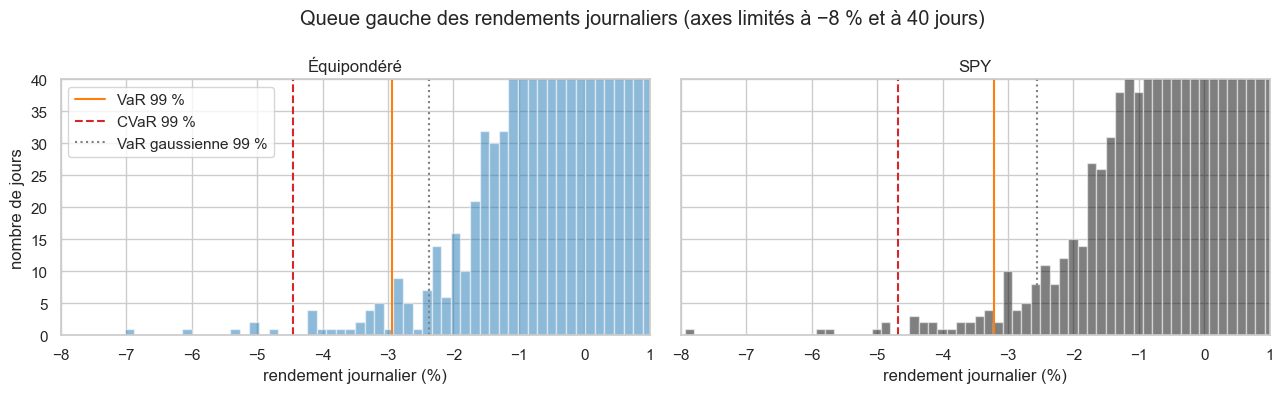

In [26]:
# Queue gauche de la distribution, avec la VaR et la CVaR historiques à 99 %
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, nom in zip(axes, r_ref):
    r = r_ref[nom] * 100
    ax.hist(r, bins=150, color=couleurs_refs[nom], alpha=0.5)
    ax.axvline(-var_historique(r, 0.99), color="tab:orange", lw=1.5, label="VaR 99 %")
    ax.axvline(-cvar_historique(r, 0.99), color="tab:red", lw=1.5, ls="--", label="CVaR 99 %")
    ax.axvline(-comparaison.loc[(nom, "99%"), "var_gaussienne"] * 100, color="gray", lw=1.5, ls=":",
               label="VaR gaussienne 99 %")
    # Axe vertical limité à 40 jours : le pic central est coupé pour rendre la queue lisible
    ax.set(xlim=(-8, 1), ylim=(0, 40), title=nom, xlabel="rendement journalier (%)")
axes[0].set_ylabel("nombre de jours")
axes[0].legend(loc="upper left")
fig.suptitle("Queue gauche des rendements journaliers (axes limités à −8 % et à 40 jours)")
plt.tight_layout()
plt.show()

**Observations.**
- **À 95 %, la VaR gaussienne est trop prudente** : 1,66 % contre 1,50 % pour l'équipondéré (1,79 % contre 1,67 % pour SPY). La perte ne la dépasse que 3,9 % des jours (4,3 % pour SPY) au lieu de 5 %.
- **À 99 %, elle est trop optimiste** : 2,37 % contre 2,94 % pour l'équipondéré (2,55 % contre 3,22 % pour SPY), soit environ 20 % de moins. La perte la dépasse 1,8 % des jours (1,9 % pour SPY), presque deux fois plus souvent que prévu.
- **La CVaR gaussienne sous-estime à tous les niveaux**, et l'écart grandit avec le niveau : à 99 %, 2,73 % contre 4,46 % pour l'équipondéré, soit une sous-estimation d'environ 40 %.

**Interprétation.** C'est la signature des queues épaisses décrites au § 6 : une distribution plus concentrée autour de 0 que la loi normale, mais avec plus de pertes extrêmes. La loi normale surestime les pertes « modérées » et sous-estime les pertes rares, précisément celles que la VaR à 99 % et la CVaR doivent capter. **Les mesures historiques sont donc retenues pour la suite du projet.**

**Précaution.** La VaR et la CVaR historiques à 99 % reposent sur les 28 pires jours de la période, dont plusieurs de mars 2020. Elles sont exactes pour cet échantillon, mais une autre période donnerait des valeurs sensiblement différentes. Elles supposent aussi que la distribution passée des pertes est représentative de l'avenir.

## 14. Stabilité des mesures dans le temps

Les § 6.3 et 6.4 ont montré que la volatilité et les corrélations varient fortement dans le temps. Les mesures sont donc recalculées **année par année** (rendement de l'année, volatilité, Sharpe, max drawdown au cours de l'année). La VaR et la CVaR ne sont pas recalculées par année : à 99 %, elles reposeraient sur 2 ou 3 observations seulement.

In [27]:
def mesures_annuelles(r):
    groupes = r.groupby(r.index.year)
    return pd.DataFrame({
        "rendement": groupes.apply(lambda x: (1 + x).prod() - 1),
        "volatilite": groupes.apply(volatilite_annualisee),
        "sharpe": groupes.apply(lambda x: ratio_sharpe(x, rf.loc[x.index])),
        "max_drawdown": groupes.apply(max_drawdown),
    })

annuel = pd.concat({nom: mesures_annuelles(r_ref[nom]) for nom in r_ref}, axis=1)
annuel.index.name = "année"
annuel.round(3)

Équipondéré                                       SPY             \
        rendement volatilite  sharpe max_drawdown rendement volatilite   
année                                                                    
2015       0.0790     0.1540  0.5670      -0.1140    0.0130     0.1550   
2016       0.1810     0.1250  1.3700      -0.0860    0.1200     0.1310   
2017       0.3390     0.0630  4.5360      -0.0180    0.2170     0.0670   
2018       0.0420     0.1670  0.2170      -0.1590   -0.0460     0.1700   
2019       0.3220     0.1170  2.2720      -0.0600    0.3120     0.1250   
2020       0.2100     0.3410  0.7170      -0.3200    0.1830     0.3340   
2021       0.2990     0.1130  2.3610      -0.0530    0.2870     0.1300   
2022      -0.1090     0.2150 -0.5230      -0.2250   -0.1820     0.2420   
2023       0.2130     0.1180  1.2960      -0.0940    0.2620     0.1310   
2024       0.1910     0.0950  1.3770      -0.0500    0.2490     0.1260   
2025       0.1480     0.1460  0.7510      -0.1440    0.1770     0.1950   

                            
       sharpe max_drawdown  
année                       
2015   0.1580      -0.1190  
2016   0.9100      -0.1030  
2017   2.8230      -0.0260  
2018  -0.3020      -0.1930  
2019   2.0740      -0.0660  
2020   0.6600      -0.3370  
2021   2.0070      -0.0510  
2022  -0.7900      -0.2450  
2023   1.4820      -0.1000  
2024   1.4470      -0.0840  
2025   0.7360      -0.1880

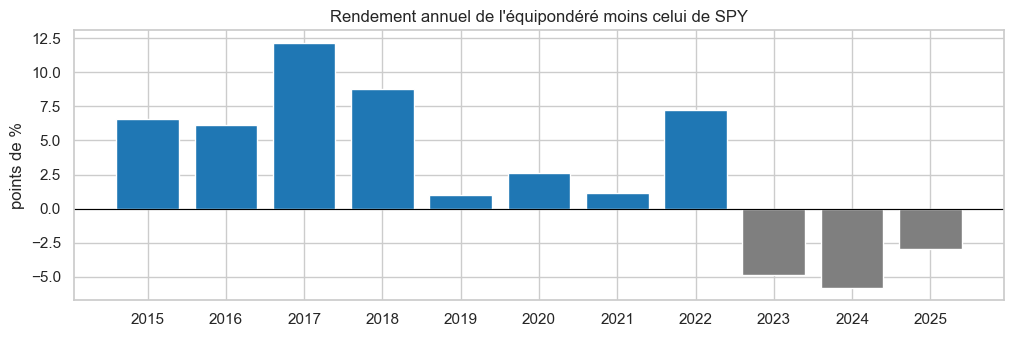

In [28]:
# Écart de rendement annuel entre l'équipondéré et SPY
ecart = (annuel[(EQUI, "rendement")] - annuel[(REFERENCE, "rendement")]) * 100
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(ecart.index, ecart, color=["tab:blue" if e > 0 else "tab:gray" for e in ecart])
ax.axhline(0, color="black", lw=0.8)
ax.set(xticks=ecart.index, ylabel="points de %",
       title="Rendement annuel de l'équipondéré moins celui de SPY")
plt.show()

**Observations.**
- **L'avantage de l'équipondéré n'est pas régulier.** Il bat SPY chaque année de 2015 à 2022, de +1 point (2019) à +12 points (2017). Il fait ensuite moins bien trois années de suite : de 4,9 points en 2023, 5,8 points en 2024 et 2,9 points en 2025. Ces dernières années correspondent à la forte hausse des plus grandes capitalisations, surpondérées dans SPY.
- **La volatilité de l'équipondéré est inférieure ou égale à celle de SPY presque chaque année** (seule exception nette : 2020, 34,1 % contre 33,4 %) ; l'écart est le plus net en 2024–2025 (9,5 % contre 12,6 % en 2024, 14,6 % contre 19,5 % en 2025), lorsque SPY est le plus concentré.
- **Le ratio de Sharpe varie bien plus d'une année à l'autre qu'entre les deux références** : de −0,52 (2022) à 4,54 (2017) pour l'équipondéré. Un ratio de Sharpe calculé sur une seule année est donc très peu informatif.

**Interprétation.** Les mesures sur 11 ans sont des moyennes de régimes très différents (marché calme de 2017, krach de 2020, marché baissier de 2022). Les comparaisons de portefeuilles des étapes suivantes devront donc être lues **par sous-période** et pas seulement sur la période complète.

## 15. Sauvegarde

Les rendements journaliers des deux références et le tableau des mesures sont enregistrés pour servir de point de comparaison aux étapes suivantes.

In [29]:
r_ref.to_csv(DOSSIER / "rendements_references.csv")
tableau.rename_axis("portefeuille").to_csv(DOSSIER / "mesures_references.csv")

for f in ["rendements_references.csv", "mesures_references.csv"]:
    print(f"{f:30s} {(DOSSIER / f).stat().st_size / 1e3:.0f} ko")

rendements_references.csv      153 ko
mesures_references.csv         0 ko


## 16. Synthèse et limites

**Résultats sur 2015–2025** (VaR et CVaR : perte journalière en % de la valeur du portefeuille).

| Mesure | Équipondéré | SPY |
|---|---|---|
| Rendement annualisé | 16,7 % | 13,5 % |
| Volatilité annualisée | 16,6 % | 17,8 % |
| Ratio de Sharpe | 0,90 | 0,69 |
| Max drawdown | −32,0 % | −33,7 % |
| VaR 95 % / CVaR 95 % | 1,50 % / 2,49 % | 1,67 % / 2,72 % |
| VaR 99 % / CVaR 99 % | 2,94 % / 4,46 % | 3,22 % / 4,68 % |

**À retenir.**
- Sur la période, l'équipondéré fait mieux que SPY sur toutes les mesures, mais les deux références sont très proches (corrélation de 0,97) et l'avantage de l'équipondéré s'inverse de 2023 à 2025.
- La VaR gaussienne sous-estime le risque à 99 % d'environ 20 %, la CVaR gaussienne d'environ 40 % : les mesures **historiques** sont retenues.
- Le max drawdown se résume au krach du Covid-19 ; la durée sous le sommet (près de deux ans pour SPY en 2022–2023) complète utilement sa lecture.

**Rôle pour la suite.** Toute méthode d'allocation des étapes suivantes sera évaluée avec les mêmes fonctions (§ 11) et comparée en priorité à l'**équipondéré**, qui partage le même univers d'actions et donc le même biais de survie. La comparaison à SPY renseigne sur le marché, mais pas sur la valeur ajoutée d'une méthode.

**Limites.**
- **Biais de survie** (§ 8) : il favorise le rendement de l'équipondéré par rapport à SPY ; la comparaison des rendements entre les deux références n'est pas équitable.
- **Pas de coûts de transaction** : le rééquilibrage quotidien serait coûteux en pratique ; il est retenu pour définir une référence exacte.
- **Mesures sur la période complète** : ce sont des moyennes de régimes très différents (§ 14), estimées avec une incertitude importante (intervalle de confiance du Sharpe de largeur ±0,7 environ).
- **VaR et CVaR historiques** : elles supposent que la distribution passée des pertes se reproduira, et la CVaR à 99 % repose sur 28 jours, dont plusieurs de mars 2020.

# Étape 3 — Optimisation de Markowitz

**Objectif.** Construire les portefeuilles « optimaux » au sens de Markowitz (1952) à partir des 39 actions : frontière efficiente, portefeuille de variance minimale et portefeuille de Sharpe maximal. Mesurer ensuite l'effet d'une meilleure estimation de la covariance (Ledoit-Wolf).

**Principe.** Un portefeuille de poids $w$ a pour rendement espéré $w^\top \mu$ et pour variance $w^\top \Sigma w$, où $\mu$ est le vecteur des rendements espérés des actions et $\Sigma$ leur matrice de covariance. Markowitz cherche les poids qui offrent le meilleur compromis entre ces deux grandeurs.

**Avertissement : résultats « dans l'échantillon ».** Aux étapes 3 à 5, $\mu$ et $\Sigma$ sont estimés sur toute la période 2015–2025, et les portefeuilles sont évalués sur cette même période. Un investisseur de 2015 ne disposait pas de ces estimations : les performances obtenues sont donc **optimistes par construction**. Elles servent seulement à comprendre chaque méthode. La comparaison honnête, où chaque décision n'utilise que le passé, est le backtest de l'étape 6.

**Démarche.**
1. Estimation de $\mu$ et $\Sigma$ (§ 17).
2. Fonctions d'optimisation, outils de comparaison et contrôles (§ 18).
3. Estimateur de Ledoit-Wolf (§ 19).
4. Frontière efficiente (§ 20).
5. Portefeuilles de variance minimale et de Sharpe maximal, tableau récapitulatif (§ 21).

## 17. Paramètres et estimations

| Paramètre | Valeur | Justification |
|---|---|---|
| `PLAFOND` | 10 % | poids maximal par action dans les variantes plafonnées ; limite la concentration sans imposer l'équipondération |
| `N_POINTS_FRONTIERE` | 50 | assez de points pour tracer une courbe lisse |
| `FENETRE_ESTIMATION` | 252 | un an de bourse : fenêtre d'estimation du backtest (étape 6), utilisée dès le § 19 pour illustrer Ledoit-Wolf |

**Estimations.**
- $\mu$ : moyenne **arithmétique** des rendements journaliers × 252. Le modèle de Markowitz utilise la moyenne arithmétique, car le rendement espéré d'un portefeuille en est exactement la moyenne pondérée $w^\top\mu$. Elle est supérieure au rendement annualisé composé de l'étape 2, d'environ $\sigma^2/2$.
- $\Sigma$ : covariance empirique des rendements journaliers × 252.
- $r_f$ : moyenne du taux sans risque journalier (§ 4) × 252.

**Contrainte commune à tous les portefeuilles** : poids positifs ou nuls et de somme 1 (pas de vente à découvert ni d'emprunt), comme pour un fonds d'actions classique.

In [30]:
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

PLAFOND = 0.10                # poids maximal par action dans les variantes plafonnées
N_POINTS_FRONTIERE = 50       # nombre de points calculés sur la frontière efficiente
FENETRE_ESTIMATION = 252      # fenêtre d'estimation du backtest, en jours de bourse

R = rendements[ACTIONS]                       # rendements journaliers des 39 actions
mu = R.mean() * JOURS_PAR_AN                  # rendements moyens annualisés (arithmétiques)
cov_emp = R.cov() * JOURS_PAR_AN              # covariance empirique annualisée
rf_annuel = rf.mean() * JOURS_PAR_AN          # taux sans risque moyen sur la période

def covariance_lw(r):
    # Covariance de Ledoit-Wolf annualisée, et intensité du rétrécissement delta
    lw = LedoitWolf().fit(r)
    return pd.DataFrame(lw.covariance_ * JOURS_PAR_AN, index=r.columns, columns=r.columns), lw.shrinkage_

cov_lw, delta_complet = covariance_lw(R)

print(f"μ : de {mu.min():.1%} ({mu.idxmin()}) à {mu.max():.1%} ({mu.idxmax()}) par an")
print(f"Taux sans risque moyen : {rf_annuel:.2%} par an")

μ : de 5.4% (PFE) à 66.1% (NVDA) par an
Taux sans risque moyen : 1.93% par an


## 18. Fonctions d'optimisation et outils de comparaison

| Portefeuille | Problème | Utilise $\mu$ ? |
|---|---|---|
| Variance minimale | $\min_w\ w^\top\Sigma w$ | non |
| Point de la frontière | $\min_w\ w^\top\Sigma w$ sous $w^\top\mu = $ cible | oui |
| Sharpe maximal | $\max_w\ \dfrac{w^\top\mu - r_f}{\sqrt{w^\top\Sigma w}}$ | oui |

Dans tous les cas, $\sum_i w_i = 1$ et $0 \le w_i \le w_{\max}$ ($w_{\max} = 1$, sauf dans les variantes plafonnées).

Les problèmes sont résolus numériquement par `scipy.optimize.minimize` (méthode SLSQP, qui accepte des bornes et des contraintes), en partant de l'équipondéré. Les poids inférieurs à $10^{-6}$ sont des résidus numériques de l'optimiseur : ils sont mis à zéro.

**Sharpe maximal.** Le ratio n'est pas une fonction convexe des poids, et l'optimiseur peut échouer sur des fenêtres courtes. On résout donc le problème équivalent, qui est quadratique et convexe :
$$\min_{y \ge 0}\ y^	op \Sigma y \quad 	ext{sous} \quad (\mu - r_f)^	op y = 1, \qquad 	ext{puis} \quad w = y / 	extstyle\sum_i y_i$$
Le plafond $w_i \le w_{\max}$ devient $y_i \le w_{\max} \sum_j y_j$. L'équivalence suppose qu'au moins une action ait un rendement espéré supérieur au taux sans risque. Sinon, aucun ratio de Sharpe positif n'est possible, et le portefeuille de variance minimale est retenu (cas qui ne peut se produire que dans le backtest, sur une fenêtre d'un an).

**Outils de comparaison**, réutilisés pour chaque modèle :
- `recapitulatif` : mesures de l'étape 2 (§ 11) sur 2015–2025, avec des poids maintenus constants (rééquilibrage quotidien, sans frais, comme l'équipondéré au § 10), plus trois indicateurs de concentration :
  - `nb_actions` : nombre d'actions de poids supérieur à 0,1 % ;
  - `nb_effectif` $= 1 / \sum_i w_i^2$ : nombre d'actions d'un équipondéré « équivalent ». Il vaut 39 pour l'équipondéré et 1 pour un portefeuille investi dans une seule action ;
  - `contribution_max` : part de la volatilité du portefeuille due à l'action qui y contribue le plus (définition au § 22) ;
- `graphe_poids` : poids de chaque action, par portefeuille ;
- `graphe_secteurs` : poids agrégés par secteur.

In [31]:
def nettoyer(x):
    w = np.where(x < 1e-6, 0, x)                        # résidus numériques mis à zéro
    return w / w.sum()

def minimiser_variance(c, contraintes=(), plafond=1.0):
    # Minimise w'Σw sous : somme des poids = 1, 0 <= w <= plafond, et contraintes supplémentaires
    n = len(c)
    resultat = minimize(
        lambda w: w @ c @ w, np.full(n, 1 / n), jac=lambda w: 2 * c @ w, method="SLSQP",
        bounds=[(0, plafond)] * n,
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}, *contraintes],
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    assert resultat.success, resultat.message
    return nettoyer(resultat.x)

def variance_minimale(cov, plafond=1.0):
    return pd.Series(minimiser_variance(cov.to_numpy(), plafond=plafond), index=cov.index)

def sharpe_maximal(mu, cov, rf_an, plafond=1.0):
    # Reformulation convexe : min y'Σy sous (μ - rf)'y = 1, y >= 0 et y_i <= plafond × Σy, puis w = y / Σy
    exces, c = (mu - rf_an).to_numpy(), cov.to_numpy()
    n = len(c)
    if exces.max() <= 0:                                # aucun Sharpe positif possible : variance minimale
        return variance_minimale(cov, plafond)
    contraintes = [{"type": "eq", "fun": lambda y: y @ exces - 1, "jac": lambda y: exces}]
    if plafond < 1:
        contraintes.append({"type": "ineq", "fun": lambda y: plafond * y.sum() - y,
                            "jac": lambda y: plafond * np.ones((n, n)) - np.eye(n)})
    depart = np.full(n, 1 / n) if exces.mean() > 0 else np.where(exces > 0, 1.0, 0.0)
    resultat = minimize(
        lambda y: y @ c @ y, depart / (depart @ exces), jac=lambda y: 2 * c @ y, method="SLSQP",
        bounds=[(0, None)] * n, constraints=contraintes, options={"ftol": 1e-12, "maxiter": 1000},
    )
    assert resultat.success, resultat.message
    return pd.Series(nettoyer(resultat.x), index=cov.index)

def frontiere_efficiente(mu, cov, n_points=N_POINTS_FRONTIERE):
    # Variance minimale pour chaque rendement cible, du portefeuille de variance minimale à l'action la plus rentable
    m, c = mu.to_numpy(), cov.to_numpy()
    cibles = np.linspace(variance_minimale(cov) @ mu, m.max(), n_points)
    vols = []
    for cible in cibles:
        w = minimiser_variance(c, [{"type": "eq", "fun": lambda w, x=cible: w @ m - x}])
        vols.append(np.sqrt(w @ c @ w))
    return pd.DataFrame({"volatilite": vols, "rendement": cibles})

def contributions_risque(w, cov):
    # Part de chaque action dans la volatilité du portefeuille (somme = 1), voir § 22
    rc = w * (cov @ w)
    return rc / rc.sum()

# ---- Outils de comparaison
COLONNES_RECAP = ["rendement_annualise", "volatilite_annualisee", "sharpe", "max_drawdown", "cvar_95%"]
COULEURS_SECTEURS = dict(zip(SECTEURS, sns.color_palette("tab20", len(SECTEURS))))

def concentration(w, cov=cov_emp):
    return pd.Series({
        "nb_actions": int((w > 0.001).sum()),
        "nb_effectif": 1 / (w**2).sum(),
        "poids_max": w.max(),
        "action_max": w.idxmax(),
        "contribution_max": contributions_risque(w, cov).max(),
    })

def recapitulatif(portefeuilles):
    # Mesures du § 11 sur 2015-2025 (poids constants, sans frais) et concentration ;
    # l'équipondéré et SPY (rendements du § 10) servent de références
    r = pd.DataFrame({nom: R @ w for nom, w in portefeuilles.items()}).join(r_ref)
    t = r.apply(mesures, rf=rf).T[COLONNES_RECAP]
    poids_tous = {**portefeuilles, EQUI: poids}
    return t.join(pd.DataFrame({nom: concentration(w) for nom, w in poids_tous.items()}).T)

def lisible(t):
    # Pourcentages pour la lecture ; ratios et nombres d'actions inchangés
    t = t.copy()
    for col in t.columns:
        if col in ("action_max",):
            continue
        elif col == "nb_actions":
            t[col] = t[col].astype("Int64")
        elif col in ("sharpe", "nb_effectif", "nb_effectif_moyen"):
            t[col] = t[col].astype(float).round(2)
        else:
            t[col] = (t[col].astype(float) * 100).round(2)
    return t

def graphe_poids(portefeuilles, titre, seuil=0.01):
    # Poids (%) des actions détenues à plus de 1 % dans au moins un portefeuille, dans l'ordre des secteurs
    p = pd.DataFrame(portefeuilles) * 100
    p = p[(p > seuil * 100).any(axis=1)]
    fig, ax = plt.subplots(figsize=(1.7 * p.shape[1] + 2, 0.3 * len(p) + 1.5))
    sns.heatmap(p, annot=True, fmt=".1f", cmap="Blues", cbar=False, linewidths=0.5, ax=ax,
                mask=p < 0.05, annot_kws={"fontsize": 8})
    ax.set(title=titre, ylabel="")
    ax.tick_params(axis="x", rotation=15)
    plt.show()

def graphe_secteurs(portefeuilles, titre):
    # Poids agrégés par secteur : une barre empilée par portefeuille
    par_secteur = pd.DataFrame({nom: w.groupby(SECTEUR_DE).sum() for nom, w in portefeuilles.items()}).T
    par_secteur = par_secteur[list(SECTEURS)] * 100
    ax = par_secteur.plot.barh(stacked=True, figsize=(12, 0.55 * len(par_secteur) + 1.5), width=0.7,
                               color=[COULEURS_SECTEURS[s] for s in par_secteur.columns])
    ax.invert_yaxis()
    ax.set(xlabel="% du portefeuille", xlim=(0, 100), title=titre)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.show()

**Contrôle des fonctions** sur des cas dont la solution se calcule à la main.

In [32]:
# 1. Deux actions non corrélées de volatilités 10 % et 20 % : la variance minimale donne des poids
#    proportionnels à 1/σ², soit 100 et 25, donc 80 % et 20 %
cov_test = pd.DataFrame(np.diag([0.01, 0.04]), index=["A", "B"], columns=["A", "B"])
assert np.allclose(variance_minimale(cov_test), [0.8, 0.2], atol=1e-4)
# 2. Sharpe maximal sans contrainte active : poids proportionnels à Σ⁻¹(μ − rf),
#    soit (0,05 / 0,01 ; 0,10 / 0,04) = (5 ; 2,5), donc 2/3 et 1/3
mu_test = pd.Series([0.07, 0.12], index=["A", "B"])
assert np.allclose(sharpe_maximal(mu_test, cov_test, 0.02), [2 / 3, 1 / 3], atol=1e-4)
# 3. Le plafond est respecté et les poids somment à 1
w_test = sharpe_maximal(mu, cov_emp, rf_annuel, plafond=PLAFOND)
assert np.isclose(w_test.sum(), 1) and w_test.max() <= PLAFOND + 1e-8
# 4. Les contributions au risque somment à 1
assert np.isclose(contributions_risque(w_test, cov_emp).sum(), 1)
print("Tous les contrôles sont vérifiés")

Tous les contrôles sont vérifiés


## 19. Estimateur de Ledoit-Wolf

**Problème.** La covariance empirique $S$ contient $39 \times 40 / 2 = 780$ paramètres. Sur 2 765 jours, ils sont bien estimés. Sur une fenêtre de 252 jours, comme dans le backtest, l'estimation devient bruitée. Ce bruit n'est pas neutre : les **plus petites valeurs propres** de $S$ sont sous-estimées, si bien que certaines combinaisons d'actions paraissent presque sans risque. Or l'optimiseur de variance minimale recherche précisément ces combinaisons : il amplifie l'erreur d'estimation.

**Solution** (Ledoit et Wolf, 2004). Remplacer $S$ par une moyenne pondérée de $S$ et d'une matrice cible $F$ très simple :
$$\Sigma_{LW} = \delta\, F + (1 - \delta)\, S, \qquad 0 \le \delta \le 1$$
- $F = \bar{\sigma}^2 I$ (implémentation de `scikit-learn`) : toutes les actions ont la même variance, égale à la moyenne des variances, et des corrélations nulles. $F$ est très biaisée, mais sans bruit.
- L'intensité $\delta$ est donnée par une formule explicite qui minimise l'erreur quadratique attendue de l'estimateur. Elle est d'autant plus grande que l'échantillon est court par rapport au nombre d'actions.

Le rétrécissement rapproche les valeurs propres extrêmes de leur moyenne. On le mesure par le **conditionnement** de la matrice (plus grande valeur propre / plus petite) : plus il est élevé, plus les poids optimaux sont sensibles aux erreurs d'estimation.

Le graphique de gauche montre $\delta$ estimé chaque fin de mois sur les 252 jours précédents ; celui de droite, les 39 valeurs propres sur toute la période et sur les 252 derniers jours.

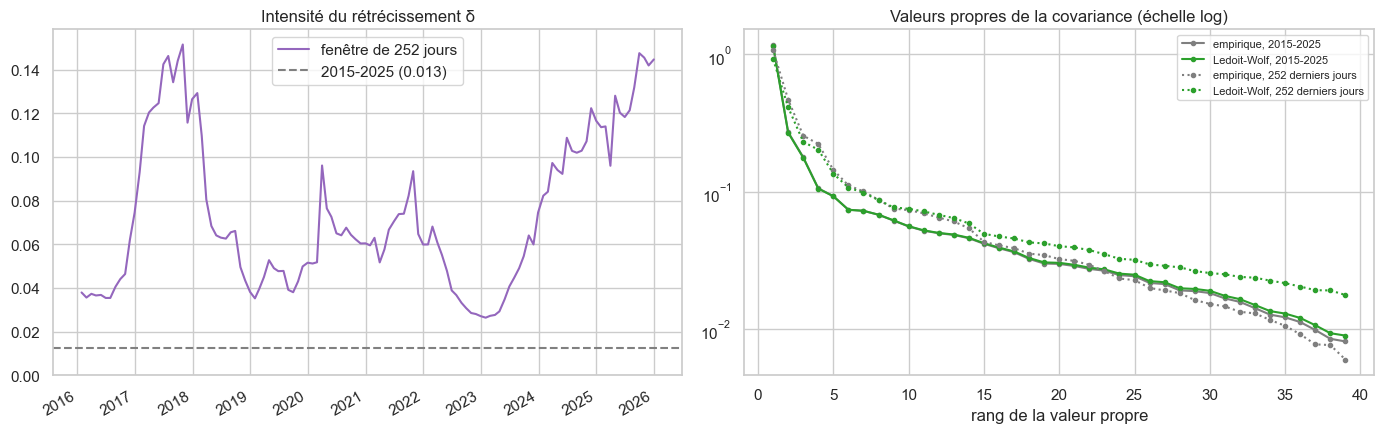

δ sur 2015-2025 : 0.013
δ sur 252 jours : de 0.026 à 0.151 (médiane 0.064)

Conditionnement (plus grande valeur propre / plus petite) :
empirique, 2015-2025              145.0000
Ledoit-Wolf, 2015-2025            130.0000
empirique, 252 derniers jours     180.0000
Ledoit-Wolf, 252 derniers jours    53.0000


In [33]:
# Fins de mois disposant d'au moins 252 jours de données (elles serviront aussi de dates de rééquilibrage)
fins_de_mois = pd.DatetimeIndex(R.index.to_series().groupby(R.index.to_period("M")).max())
fins_de_mois = fins_de_mois[fins_de_mois >= R.index[FENETRE_ESTIMATION - 1]]
delta_glissant = pd.Series({d: covariance_lw(R.loc[:d].iloc[-FENETRE_ESTIMATION:])[1] for d in fins_de_mois})

def valeurs_propres(cov):
    return np.sort(np.linalg.eigvalsh(cov))[::-1]

dernier_an = R.iloc[-FENETRE_ESTIMATION:]
vp = pd.DataFrame({
    "empirique, 2015-2025": valeurs_propres(cov_emp),
    "Ledoit-Wolf, 2015-2025": valeurs_propres(cov_lw),
    "empirique, 252 derniers jours": valeurs_propres(dernier_an.cov() * JOURS_PAR_AN),
    "Ledoit-Wolf, 252 derniers jours": valeurs_propres(covariance_lw(dernier_an)[0]),
}, index=range(1, len(ACTIONS) + 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
delta_glissant.plot(ax=ax1, color="tab:purple", label="fenêtre de 252 jours")
ax1.axhline(delta_complet, color="gray", ls="--", label=f"2015-2025 ({delta_complet:.3f})")
ax1.set(title="Intensité du rétrécissement δ", xlabel="", ylim=(0, None))
ax1.legend()
styles = ["-", "-", ":", ":"]
couleurs_vp = ["tab:gray", "tab:green", "tab:gray", "tab:green"]
for (nom, serie), ls, c in zip(vp.items(), styles, couleurs_vp):
    ax2.plot(serie.index, serie, ls=ls, color=c, marker="o", ms=3, label=nom)
ax2.set(yscale="log", xlabel="rang de la valeur propre", title="Valeurs propres de la covariance (échelle log)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"δ sur 2015-2025 : {delta_complet:.3f}")
print(f"δ sur 252 jours : de {delta_glissant.min():.3f} à {delta_glissant.max():.3f} (médiane {delta_glissant.median():.3f})")
print("\nConditionnement (plus grande valeur propre / plus petite) :")
print((vp.iloc[0] / vp.iloc[-1]).round(0).to_string())

**Observations.**
- **Sur toute la période, le rétrécissement est négligeable** : $\delta = 0{,}013$. Avec 2 765 jours pour 39 actions, la covariance empirique est déjà précise, et le conditionnement ne baisse que de 145 à 130.
- **Sur une fenêtre de 252 jours, il est 2 à 12 fois plus fort** : $\delta$ va de 0,026 à 0,151 (médiane 0,064). Il est le plus élevé fin 2017 et en 2025, des périodes où les corrélations entre actions sont faibles (§ 6.3) : la cible $F$, à corrélations nulles, est alors plus proche de la réalité, et la formule lui donne plus de poids.
- **Effet sur les valeurs propres** : sur les 252 derniers jours, les plus petites valeurs propres empiriques (pointillés gris) plongent sous celles de la période complète. C'est le bruit d'estimation décrit plus haut. Ledoit-Wolf les relève, et le conditionnement passe de **180 à 53**.

**Conséquence.** Ledoit-Wolf ne changera presque rien aux portefeuilles estimés sur 2015–2025 (§ 21). Son intérêt se mesure dans le backtest, où chaque estimation repose sur 252 jours.

## 20. Frontière efficiente

La frontière est tracée pour 50 rendements cibles, du rendement du portefeuille de variance minimale jusqu'à celui de l'action la plus rentable : sans vente à découvert, aucun portefeuille ne peut faire mieux que cette action.

Le graphique place aussi chaque action, les deux références et la **droite de marché des capitaux** : la droite issue du taux sans risque et tangente à la frontière. Son point de contact est le portefeuille de Sharpe maximal, et sa pente est le ratio de Sharpe de ce portefeuille.

Les rendements portés sur le graphique sont des moyennes arithmétiques annualisées (§ 17), et non les rendements composés de l'étape 2.

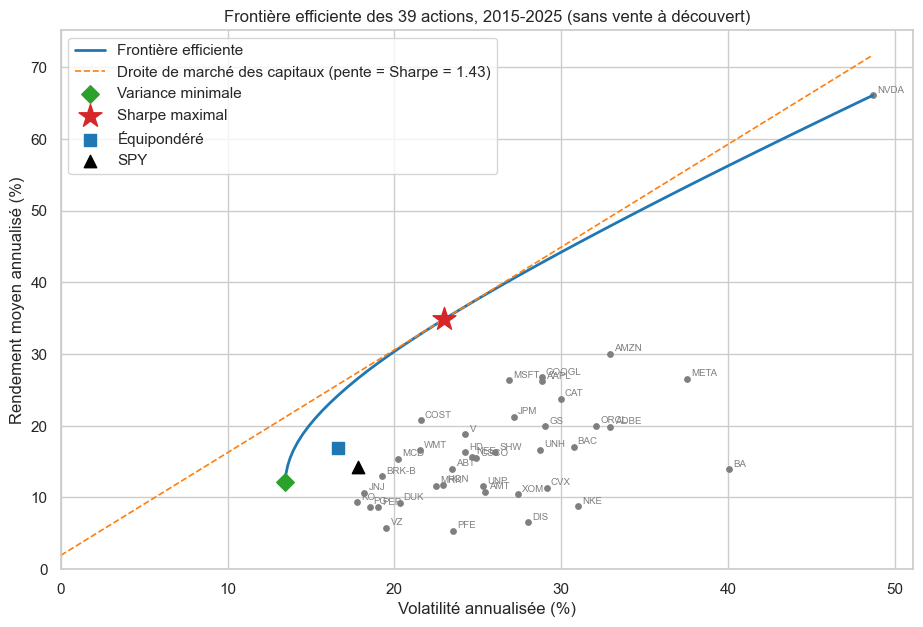

In [34]:
frontiere = frontiere_efficiente(mu, cov_emp)
w_vm = variance_minimale(cov_emp)
w_sm = sharpe_maximal(mu, cov_emp, rf_annuel)

def point(w):
    # Volatilité et rendement moyen annualisés d'un portefeuille de poids w
    return np.sqrt(w @ cov_emp @ w), w @ mu

fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(frontiere["volatilite"] * 100, frontiere["rendement"] * 100, color="tab:blue", lw=2,
        label="Frontière efficiente")

# Actions individuelles
vol_actions = np.sqrt(np.diag(cov_emp))
ax.scatter(vol_actions * 100, mu * 100, color="tab:gray", s=15)
for t, v in zip(ACTIONS, vol_actions):
    ax.annotate(t, (v * 100, mu[t] * 100), fontsize=7, color="gray", xytext=(3, 2), textcoords="offset points")

# Droite de marché des capitaux
v_sm, r_sm = point(w_sm)
pente = (r_sm - rf_annuel) / v_sm
x = np.linspace(0, frontiere["volatilite"].max(), 10)
ax.plot(x * 100, (rf_annuel + pente * x) * 100, color="tab:orange", ls="--", lw=1.2,
        label=f"Droite de marché des capitaux (pente = Sharpe = {pente:.2f})")

# Portefeuilles particuliers et références
v_spy = rendements[REFERENCE].std() * np.sqrt(JOURS_PAR_AN)
r_spy = rendements[REFERENCE].mean() * JOURS_PAR_AN
for (v, r_), nom, marqueur, couleur, taille in [
    (point(w_vm), "Variance minimale", "D", "tab:green", 80),
    ((v_sm, r_sm), "Sharpe maximal", "*", "tab:red", 300),
    (point(poids), EQUI, "s", "tab:blue", 80),
    ((v_spy, r_spy), REFERENCE, "^", "black", 80),
]:
    ax.scatter(v * 100, r_ * 100, marker=marqueur, color=couleur, s=taille, zorder=5, label=nom)

ax.set(xlabel="Volatilité annualisée (%)", ylabel="Rendement moyen annualisé (%)", xlim=(0, None), ylim=(0, None),
       title="Frontière efficiente des 39 actions, 2015-2025 (sans vente à découvert)")
ax.legend(loc="upper left")
plt.show()

**Observations.**
- **Toutes les actions sont nettement sous la frontière.** Seule NVDA la touche, à son extrémité droite (rendement moyen de 66 % par an pour 49 % de volatilité). En combinant les actions, on obtient donc toujours un meilleur couple rendement / risque qu'en détenant une action seule, NVDA exceptée.
- **Le portefeuille de variance minimale** a une volatilité de **13,5 %**, inférieure à celle de l'action la moins volatile (KO, 17,8 %) : c'est l'effet de la diversification, poussé à son maximum.
- **Le portefeuille de Sharpe maximal** est au point de contact de la droite de marché des capitaux : 23,0 % de volatilité, ratio de Sharpe de **1,43**.
- **L'équipondéré et SPY sont à l'intérieur de la frontière** : à volatilité égale, un portefeuille de la frontière aurait rapporté environ 7 points de plus par an que l'équipondéré, et 12 points de plus que SPY.

**Précaution.** Cette frontière est construite avec des rendements connus *a posteriori*. Elle décrit ce qui aurait été optimal, et non ce qu'un investisseur pouvait atteindre (§ 21.1 et étape 6).

## 21. Variance minimale et Sharpe maximal

Quatre portefeuilles sont comparés aux deux références :

| Portefeuille | Covariance | Plafond par action |
|---|---|---|
| Variance minimale | empirique | aucun |
| Variance minimale LW | Ledoit-Wolf | aucun |
| Sharpe maximal | empirique | aucun |
| Sharpe maximal plafonné | empirique | 10 % |

In [35]:
markowitz = {
    "Variance minimale": w_vm,
    "Variance minimale LW": variance_minimale(cov_lw),
    "Sharpe maximal": w_sm,
    "Sharpe maximal plafonné": sharpe_maximal(mu, cov_emp, rf_annuel, plafond=PLAFOND),
}
recap_markowitz = recapitulatif(markowitz)
lisible(recap_markowitz)

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,cvar_95%,nb_actions,nb_effectif,poids_max,action_max,contribution_max
Variance minimale,11.9800,13.4600,0.7600,-23.1600,1.9300,15,9.7500,16.6400,VZ,16.6400
Variance minimale LW,11.9800,13.4600,0.7600,-23.2100,1.9300,15,9.9800,16.3200,VZ,16.2700
Sharpe maximal,38.0200,23.0000,1.4300,-33.5900,3.2400,10,5.1900,34.7300,NVDA,67.6000
Sharpe maximal plafonné,26.1600,17.5500,1.3000,-25.4200,2.6000,14,11.4700,10.0000,MCD,19.9800
Équipondéré,16.7200,16.6500,0.9000,-32.0400,2.4900,39,39.0000,2.5600,AAPL,4.3400
SPY,13.4600,17.7900,0.6900,-33.7200,2.7200,<NA>,NaN,NaN,NaN,NaN


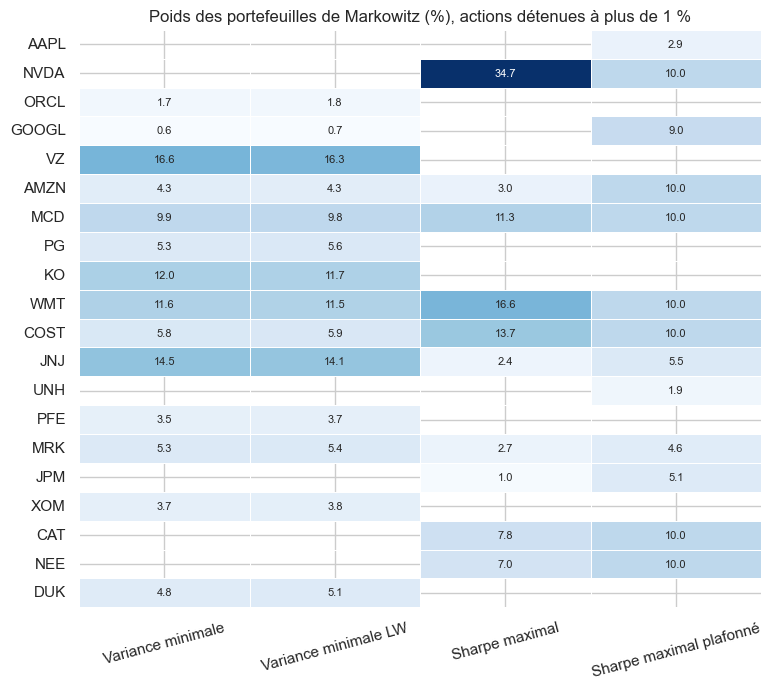

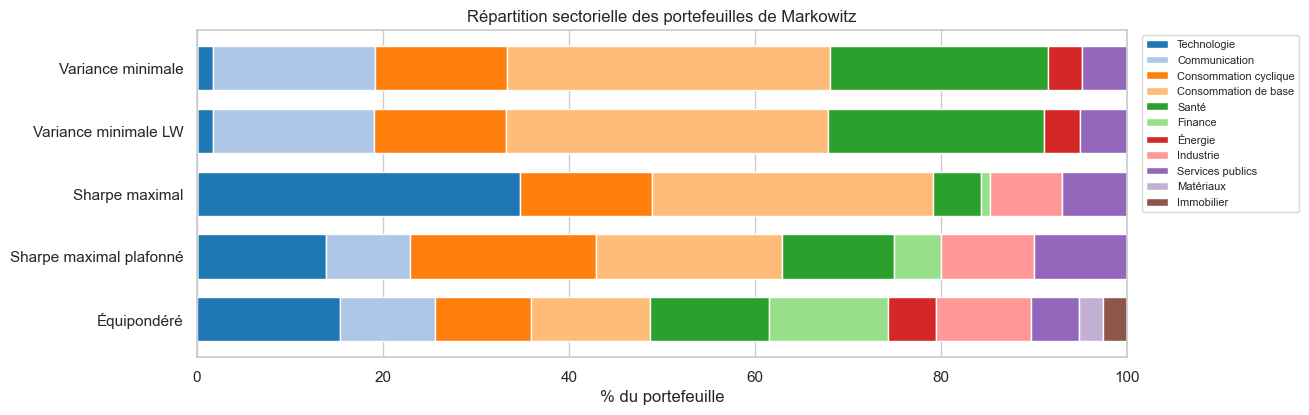

In [36]:
graphe_poids(markowitz, "Poids des portefeuilles de Markowitz (%), actions détenues à plus de 1 %")
graphe_secteurs({**markowitz, EQUI: poids}, "Répartition sectorielle des portefeuilles de Markowitz")

**Observations.**
- **Variance minimale.** Volatilité de 13,5 % et plus faibles pertes extrêmes du tableau (max drawdown −23,2 %, CVaR 95 % de 1,93 %). Le portefeuille ne retient que **15 actions**, surtout défensives : VZ (16,6 %), JNJ (14,5 %), KO (12,0 %), WMT (11,6 %), MCD (9,9 %). En contrepartie, son rendement (12,0 %) et son Sharpe (0,76) sont **inférieurs à ceux de l'équipondéré** (16,7 % et 0,90), même dans l'échantillon : minimiser le risque ne revient pas à maximiser le rendement par unité de risque.
- **Ledoit-Wolf ne change presque rien ici** (écarts de poids inférieurs à 0,4 point), comme prévu au § 19.
- **Sharpe maximal.** Sharpe de 1,43 et rendement de 38 % par an, mais le portefeuille est très concentré : 10 actions, 5,2 actions effectives, et **NVDA représente 34,7 % du capital et 67,6 % du risque**. Le reste va surtout à la consommation de base (WMT 16,6 %, COST 13,7 %) et à MCD (11,3 %).
- **Sharpe maximal plafonné à 10 %.** Le plafond est atteint pour 7 actions. Le Sharpe baisse peu (1,30) et le portefeuille est plus diversifié (11,5 actions effectives, max drawdown −25,4 % contre −33,6 %).

**Interprétation.** Le Sharpe maximal choisit les actions qui *ont* le mieux réussi sur 2015–2025, NVDA en tête : ses 1,43 mesurent la qualité du choix fait avec le recul, pas une performance atteignable. Le § 21.1 le vérifie.

### 21.1 Sensibilité du Sharpe maximal aux rendements espérés

Le portefeuille de Sharpe maximal dépend de $\mu$, estimé avec une grande incertitude : l'erreur-type d'une moyenne annuelle vaut $\sigma / \sqrt{T}$, avec $T$ le nombre d'années. Pour le vérifier, le portefeuille est recalculé avec $\mu$ estimé sur chacune des deux moitiés de la période, la covariance restant celle de 2015–2025. Si la méthode était robuste, les poids changeraient peu.

In [37]:
annees = len(R) / JOURS_PAR_AN
erreur_mu = np.sqrt(np.diag(cov_emp)) / np.sqrt(annees)
print(f"Erreur-type de μ sur {annees:.0f} ans : de {erreur_mu.min():.1%} à {erreur_mu.max():.1%} par an "
      f"(médiane {np.median(erreur_mu):.1%})")

# Sharpe maximal avec μ estimé sur chaque moitié de la période (covariance inchangée)
moities = {"μ 2015-2019": R.loc[:"2019"], "μ 2020-2025": R.loc["2020":]}
sensibilite = pd.DataFrame({
    nom: sharpe_maximal(r.mean() * JOURS_PAR_AN, cov_emp, rf.loc[r.index].mean() * JOURS_PAR_AN)
    for nom, r in moities.items()
})
sensibilite.insert(0, "μ 2015-2025", w_sm)
sensibilite = sensibilite[(sensibilite > 0.001).any(axis=1)].sort_values("μ 2015-2025", ascending=False)
(sensibilite * 100).round(1)

Erreur-type de μ sur 11 ans : de 5.4% à 14.7% par an (médiane 7.7%)


,μ 2015-2025,μ 2015-2019,μ 2020-2025
NVDA,34.7000,17.5000,32.7000
WMT,16.6000,0.0000,32.7000
COST,13.7000,0.0000,4.1000
MCD,11.3000,18.9000,0.0000
CAT,7.8000,0.0000,12.3000
NEE,7.0000,12.3000,0.0000
AMZN,3.0000,24.3000,0.0000
MRK,2.7000,4.0000,0.0000
JNJ,2.4000,0.0000,0.0000
JPM,1.0000,0.0000,0.0000


**Observations.**
- **L'erreur-type des rendements espérés est de 5 à 15 points par an** (médiane 7,7 points), alors que les écarts de $\mu$ entre la plupart des actions sont de cet ordre (§ 20). Le classement des actions par $\mu$ est donc en grande partie dû au hasard.
- **Les poids changent du tout au tout d'une moitié de la période à l'autre.** Avec $\mu$ de 2015–2019, le portefeuille met 24,3 % sur AMZN, 18,9 % sur MCD et 14,4 % sur UNH. Avec $\mu$ de 2020–2025, ces trois actions ont un poids **nul**, et WMT passe de 0 % à 32,7 %. Seule NVDA est présente dans les deux cas.

**Interprétation.** Le portefeuille de Sharpe maximal amplifie les erreurs d'estimation de $\mu$ : c'est le « maximiseur d'erreurs » décrit par Michaud (1989). Les méthodes des étapes 4 et 5 n'utilisent pas $\mu$ pour cette raison.

# Étape 4 — Risk parity

**Objectif.** Construire un portefeuille dans lequel chaque action contribue autant au risque total, sans utiliser les rendements espérés.

**Démarche.**
1. Contribution au risque et fonction de calcul (§ 22).
2. Résultats et comparaison avec l'équipondéré et la variance minimale (§ 23).

## 22. Contribution au risque et portefeuille ERC

**Contribution au risque.** La volatilité $\sigma_p = \sqrt{w^\top\Sigma w}$ se décompose exactement en contributions des actions (théorème d'Euler) :
$$RC_i = w_i \frac{(\Sigma w)_i}{\sigma_p}, \qquad \sum_i RC_i = \sigma_p$$
$RC_i$ dépend du poids de l'action, de sa volatilité **et** de sa corrélation avec le reste du portefeuille. L'équipondéré répartit également le capital, mais pas le risque : une action volatile et très corrélée aux autres y pèse davantage dans le risque. Les graphiques expriment $RC_i$ en part de $\sigma_p$ (fonction `contributions_risque` du § 18).

**Portefeuille ERC** (*Equal Risk Contribution*, Maillard, Roncalli et Teïletche, 2010) : $RC_i = \sigma_p / 39$ pour toutes les actions. Il s'obtient en résolvant le problème convexe (Spinu, 2013)
$$\min_{y > 0}\ \tfrac12\, y^\top \Sigma y - \frac{1}{N}\sum_i \ln y_i$$
puis en normalisant : $w = y / \sum_i y_i$. À l'optimum, la dérivée $(\Sigma y)_i - 1/(N y_i)$ est nulle, donc $y_i (\Sigma y)_i = 1/N$ pour tout $i$ : les contributions sont égales.

**Résolution.** Descente par coordonnées (Griveau-Billion, Richard et Roncalli, 2013) : chaque $y_i$ est remplacé à tour de rôle par la racine positive de $\Sigma_{ii}\, y_i^2 + \big(\sum_{j \ne i} \Sigma_{ij} y_j\big)\, y_i - 1/N = 0$, qui annule la dérivée, jusqu'à ce que les poids ne bougent plus.

**Variante naïve** : $w_i \propto 1/\sigma_i$. Elle égalise les contributions seulement si toutes les corrélations sont égales. Elle sert à mesurer ce qu'apporte la prise en compte des corrélations.

**Position attendue.** Le portefeuille ERC se situe entre l'équipondéré, qui égalise le capital, et la variance minimale, qui égalise les contributions **marginales** au risque des actions détenues : il est presque aussi diversifié que le premier et moins volatil.

In [38]:
def risk_parity(cov, tolerance=1e-10, max_iterations=10_000):
    # Portefeuille ERC par descente par coordonnées sur le problème de Spinu
    c = cov.to_numpy()
    n = len(c)
    y = 1 / np.sqrt(np.diag(c))                       # départ : inverse des volatilités
    for _ in range(max_iterations):
        y_avant = y.copy()
        for i in range(n):
            autres = c[i] @ y - c[i, i] * y[i]          # somme des Σ_ij y_j pour j ≠ i
            y[i] = (-autres + np.sqrt(autres**2 + 4 * c[i, i] / n)) / (2 * c[i, i])
        if np.abs(y - y_avant).max() < tolerance * y.max():
            break
    return pd.Series(y / y.sum(), index=cov.index)

def inverse_volatilite(cov):
    iv = 1 / np.sqrt(np.diag(cov))
    return pd.Series(iv / iv.sum(), index=cov.index)

# Contrôles
# 1. Deux actions non corrélées de volatilités 10 % et 20 % : contributions égales si w ∝ 1/σ, soit 2/3 et 1/3
assert np.allclose(risk_parity(cov_test), [2 / 3, 1 / 3], atol=1e-6)
# 2. Corrélations toutes égales : l'ERC coïncide avec la variante naïve 1/σ
vols_test = np.array([0.1, 0.2, 0.3])
corr_test = np.full((3, 3), 0.5)
np.fill_diagonal(corr_test, 1)
cov_test3 = pd.DataFrame(np.outer(vols_test, vols_test) * corr_test)
assert np.allclose(risk_parity(cov_test3), inverse_volatilite(cov_test3), atol=1e-6)
# 3. Sur les 39 actions, toutes les contributions valent 1/39
w_erc = risk_parity(cov_emp)
assert np.allclose(contributions_risque(w_erc, cov_emp), 1 / len(ACTIONS), atol=1e-6)
print("Tous les contrôles sont vérifiés")

Tous les contrôles sont vérifiés


## 23. Résultats du risk parity

Le portefeuille ERC est comparé à la variante naïve (inverse des volatilités), au portefeuille de variance minimale du § 21 et aux deux références.

In [39]:
risk_parity_ptf = {
    "Risk parity (ERC)": w_erc,
    "Inverse volatilité": inverse_volatilite(cov_emp),
    "Variance minimale": w_vm,
}
recap_rp = recapitulatif(risk_parity_ptf)
lisible(recap_rp)

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,cvar_95%,nb_actions,nb_effectif,poids_max,action_max,contribution_max
Risk parity (ERC),15.3900,15.7100,0.8700,-30.5100,2.3400,39,36.9100,4.0400,VZ,2.5600
Inverse volatilité,15.3600,15.8800,0.8600,-31.0600,2.3700,39,37.2900,3.6400,KO,3.3300
Variance minimale,11.9800,13.4600,0.7600,-23.1600,1.9300,15,9.7500,16.6400,VZ,16.6400
Équipondéré,16.7200,16.6500,0.9000,-32.0400,2.4900,39,39.0000,2.5600,AAPL,4.3400
SPY,13.4600,17.7900,0.6900,-33.7200,2.7200,<NA>,NaN,NaN,NaN,NaN


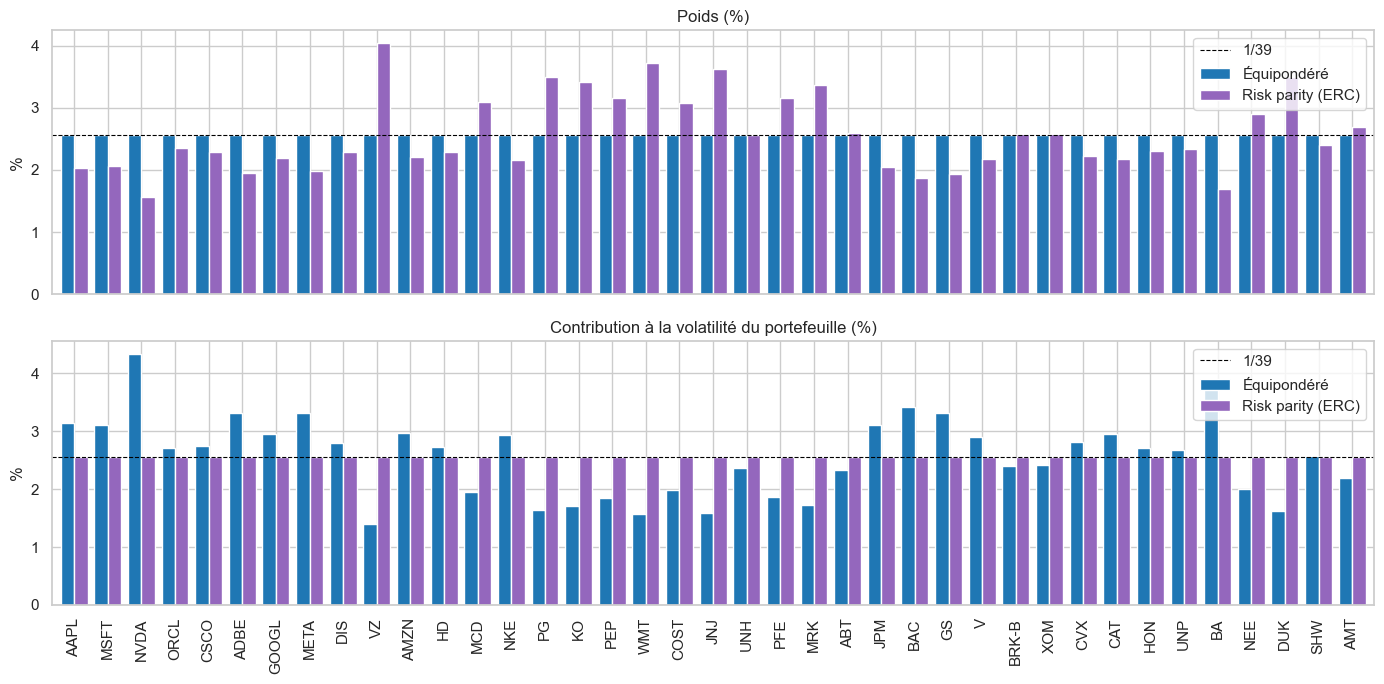

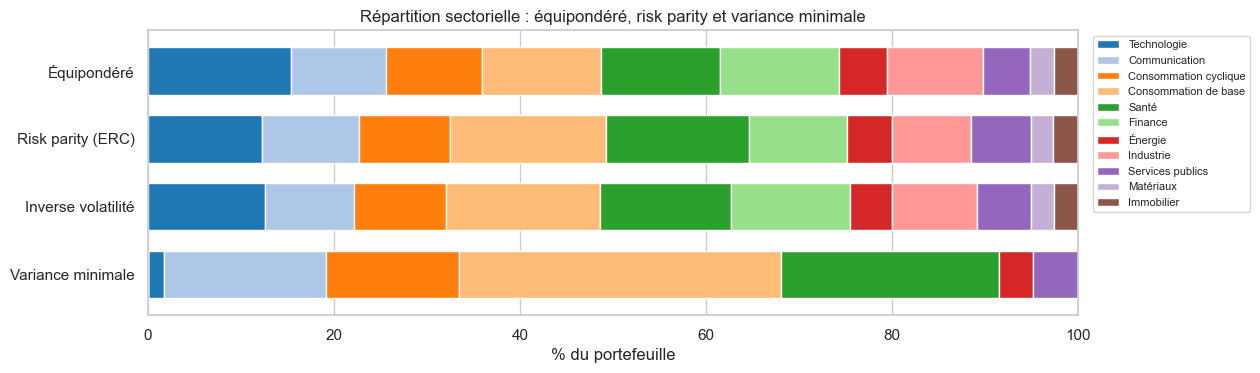

In [40]:
# Poids et contributions au risque de chaque action : équipondéré contre ERC
comparaison_rp = {EQUI: poids, "Risk parity (ERC)": w_erc}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, (titre, f) in zip(axes, [
    ("Poids (%)", lambda w: w),
    ("Contribution à la volatilité du portefeuille (%)", lambda w: contributions_risque(w, cov_emp)),
]):
    pd.DataFrame({nom: f(w) * 100 for nom, w in comparaison_rp.items()}).plot.bar(
        ax=ax, width=0.8, color=["tab:blue", "tab:purple"])
    ax.axhline(100 / len(ACTIONS), color="black", lw=0.8, ls="--", label="1/39")
    ax.set(ylabel="%", title=titre)
    ax.legend(loc="upper right")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

graphe_secteurs({EQUI: poids, **risk_parity_ptf}, "Répartition sectorielle : équipondéré, risk parity et variance minimale")

**Observations.**
- **L'équipondéré ne répartit pas le risque également.** À poids égal (2,6 %), NVDA y contribue pour 4,3 % de la volatilité et VZ pour 1,4 %. Les actions volatiles et corrélées au marché (NVDA, BA, BAC, GS, META, ADBE) pèsent plus que leur part de capital ; les actions défensives (VZ, JNJ, WMT, PG, KO, DUK), moins.
- **Le portefeuille ERC égalise exactement les contributions** (2,56 % chacune, contrôle vérifié). Pour cela, il réduit NVDA à 1,6 % et monte VZ à 4,0 %. Il reste très diversifié : 36,9 actions effectives.
- **Résultat : un portefeuille entre l'équipondéré et la variance minimale**, comme attendu. Sa volatilité (15,7 %) et son max drawdown (−30,5 %) sont un peu plus faibles que ceux de l'équipondéré (16,6 % et −32,0 %). Son Sharpe est presque identique (0,87 contre 0,90), car son rendement est plus faible (15,4 % contre 16,7 %).
- **La variante naïve 1/σ donne presque le même résultat** (Sharpe 0,86, mêmes poids sectoriels). Les corrélations entre actions sont assez homogènes (toutes positives, moyenne 0,38, § 6.3) : tenir compte des corrélations change peu les poids. Seule la répartition du risque est un peu moins égale (contribution maximale de 3,3 % contre 2,6 %).

# Étape 5 — Hierarchical Risk Parity (HRP)

**Objectif.** Répartir le risque en tenant compte de la structure de dépendance entre actions, sans inverser la matrice de covariance.

**Motivation** (López de Prado, 2016). Markowitz et l'ERC traitent les 39 actions comme un ensemble « plat » : chaque action peut se substituer à n'importe quelle autre, et l'optimiseur exploite de petites différences de covariance, souvent dues au bruit. Or les corrélations ont une structure en blocs (§ 6.3). Le HRP l'utilise explicitement : il répartit d'abord le risque entre de grands groupes d'actions semblables, puis à l'intérieur de chaque groupe.

**Algorithme en trois étapes.**
1. **Classification hiérarchique.** La distance entre deux actions est $d_{ij} = \sqrt{(1 - \rho_{ij})/2}$ : elle vaut 0 pour des actions parfaitement corrélées et 1 pour des actions parfaitement opposées. Les actions sont regroupées de proche en proche, avec le lien simple : la distance entre deux groupes est celle de leurs deux actions les plus proches. Le résultat est un arbre, le **dendrogramme**.
2. **Quasi-diagonalisation.** Les actions sont réordonnées selon les feuilles de l'arbre : des actions semblables deviennent voisines, et les fortes covariances se concentrent près de la diagonale.
3. **Bissection récursive.** La liste ordonnée est coupée en deux moitiés $G_1$ et $G_2$. Chaque moitié est résumée par sa variance $V_k$, calculée avec des poids inversement proportionnels à la variance de ses actions. Le budget est partagé en $\alpha = 1 - V_1/(V_1 + V_2)$ pour $G_1$ et $1 - \alpha$ pour $G_2$ : la moitié la moins risquée reçoit le plus. On recommence dans chaque moitié jusqu'à n'avoir plus qu'une action par groupe.

**Propriétés.** Ni inversion de matrice ni optimisation numérique : les poids sont stables et toujours positifs, et une action ne peut être remplacée que par ses voisines dans l'arbre. En contrepartie, le portefeuille n'est optimal au sens d'aucun critère.

**Démarche.** Fonctions, contrôles et lecture de l'arbre (§ 24) ; résultats et synthèse des étapes 3 à 5 (§ 25).

## 24. Classification et poids HRP

In [41]:
def classification(cov, methode="single"):
    # Arbre de classification des actions, à partir de la distance d = sqrt((1 - ρ) / 2)
    vol = np.sqrt(np.diag(cov))
    correl = cov / np.outer(vol, vol)
    distance = np.sqrt(((1 - correl) / 2).clip(lower=0))
    return linkage(squareform(distance.to_numpy(), checks=False), method=methode)

def variance_groupe(cov, groupe):
    # Variance d'un groupe d'actions pondérées par l'inverse de leur variance
    c = cov.loc[groupe, groupe].to_numpy()
    iv = 1 / np.diag(c)
    iv /= iv.sum()
    return iv @ c @ iv

def hrp(cov):
    ordre = cov.index[leaves_list(classification(cov))].tolist()      # quasi-diagonalisation
    w = pd.Series(1.0, index=ordre)
    groupes = [ordre]
    while groupes:
        # Bissection : chaque groupe de plus d'une action est coupé en deux moitiés
        groupes = [g[a:b] for g in groupes if len(g) > 1
                   for a, b in ((0, len(g) // 2), (len(g) // 2, len(g)))]
        for g1, g2 in zip(groupes[::2], groupes[1::2]):
            v1, v2 = variance_groupe(cov, g1), variance_groupe(cov, g2)
            alpha = 1 - v1 / (v1 + v2)
            w[g1] *= alpha
            w[g2] *= 1 - alpha
    return w.reindex(cov.index)

# Contrôles
# 1. Deux actions : une seule bissection, budget inversement proportionnel à la variance (80 % / 20 %)
assert np.allclose(hrp(cov_test), [0.8, 0.2])
# 2. Actions non corrélées : chaque bissection répartit selon l'inverse de la variance,
#    le résultat est donc l'inverse de la variance sur l'ensemble
cov_diag = pd.DataFrame(np.diag([0.01, 0.02, 0.04, 0.08]), index=list("ABCD"), columns=list("ABCD"))
iv = 1 / np.diag(cov_diag)
assert np.allclose(hrp(cov_diag), iv / iv.sum())
# 3. Sur les 39 actions : poids strictement positifs, de somme 1
w_hrp = hrp(cov_emp)
assert np.isclose(w_hrp.sum(), 1) and (w_hrp > 0).all()
print("Tous les contrôles sont vérifiés")

Tous les contrôles sont vérifiés


### 24.1 Lecture de l'arbre

Le dendrogramme montre l'ordre de regroupement des actions : plus deux actions sont réunies bas dans l'arbre, plus elles sont corrélées. Les étiquettes sont colorées selon le secteur, qui **n'est pas** utilisé par l'algorithme : leur regroupement indique si la classification retrouve les secteurs à partir des seuls rendements.

La matrice de corrélation est ensuite affichée deux fois : dans l'ordre des secteurs (comme au § 6.3) et dans l'ordre des feuilles de l'arbre (quasi-diagonalisation).

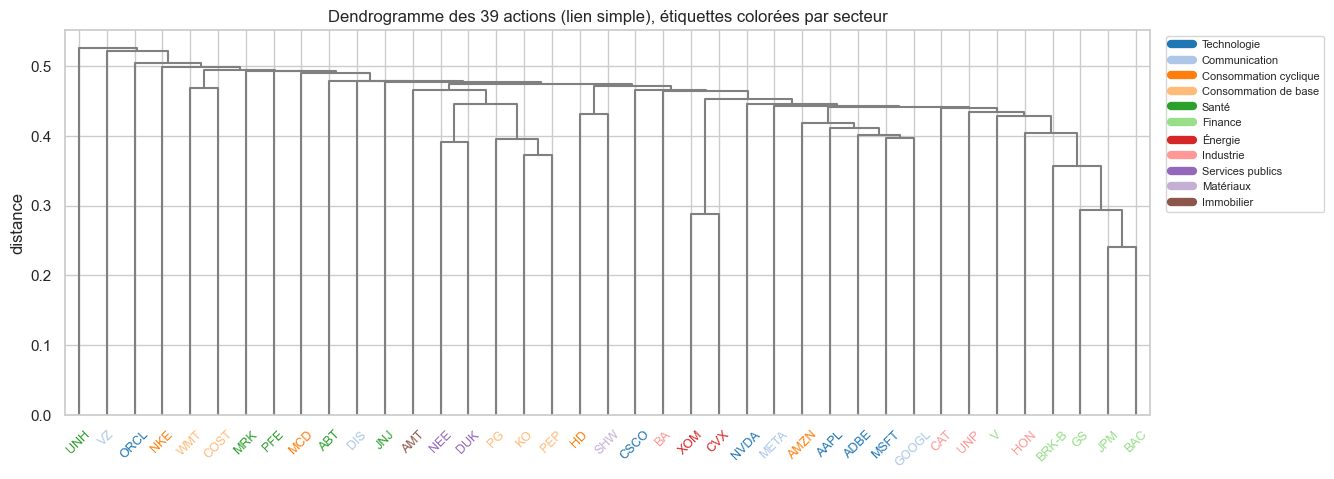

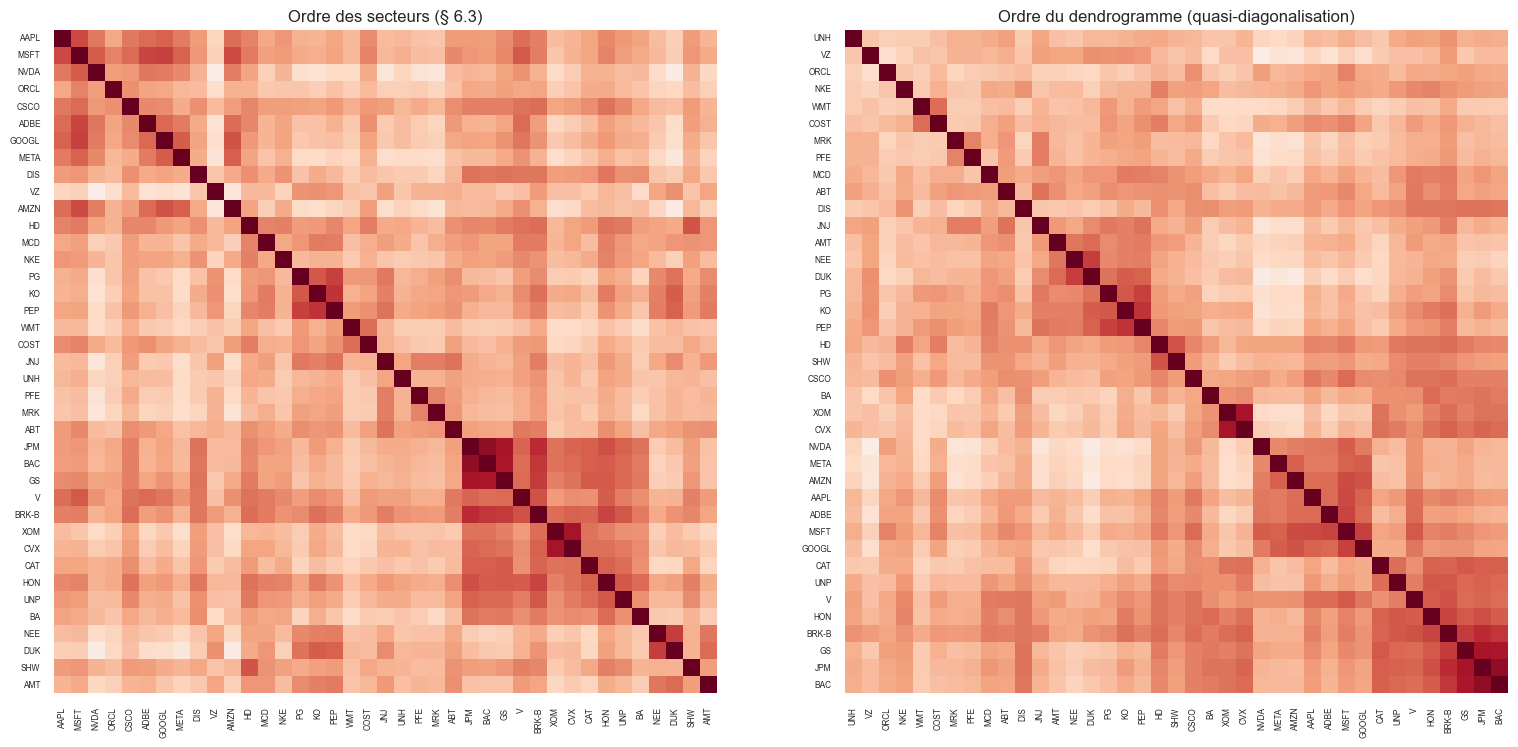

In [42]:
lien = classification(cov_emp)
ordre_hrp = [ACTIONS[i] for i in leaves_list(lien)]

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(lien, labels=ACTIONS, ax=ax, color_threshold=0, above_threshold_color="gray", leaf_font_size=9)
for etiquette in ax.get_xticklabels():
    etiquette.set_color(COULEURS_SECTEURS[SECTEUR_DE[etiquette.get_text()]])
ax.legend(handles=[plt.Line2D([], [], color=c, lw=6, label=s) for s, c in COULEURS_SECTEURS.items()],
          bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set(ylabel="distance", title="Dendrogramme des 39 actions (lien simple), étiquettes colorées par secteur")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, (titre, ordre) in zip(axes, [("Ordre des secteurs (§ 6.3)", ACTIONS),
                                     ("Ordre du dendrogramme (quasi-diagonalisation)", ordre_hrp)]):
    sns.heatmap(correlation.loc[ordre, ordre], cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
                cbar=False, xticklabels=True, yticklabels=True, ax=ax)
    ax.tick_params(labelsize=6)
    ax.set(title=titre, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

**Observations.**
- **Le lien simple produit un « effet de chaînage ».** La plupart des actions rejoignent un grand groupe une par une, à des distances proches (0,43 à 0,53), au lieu de former des groupes bien séparés. UNH, VZ, ORCL et NKE, peu corrélées au reste, sont les dernières à s'y rattacher.
- **Plusieurs secteurs sont pourtant retrouvés sans être donnés à l'algorithme** :
  - les banques et la finance (JPM et BAC, les plus proches de l'échantillon à 0,24, puis GS et BRK-B), auxquelles s'ajoute HON (industrie) ;
  - l'énergie (XOM et CVX, à 0,29) ;
  - la consommation de base (PG, KO, PEP), voisine des services publics (NEE, DUK) : ce sont toutes des valeurs défensives ;
  - les grandes valeurs technologiques (AAPL, ADBE, MSFT, NVDA), avec AMZN et META.
- **La matrice quasi-diagonalisée** regroupe ces blocs le long de la diagonale, comme le tri par secteur du § 6.3, mais à partir des seuls rendements.

**Conséquence pour le HRP.** Avec ce chaînage, les premières bissections séparent surtout les actions isolées du grand groupe, plutôt que de grands secteurs. Un lien différent (lien moyen, méthode de Ward) donnerait des groupes plus équilibrés ; le lien simple est conservé pour rester fidèle à l'article original.

## 25. Résultats du HRP et synthèse des étapes 3 à 5

Le HRP est d'abord comparé aux deux autres méthodes qui n'utilisent pas $\mu$ (ERC et variance minimale), puis tous les portefeuilles des étapes 3 à 5 sont réunis dans un tableau de synthèse.

In [43]:
recap_hrp = recapitulatif({"HRP": w_hrp, "Risk parity (ERC)": w_erc, "Variance minimale": w_vm})
lisible(recap_hrp)

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,cvar_95%,nb_actions,nb_effectif,poids_max,action_max,contribution_max
HRP,14.2200,15.0400,0.8300,-28.7400,2.2200,39,30.5300,6.8400,VZ,4.9200
Risk parity (ERC),15.3900,15.7100,0.8700,-30.5100,2.3400,39,36.9100,4.0400,VZ,2.5600
Variance minimale,11.9800,13.4600,0.7600,-23.1600,1.9300,15,9.7500,16.6400,VZ,16.6400
Équipondéré,16.7200,16.6500,0.9000,-32.0400,2.4900,39,39.0000,2.5600,AAPL,4.3400
SPY,13.4600,17.7900,0.6900,-33.7200,2.7200,<NA>,NaN,NaN,NaN,NaN


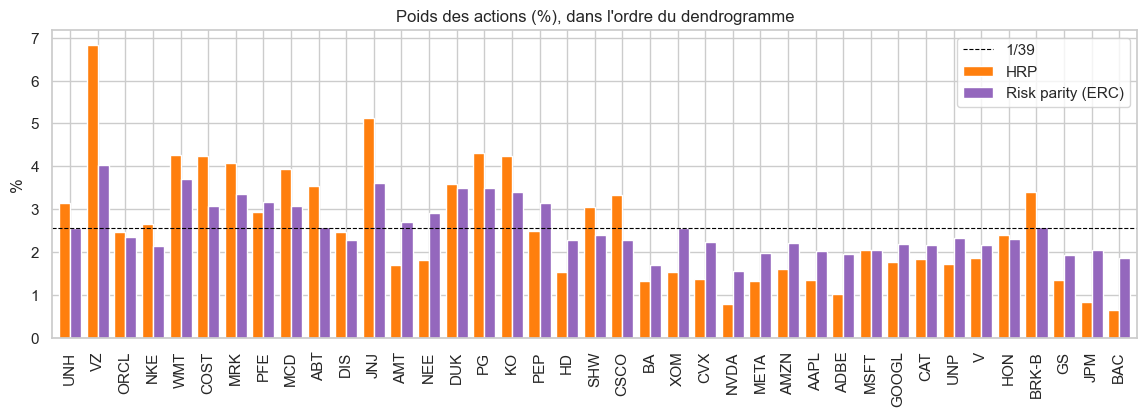

Cinq plus gros poids du HRP :
VZ     6.8 %
JNJ    5.1 %
PG     4.3 %
WMT    4.3 %
KO     4.2 %
dtype: object


In [44]:
# Poids des actions dans l'ordre du dendrogramme : HRP contre ERC
fig, ax = plt.subplots(figsize=(14, 4))
(pd.DataFrame({"HRP": w_hrp, "Risk parity (ERC)": w_erc}).loc[ordre_hrp] * 100).plot.bar(
    ax=ax, width=0.8, color=["tab:orange", "tab:purple"])
ax.axhline(100 / len(ACTIONS), color="black", lw=0.8, ls="--", label="1/39")
ax.set(ylabel="%", xlabel="", title="Poids des actions (%), dans l'ordre du dendrogramme")
ax.legend()
plt.show()

print("Cinq plus gros poids du HRP :")
print((w_hrp.sort_values(ascending=False).head(5) * 100).round(1).astype(str) + " %")

**Observations.**
- **Le HRP est plus défensif que l'ERC** : volatilité de 15,0 % contre 15,7 %, max drawdown de −28,7 % contre −30,5 %, CVaR 95 % de 2,22 % contre 2,34 %. Ses plus gros poids vont aux actions défensives : VZ (6,8 %), JNJ (5,1 %), PG, WMT et KO (environ 4,3 % chacune).
- **Il est un peu moins diversifié** (30,5 actions effectives contre 36,9), et la répartition du risque est moins égale (contribution maximale de 4,9 %). Il n'égalise pas les contributions des actions, mais celles des **groupes** à chaque bissection.
- **Sa performance se place entre l'ERC et la variance minimale** : rendement de 14,2 %, Sharpe de 0,83.

### 25.1 Synthèse des étapes 3 à 5 (dans l'échantillon)

In [45]:
tous_statiques = {**markowitz, "Risk parity (ERC)": w_erc, "HRP": w_hrp}
recap_tous = recapitulatif(tous_statiques)
lisible(recap_tous).sort_values("sharpe", ascending=False)

,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,cvar_95%,nb_actions,nb_effectif,poids_max,action_max,contribution_max
Sharpe maximal,38.0200,23.0000,1.4300,-33.5900,3.2400,10,5.1900,34.7300,NVDA,67.6000
Sharpe maximal plafonné,26.1600,17.5500,1.3000,-25.4200,2.6000,14,11.4700,10.0000,MCD,19.9800
Équipondéré,16.7200,16.6500,0.9000,-32.0400,2.4900,39,39.0000,2.5600,AAPL,4.3400
Risk parity (ERC),15.3900,15.7100,0.8700,-30.5100,2.3400,39,36.9100,4.0400,VZ,2.5600
HRP,14.2200,15.0400,0.8300,-28.7400,2.2200,39,30.5300,6.8400,VZ,4.9200
Variance minimale,11.9800,13.4600,0.7600,-23.1600,1.9300,15,9.7500,16.6400,VZ,16.6400
Variance minimale LW,11.9800,13.4600,0.7600,-23.2100,1.9300,15,9.9800,16.3200,VZ,16.2700
SPY,13.4600,17.7900,0.6900,-33.7200,2.7200,<NA>,NaN,NaN,NaN,NaN


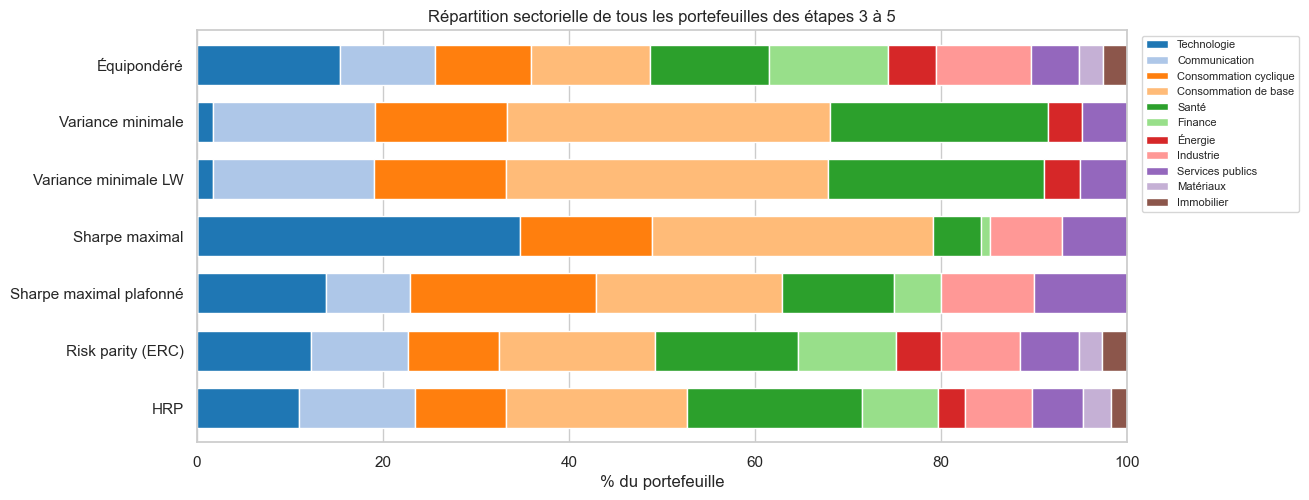

In [46]:
graphe_secteurs({EQUI: poids, **tous_statiques}, "Répartition sectorielle de tous les portefeuilles des étapes 3 à 5")

**Observations (dans l'échantillon, 2015–2025, sans frais).**
- **Deux familles de portefeuilles apparaissent.**
  - Ceux qui utilisent $\mu$ (Sharpe maximal, plafonné ou non) dominent le classement, avec des Sharpe de 1,30 à 1,43. Mais ils sont concentrés et choisis avec le recul (§ 21.1).
  - Ceux qui n'utilisent que le risque (variance minimale, ERC, HRP) réduisent la volatilité et les pertes extrêmes dans l'ordre attendu : variance minimale (13,5 %) < HRP (15,0 %) < ERC (15,7 %) < équipondéré (16,6 %). En revanche, **aucun ne bat l'équipondéré en Sharpe** (0,76 à 0,87 contre 0,90).
- **Répartition sectorielle.** Les méthodes fondées sur le risque surpondèrent la consommation de base, la santé et les télécommunications (VZ), au détriment de la technologie et de la finance. Le Sharpe maximal concentre son poids sur la technologie (NVDA) et la consommation de base (WMT, COST).
- **Tous les portefeuilles ont un Sharpe supérieur à celui de SPY** (0,69). Comme pour l'équipondéré à l'étape 2, cela s'explique en partie par le biais de survie de l'univers (§ 8).

**Question pour l'étape 6.** Ces classements tiennent-ils quand les poids sont estimés uniquement avec le passé, et que les transactions sont payées ?

# Étape 6 — Backtest glissant avec frais de transaction

**Objectif.** Comparer les méthodes des étapes 3 à 5 dans les conditions d'un investisseur réel : chaque décision n'utilise que les données disponibles à sa date, et chaque transaction est payée.

**Fonctionnement.**
1. **Rééquilibrage mensuel.** Le dernier jour de bourse de chaque mois, après la clôture, chaque méthode estime $\mu$ et $\Sigma$ sur les **252 derniers jours** (environ un an), puis calcule ses poids cibles.
2. **Exécution.** Le portefeuille est ramené aux poids cibles à cette clôture. Le coût est proportionnel au volume échangé :
$$\text{rotation}_t = \sum_i \left| w_{i}^{\text{cible}} - w_{i}^{\text{avant}} \right|, \qquad \text{coût}_t = c \times \text{rotation}_t$$
où $w^{\text{avant}}$ sont les poids qui ont dérivé depuis le rééquilibrage précédent. Le coût est déduit de la valeur du portefeuille.
3. **Détention.** Jusqu'au rééquilibrage suivant, aucune transaction : les poids dérivent avec les prix (comme au § 10). Le rendement du portefeuille est calculé **jour par jour**.
4. La fenêtre d'estimation avance d'un mois, et le cycle recommence.

**Absence de biais d'anticipation.** Les poids fixés à la clôture du jour $t$ ne s'appliquent qu'aux rendements à partir de $t+1$. La première année (2015) sert uniquement à la première estimation : le backtest commence en février 2016.

**Stratégies comparées.**

| Stratégie | Poids recalculés chaque mois |
|---|---|
| Équipondéré | 1/39, avec les mêmes frais ; référence principale |
| Variance minimale | covariance empirique |
| Variance minimale LW | covariance de Ledoit-Wolf |
| Sharpe maximal LW | $\mu$ historique sur 252 jours, covariance de Ledoit-Wolf |
| Sharpe maximal LW plafonné | idem, poids limités à 10 % |
| Risk parity LW | ERC sur la covariance de Ledoit-Wolf |
| HRP | covariance empirique, comme dans l'article original |

SPY, conservé sans transaction, sert de référence de marché. Une stratégie fondée sur un modèle de changement de régime (HMM) est ajoutée au § 31.

## 26. Paramètres du backtest

| Paramètre | Valeur | Justification |
|---|---|---|
| `FENETRE_ESTIMATION` | 252 jours | défini au § 17 : un an de données, compromis entre précision de l'estimation (780 paramètres de covariance) et réactivité aux changements de régime |
| Fréquence | mensuelle | compromis entre réactivité et frais ; fréquence courante pour ce type de stratégie |
| `FRAIS` | 0,10 % | coût par unité de valeur échangée (commission et demi-écart entre prix acheteur et vendeur) ; hypothèse pour de grandes capitalisations américaines très liquides |
| `FRAIS_TESTES` | 0 ; 0,10 ; 0,25 ; 0,50 % | test de sensibilité (§ 29) |

Le premier rééquilibrage part de liquidités : l'achat initial est payé (rotation de 100 %) par toutes les stratégies, sauf SPY.

In [47]:
import time

FRAIS = 0.001                                  # 0,10 % de la valeur échangée
FRAIS_TESTES = [0, 0.001, 0.0025, 0.005]

# Dates de rééquilibrage : fins de mois avec une fenêtre complète (§ 19), sauf le dernier jour de l'échantillon
dates_reeq = fins_de_mois[fins_de_mois < R.index[-1]]

def rf_fenetre(r):
    return rf.loc[r.index].mean() * JOURS_PAR_AN

# Chaque stratégie reçoit les 252 derniers rendements et renvoie ses poids cibles
STRATEGIES = {
    "Équipondéré": lambda r: pd.Series(1 / r.shape[1], index=r.columns),
    "Variance minimale": lambda r: variance_minimale(r.cov() * JOURS_PAR_AN),
    "Variance minimale LW": lambda r: variance_minimale(covariance_lw(r)[0]),
    "Sharpe maximal LW": lambda r: sharpe_maximal(r.mean() * JOURS_PAR_AN, covariance_lw(r)[0], rf_fenetre(r)),
    "Sharpe maximal LW plafonné": lambda r: sharpe_maximal(r.mean() * JOURS_PAR_AN, covariance_lw(r)[0],
                                                           rf_fenetre(r), plafond=PLAFOND),
    "Risk parity LW": lambda r: risk_parity(covariance_lw(r)[0]),
    "HRP": lambda r: hrp(r.cov() * JOURS_PAR_AN),
}
COULEURS = {
    "Équipondéré": "tab:blue", "Variance minimale": "tab:olive", "Variance minimale LW": "tab:green",
    "Sharpe maximal LW": "tab:red", "Sharpe maximal LW plafonné": "tab:pink", "Risk parity LW": "tab:purple",
    "HRP": "tab:orange", "Régimes HMM": "tab:cyan", REFERENCE: "black",
}

print(f"{len(dates_reeq)} rééquilibrages, du {dates_reeq[0]:%d/%m/%Y} au {dates_reeq[-1]:%d/%m/%Y}")

119 rééquilibrages, du 29/01/2016 au 28/11/2025


## 27. Simulation et résultats

**Calcul des poids.** À chaque date de rééquilibrage $d$, chaque stratégie reçoit uniquement les 252 rendements qui se terminent à $d$ (inclus).

**Simulation** (fonction `simuler`), pour chaque période entre deux rééquilibrages :
1. rotation par rapport aux poids qui ont dérivé, et déduction des frais ;
2. valeur de chaque ligne : poids × produit cumulé de $(1 + r)$ depuis le rééquilibrage ;
3. rendement journalier du portefeuille : variation relative de la somme des lignes ;
4. poids en fin de période, qui ont dérivé avec les prix, utilisés pour la rotation suivante.

Le tableau ajoute aux mesures du § 11 la **rotation annuelle** (volume échangé par an en % du portefeuille, achat initial exclu), le **coût annuel** des frais correspondants, et le **nombre effectif moyen** d'actions (§ 18) sur les rééquilibrages.

In [48]:
# Poids cibles de chaque stratégie à chaque date (une ligne par date de rééquilibrage)
depart = time.time()
cibles = {
    nom: pd.DataFrame({d: f(R.loc[:d].iloc[-FENETRE_ESTIMATION:]) for d in dates_reeq}).T
    for nom, f in STRATEGIES.items()
}
print(f"Poids calculés en {time.time() - depart:.0f} s")

for nom, c in cibles.items():
    assert np.allclose(c.sum(axis=1), 1) and (c >= 0).all().all(), nom

Poids calculés en 33 s


In [49]:
def simuler(cibles_strategie, frais):
    # Rendements journaliers d'une stratégie rééquilibrée aux dates de cibles_strategie, et rotation à chaque date
    dates = cibles_strategie.index
    fins = list(dates[1:]) + [R.index[-1]]
    morceaux, rotation = [], {}
    w_avant = pd.Series(0.0, index=ACTIONS)            # départ en liquidités : l'achat initial est payé
    for debut, fin in zip(dates, fins):
        w = cibles_strategie.loc[debut]
        rotation[debut] = (w - w_avant).abs().sum()
        periode = R.loc[debut:fin].iloc[1:]              # du lendemain du rééquilibrage à la date suivante incluse
        lignes = (1 - frais * rotation[debut]) * w * (1 + periode).cumprod()   # valeur de chaque ligne
        valeur = lignes.sum(axis=1)
        morceaux.append(valeur / valeur.shift(1, fill_value=1.0) - 1)
        w_avant = lignes.iloc[-1] / valeur.iloc[-1]      # poids qui ont dérivé avec les prix
    return pd.concat(morceaux), pd.Series(rotation)

def backtest(frais):
    resultats = {nom: simuler(c, frais) for nom, c in cibles.items()}
    r = pd.DataFrame({nom: res[0] for nom, res in resultats.items()})
    rot = pd.DataFrame({nom: res[1] for nom, res in resultats.items()})
    r[REFERENCE] = rendements.loc[r.index, REFERENCE]    # SPY conservé sans transaction
    return r, rot

r_bt, rotations = backtest(FRAIS)

# Contrôles : calendrier continu après le premier rééquilibrage ; sans frais et avec des poids
# 1/39 rétablis chaque jour, on retrouverait exactement l'équipondéré du § 10
assert r_bt.index.equals(R.index[R.index > dates_reeq[0]])
cibles_quotidiennes = pd.DataFrame(1 / len(ACTIONS), index=R.index[R.index >= dates_reeq[0]][:-1], columns=ACTIONS)
r_test, _ = simuler(cibles_quotidiennes, 0)
assert np.allclose(r_test, r_ref.loc[r_test.index, EQUI])

def tableau_backtest(r, rot, frais):
    annees_bt = len(r) / JOURS_PAR_AN
    t = r.apply(mesures, rf=rf).T
    t["rotation_annuelle"] = rot.iloc[1:].sum() / annees_bt      # achat initial exclu
    t["frais_annuels"] = t["rotation_annuelle"] * frais
    t["nb_effectif_moyen"] = pd.Series({nom: (1 / (c**2).sum(axis=1)).mean() for nom, c in cibles.items()})
    return t

tableau_bt = tableau_backtest(r_bt, rotations, FRAIS)
print(f"Backtest du {r_bt.index[0]:%d/%m/%Y} au {r_bt.index[-1]:%d/%m/%Y} ({len(r_bt) / JOURS_PAR_AN:.1f} ans), "
      f"frais de {FRAIS:.2%}")
lisible(tableau_bt).sort_values("sharpe", ascending=False)

Backtest du 01/02/2016 au 31/12/2025 (9.9 ans), frais de 0.10%


,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,var_95%,cvar_95%,var_99%,cvar_99%,rotation_annuelle,frais_annuels,nb_effectif_moyen
Sharpe maximal LW,24.5700,21.4600,1.0300,-31.9900,1.8000,3.1400,3.8200,5.6200,687.4400,0.6900,5.2900
Sharpe maximal LW plafonné,18.5300,17.3300,0.9500,-28.2300,1.4600,2.5100,2.8800,4.6400,528.9800,0.5300,11.3700
Équipondéré,17.8000,16.5600,0.9400,-31.7900,1.4600,2.5100,3.0900,4.5400,52.2600,0.0500,39.0000
Risk parity LW,15.9500,15.4000,0.9000,-30.9400,1.3200,2.3100,2.7600,4.2900,65.1100,0.0700,35.4700
HRP,13.6200,14.7100,0.8000,-29.2800,1.2200,2.1800,2.5600,4.1100,275.0200,0.2800,28.6700
SPY,15.4700,17.9600,0.7700,-33.7200,1.6800,2.7600,3.3100,4.8100,NaN,NaN,NaN
Variance minimale LW,10.5400,13.7800,0.6400,-29.2200,1.1600,1.9900,2.2800,3.8400,300.9400,0.3000,10.8400
Variance minimale,10.2500,13.8500,0.6200,-29.2200,1.2000,2.0000,2.3100,3.8200,346.1900,0.3500,8.6500


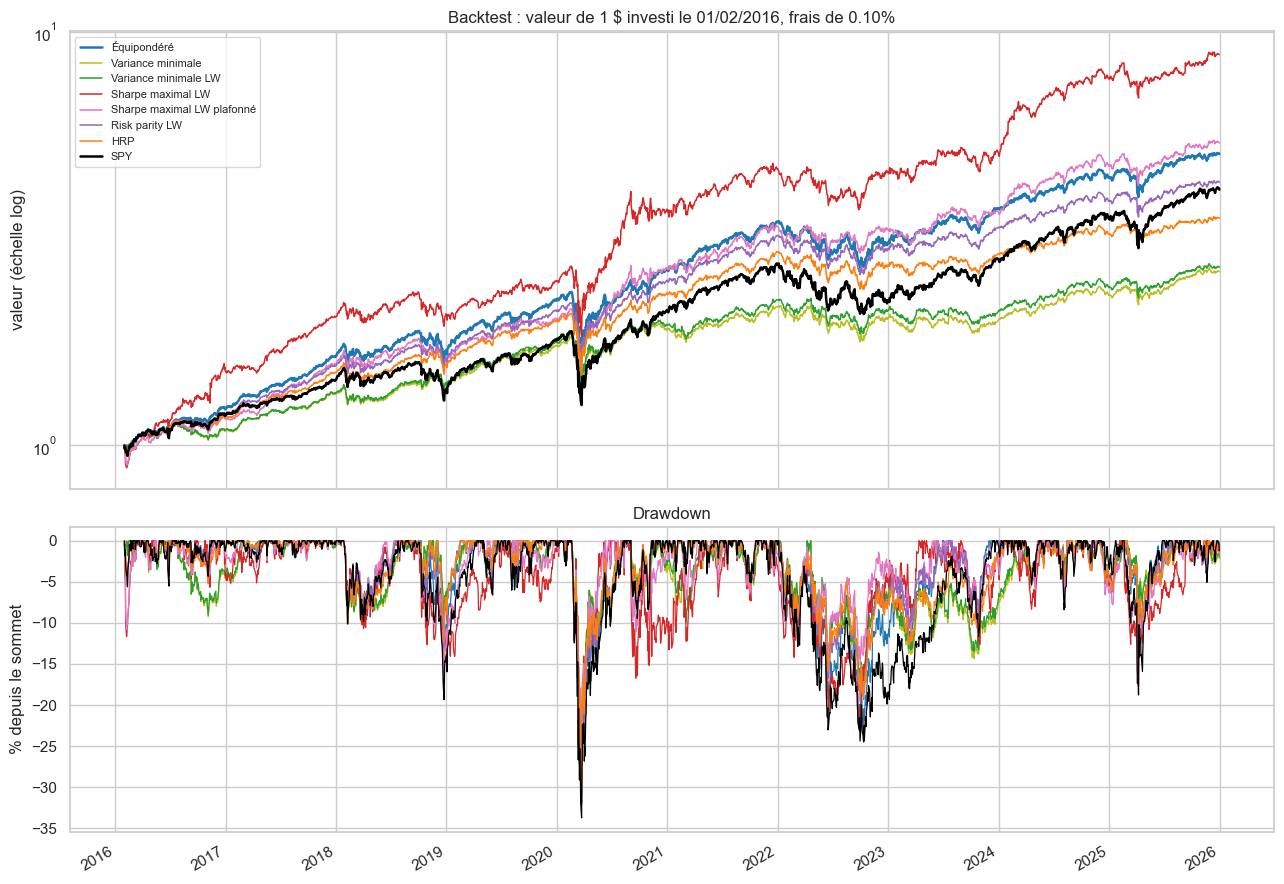

In [50]:
valeur_bt = (1 + r_bt).cumprod()
dd_bt = r_bt.apply(drawdowns)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for nom in r_bt:
    epaisseur = 1.8 if nom in (REFERENCE, "Équipondéré") else 1.1
    valeur_bt[nom].plot(ax=ax1, color=COULEURS[nom], lw=epaisseur, label=nom)
    (dd_bt[nom] * 100).plot(ax=ax2, color=COULEURS[nom], lw=0.9, label=nom)
ax1.set(yscale="log", ylabel="valeur (échelle log)",
        title=f"Backtest : valeur de 1 $ investi le {r_bt.index[0]:%d/%m/%Y}, frais de {FRAIS:.2%}")
ax1.legend(fontsize=8, loc="upper left")
ax2.set(ylabel="% depuis le sommet", xlabel="", title="Drawdown")
plt.tight_layout()
plt.show()

**Observations (février 2016 – décembre 2025, frais de 0,10 %).**
- **Classement par ratio de Sharpe** : Sharpe maximal LW (1,03), Sharpe maximal LW plafonné (0,95), **équipondéré (0,94)**, risk parity LW (0,90), HRP (0,80), SPY (0,77), variance minimale LW (0,64), variance minimale (0,62).
- **Valeur finale de 1 $** : 8,81 $ pour le Sharpe maximal LW, 5,38 $ pour sa version plafonnée, 5,06 $ pour l'équipondéré, 4,33 $ pour le risk parity, 4,15 $ pour SPY, 3,54 $ pour le HRP et environ 2,65 $ pour les deux variances minimales.
- **Le Sharpe maximal LW gagne, mais à un prix élevé.**
  - Il ne détient en moyenne que **5,3 actions effectives** et renouvelle son portefeuille près de 7 fois par an (rotation de 687 %), ce qui coûte 0,69 % par an.
  - Sa CVaR 95 % est la plus élevée (3,14 %).
  - Son avance sur l'équipondéré (+6,5 points de rendement excédentaire par an) **n'est pas statistiquement significative** : la statistique t de la différence des rendements journaliers vaut 1,44, sous le seuil de 1,96.
- **Les variances minimales réduisent bien la volatilité** (13,8 % contre 16,6 %) et la CVaR (2,0 % contre 2,5 %), mais pas le max drawdown (−29,2 % contre −31,8 %). Leur rendement est inférieur de 7 points par an à celui de l'équipondéré, un écart cette fois significatif (t ≈ −2,5). Ledoit-Wolf améliore légèrement le résultat (Sharpe de 0,64 contre 0,62) et réduit la rotation (301 % contre 346 %).
- **Le risk parity LW est la méthode la plus stable** : rotation de 65 % par an, à peine plus que l'équipondéré (52 %), et des performances proches de celui-ci, avec un peu moins de risque.
- **Le krach du Covid-19 touche toutes les stratégies de façon comparable** : de −28 % à −34 % entre le 20 février et le 23 mars 2020. Quand toutes les corrélations montent ensemble (§ 6.3), aucune diversification entre actions ne protège vraiment.

## 28. Évolution des poids et performances annuelles

Les poids cibles sont agrégés par secteur à chaque rééquilibrage, pour les quatre méthodes optimisées. Les rendements de chaque année civile sont ensuite comparés (2016 commence en février).

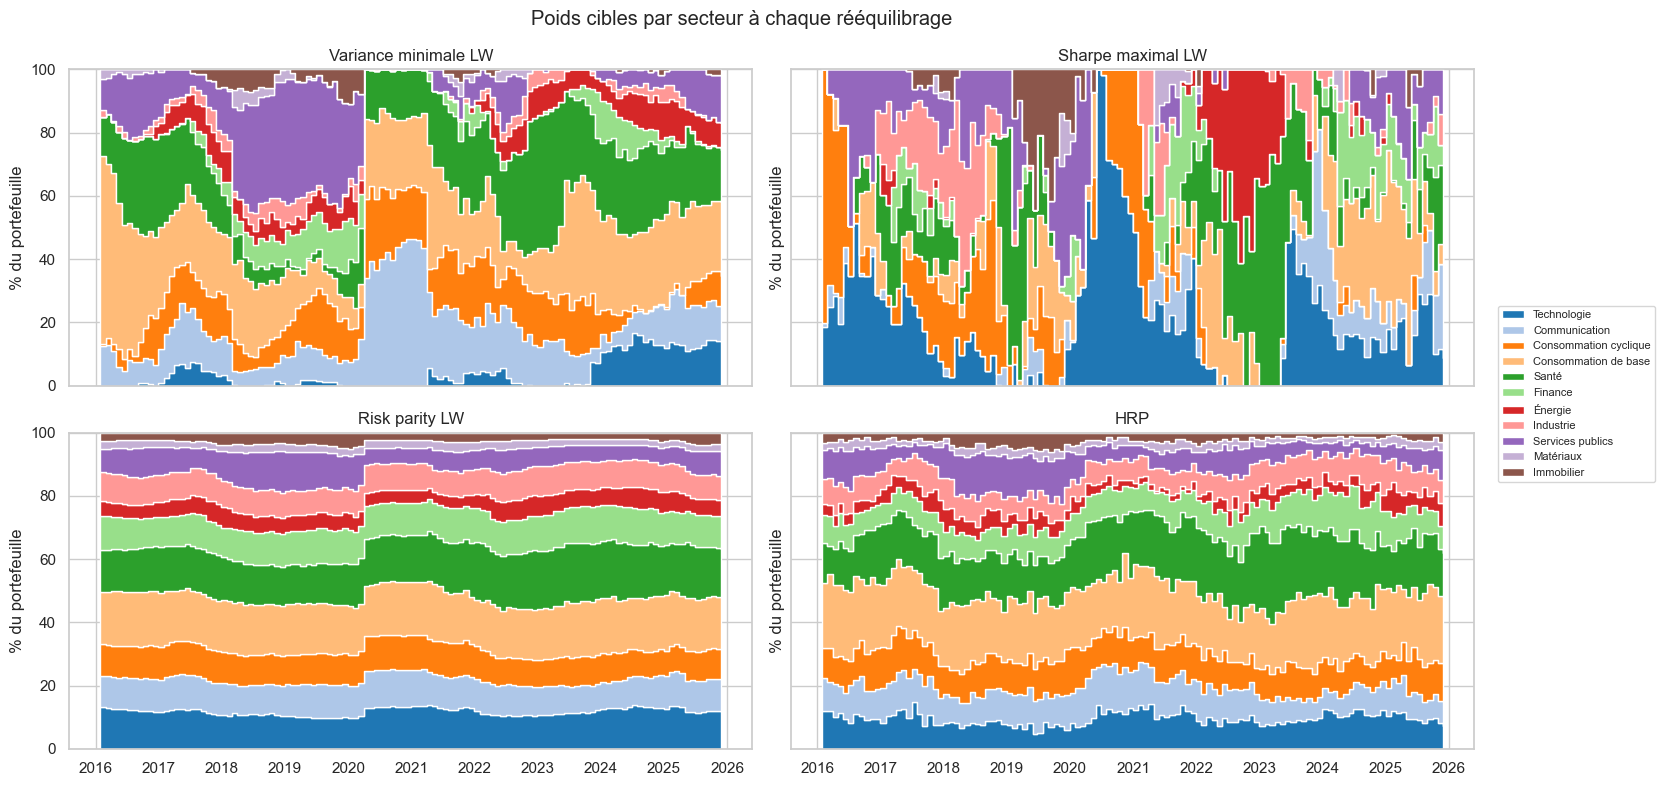

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, nom in zip(axes.flat, ["Variance minimale LW", "Sharpe maximal LW", "Risk parity LW", "HRP"]):
    par_secteur = cibles[nom].T.groupby(SECTEUR_DE).sum().T[list(SECTEURS)] * 100
    ax.stackplot(par_secteur.index, par_secteur.T, labels=par_secteur.columns, step="post",
                 colors=[COULEURS_SECTEURS[s] for s in par_secteur.columns])
    ax.set(title=nom, ylim=(0, 100), ylabel="% du portefeuille")
poignees, etiquettes = axes[0, 0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
fig.suptitle("Poids cibles par secteur à chaque rééquilibrage")
plt.tight_layout()
plt.show()

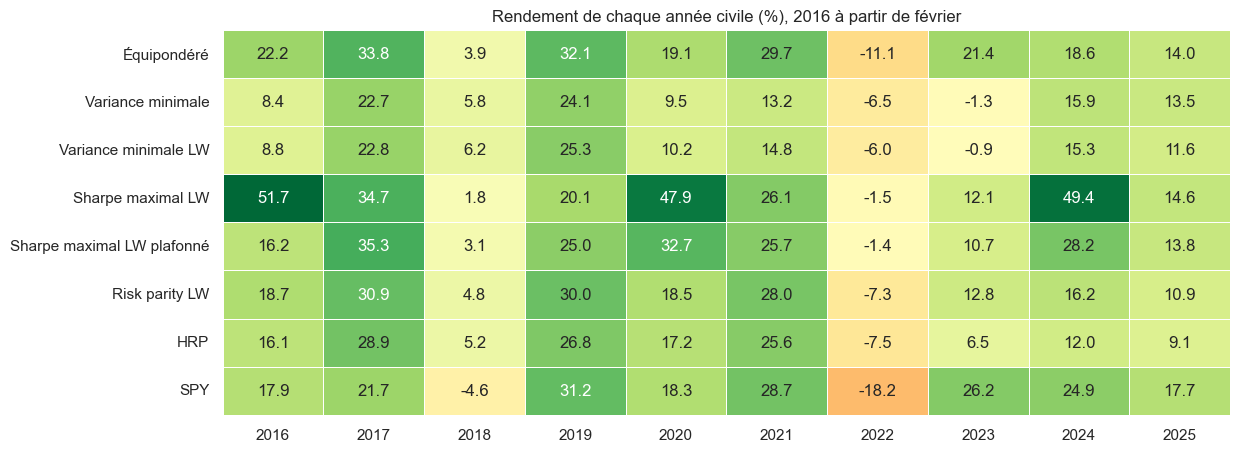

Années où la stratégie bat l'équipondéré (sur 10 ) :
Variance minimale             2
Variance minimale LW          2
Sharpe maximal LW             6
Sharpe maximal LW plafonné    4
Risk parity LW                2
HRP                           2
SPY                           3


In [52]:
annuel_bt = r_bt.groupby(r_bt.index.year).apply(lambda x: (1 + x).prod() - 1) * 100

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(annuel_bt.T, annot=True, fmt=".1f", cmap="RdYlGn", center=0, cbar=False, linewidths=0.5, ax=ax)
ax.set(title="Rendement de chaque année civile (%), 2016 à partir de février", xlabel="", ylabel="")
plt.show()

# Nombre d'années où chaque stratégie bat l'équipondéré
print("Années où la stratégie bat l'équipondéré (sur", len(annuel_bt), ") :")
print((annuel_bt.gt(annuel_bt["Équipondéré"], axis=0)).sum().drop("Équipondéré").to_string())

**Observations.**
- **Poids par secteur.** Les deux méthodes optimisées changent fortement de profil d'un mois à l'autre :
  - la variance minimale LW passe d'environ 40 % en services publics (2019) à environ 45 % en communication (2020–2021) ;
  - le Sharpe maximal LW suit les gagnants de l'année écoulée, par exemple la technologie à plus de 70 % fin 2020, puis l'énergie autour de 40 % en 2022–2023.

  Le risk parity garde au contraire une répartition presque constante. Le HRP est stable en moyenne, mais plus agité d'un mois à l'autre : de petits changements de corrélation suffisent à réordonner l'arbre (effet de chaînage, § 24.1), ce qui explique sa rotation (275 % par an contre 65 % pour le risk parity).
- **Performances annuelles.** Les méthodes défensives (variance minimale, risk parity, HRP) ne battent l'équipondéré que **2 années sur 10** : 2018 et 2022, les deux années de baisse. En 2022, la variance minimale perd 6,5 % et le risk parity 7,3 %, contre 11,1 % pour l'équipondéré et 18,2 % pour SPY. Elles jouent donc le rôle d'une protection partielle, payée par des gains plus faibles en marché haussier.
- **Le Sharpe maximal LW bat l'équipondéré 6 années sur 10.** Son avance vient surtout de trois années exceptionnelles : 2016 (+51,7 %), 2020 (+47,9 %) et 2024 (+49,4 %). Une stratégie qui doit son résultat à quelques années est fragile.
- SPY ne bat l'équipondéré qu'en 2023, 2024 et 2025, comme à l'étape 2 (§ 14).

## 29. Sensibilité aux frais de transaction

Le backtest est relancé avec quatre niveaux de frais. Les poids cibles ne dépendent pas des frais : seule la simulation est refaite. Une stratégie à forte rotation perd davantage quand les frais augmentent.

In [53]:
sensibilite_frais = pd.DataFrame({
    f"frais {f:.2%}": backtest(f)[0].apply(ratio_sharpe, rf=rf) for f in FRAIS_TESTES
})
sensibilite_frais["rotation_annuelle_%"] = (tableau_bt["rotation_annuelle"] * 100).round(0)
print("Ratio de Sharpe selon le niveau de frais :")
sensibilite_frais.round(2).sort_values(f"frais {FRAIS:.2%}", ascending=False)

Ratio de Sharpe selon le niveau de frais :


,frais 0.00%,frais 0.10%,frais 0.25%,frais 0.50%,rotation_annuelle_%
Sharpe maximal LW,1.0600,1.0300,0.9800,0.9000,687.0000
Sharpe maximal LW plafonné,0.9800,0.9500,0.9000,0.8200,529.0000
Équipondéré,0.9500,0.9400,0.9400,0.9300,52.0000
Risk parity LW,0.9000,0.9000,0.8900,0.8800,65.0000
HRP,0.8200,0.8000,0.7700,0.7200,275.0000
SPY,0.7700,0.7700,0.7700,0.7700,NaN
Variance minimale LW,0.6600,0.6400,0.6100,0.5500,301.0000
Variance minimale,0.6500,0.6200,0.5800,0.5200,346.0000


**Observations.**
- **Les stratégies à faible rotation ne dépendent presque pas des frais** : de 0 à 0,50 %, le Sharpe de l'équipondéré passe de 0,95 à 0,93 et celui du risk parity de 0,90 à 0,88.
- **Les stratégies à forte rotation y sont très sensibles** : le Sharpe maximal LW perd 0,16 (de 1,06 à 0,90), sa version plafonnée aussi (0,98 à 0,82), et la variance minimale passe de 0,65 à 0,52.
- **Avec des frais de 0,50 %, l'équipondéré devient la meilleure stratégie** (0,93, contre 0,90 pour le Sharpe maximal LW). Le classement du § 27 dépend donc de l'hypothèse de frais, choisie ici pour des actions très liquides.

## 30. Dans l'échantillon contre hors échantillon

Pour mesurer le biais d'anticipation des étapes 3 à 5, chaque stratégie est aussi appliquée avec des poids **fixes**, estimés sur toute la période 2015–2025 (connaissance parfaite du futur), puis évaluée sur la même période que le backtest, sans frais. L'écart entre les deux ratios de Sharpe montre ce que coûte l'obligation de n'utiliser que le passé.

In [54]:
poids_complets = {nom: f(R) for nom, f in STRATEGIES.items()}
r_dans = pd.DataFrame({nom: R.loc[r_bt.index] @ w for nom, w in poids_complets.items()})
dans_hors = pd.DataFrame({
    "Sharpe dans l'échantillon": r_dans.apply(ratio_sharpe, rf=rf),
    "Sharpe du backtest": tableau_bt["sharpe"].drop(REFERENCE),
})
dans_hors["écart"] = dans_hors["Sharpe du backtest"] - dans_hors["Sharpe dans l'échantillon"]
dans_hors.round(2).sort_values("écart")

,Sharpe dans l'échantillon,Sharpe du backtest,écart
Sharpe maximal LW,1.4800,1.0300,-0.4500
Sharpe maximal LW plafonné,1.3400,0.9500,-0.4000
Variance minimale,0.8000,0.6200,-0.1800
Variance minimale LW,0.8000,0.6400,-0.1600
HRP,0.8900,0.8000,-0.1000
Risk parity LW,0.9300,0.9000,-0.0300
Équipondéré,0.9600,0.9400,-0.0100


**Observations.**
- **Plus une méthode dépend de $\mu$, plus elle perd hors échantillon.** Le Sharpe maximal LW passe de 1,48 à 1,03 (−0,45) et sa version plafonnée de 1,34 à 0,95 (−0,40). Les variances minimales perdent 0,16 à 0,18, le HRP 0,10, le risk parity 0,03.
- **L'équipondéré ne perd presque rien** (−0,01, dû à la dérive des poids entre deux rééquilibrages mensuels et aux frais) : il n'estime rien.

**Interprétation.** Les performances des étapes 3 à 5 surestiment surtout celles des méthodes qui optimisent. Même ainsi, le Sharpe maximal LW reste en tête hors échantillon. Sur 2016–2025, la moyenne sur 252 jours a fonctionné comme un signal de **momentum** (acheter les actions qui ont le plus monté sur un an), favorable sur cette période, en particulier grâce à NVDA.

## 31. Extension : changement de régime par modèle de Markov caché (HMM)

**Motivation.** L'étape 1 a montré que la volatilité vient par vagues (§ 6.4) et que la corrélation moyenne entre actions bondit en période de crise (0,81 en mars 2020, § 6.3). Une même stratégie n'est donc peut-être pas adaptée à tous les régimes de marché.

**Modèle.** Le rendement journalier de SPY dépend d'un **état caché** $s_t \in \{\text{calme}, \text{agité}\}$ :
- dans l'état $k$, $r_t \sim \mathcal{N}(\mu_k, \sigma_k^2)$ ;
- l'état suit une chaîne de Markov : $P(s_t = j \mid s_{t-1} = i) = A_{ij}$. Une forte probabilité de rester dans le même état ($A_{ii}$ proche de 1) produit des périodes persistantes, de durée moyenne $1/(1 - A_{ii})$ jours.

Les paramètres $(\mu_k, \sigma_k, A)$ sont estimés par maximum de vraisemblance avec l'algorithme de Baum-Welch (algorithme EM), codé ci-dessous avec `numpy`. L'état « agité » est, par convention, celui de plus forte volatilité.

**Éviter le biais d'anticipation.** Deux précautions :
1. Seule la probabilité **filtrée** $P(s_t = \text{agité} \mid r_1, \dots, r_t)$ est utilisée : elle ne dépend que des rendements passés. Les probabilités lissées et l'algorithme de Viterbi utilisent tout l'échantillon, y compris le futur.
2. Les paramètres sont réestimés **à chaque fin d'année** sur toutes les données disponibles à cette date (fenêtre croissante), puis utilisés pendant l'année suivante.

**Règle d'allocation (stratégie « Régimes HMM »).** À chaque rééquilibrage mensuel : si la probabilité filtrée de l'état agité dépasse 50 %, le portefeuille prend les poids de la variance minimale LW ; sinon, ceux de l'équipondéré. Les frais sont les mêmes que pour les autres stratégies.

**Limites assumées.** Le signal n'est consulté qu'une fois par mois, le seuil de 50 % n'est pas optimisé, et un HMM gaussien à deux états reste une description très simplifiée du marché.

In [55]:
def densites(x, moyennes, ecarts):
    # Densité gaussienne de chaque rendement dans chaque état (tableau jours × états)
    return np.exp(-0.5 * ((x[:, None] - moyennes) / ecarts) ** 2) / (ecarts * np.sqrt(2 * np.pi))

def filtrer(x, pi, A, moyennes, ecarts):
    # Récursion avant : alpha[t] = P(s_t | r_1..r_t), c[t] = facteur de normalisation
    B = densites(x, moyennes, ecarts)
    alpha, c = np.zeros_like(B), np.zeros(len(x))
    a = pi * B[0]
    for t in range(len(x)):
        if t > 0:
            a = (alpha[t - 1] @ A) * B[t]
        c[t] = a.sum()
        alpha[t] = a / c[t]
    return alpha, c, B

def estimer_hmm(x, n_iterations=500, tolerance=1e-8):
    # Algorithme de Baum-Welch pour un HMM gaussien à deux états ; état 0 = calme, état 1 = agité
    x = np.asarray(x)
    pi = np.array([0.5, 0.5])
    A = np.array([[0.98, 0.02], [0.05, 0.95]])
    moyennes = np.full(2, x.mean())
    ecarts = x.std() * np.array([0.7, 1.5])
    vraisemblance = -np.inf
    for _ in range(n_iterations):
        # Étape E : récursions avant et arrière
        alpha, c, B = filtrer(x, pi, A, moyennes, ecarts)
        beta = np.ones_like(alpha)
        for t in range(len(x) - 2, -1, -1):
            beta[t] = A @ (B[t + 1] * beta[t + 1]) / c[t + 1]
        gamma = alpha * beta                                               # P(s_t | toutes les données)
        xi = A * (alpha[:-1].T @ (B[1:] * beta[1:] / c[1:, None]))         # nombre espéré de transitions
        # Étape M
        pi = gamma[0]
        A = xi / xi.sum(axis=1, keepdims=True)
        poids_etats = gamma.sum(axis=0)
        moyennes = gamma.T @ x / poids_etats
        ecarts = np.sqrt((gamma * (x[:, None] - moyennes) ** 2).sum(axis=0) / poids_etats)
        nouvelle = np.log(c).sum()
        if nouvelle - vraisemblance < tolerance:
            break
        vraisemblance = nouvelle
    ordre = np.argsort(ecarts)
    return pi[ordre], A[np.ix_(ordre, ordre)], moyennes[ordre], ecarts[ordre]

# Contrôle sur données simulées : deux régimes connus doivent être retrouvés
generateur = np.random.default_rng(0)
etats = np.repeat([0, 1, 0, 1], 500)
x_sim = np.where(etats == 0, generateur.normal(0.001, 0.005, len(etats)), generateur.normal(-0.002, 0.025, len(etats)))
_, A_sim, m_sim, e_sim = estimer_hmm(x_sim)
assert np.allclose(e_sim, [0.005, 0.025], rtol=0.1) and (np.diag(A_sim) > 0.99).all()
print("Contrôle vérifié : volatilités estimées", np.round(e_sim, 4))

# Paramètres estimés sur toute la période (à titre descriptif uniquement)
spy = rendements[REFERENCE]
_, A_c, m_c, e_c = estimer_hmm(spy.to_numpy())
pd.DataFrame({
    "rendement_moyen_annualise_%": m_c * JOURS_PAR_AN * 100,
    "volatilite_annualisee_%": e_c * np.sqrt(JOURS_PAR_AN) * 100,
    "probabilite_de_rester": np.diag(A_c),
    "duree_moyenne_jours": 1 / (1 - np.diag(A_c)),
}, index=["calme", "agité"]).round(3)

Contrôle vérifié : volatilités estimées [0.0051 0.0243]


,rendement_moyen_annualise_%,volatilite_annualisee_%,probabilite_de_rester,duree_moyenne_jours
calme,28.9390,9.6940,0.9820,54.5910
agité,-19.2380,28.5610,0.9570,23.3820


In [56]:
# Probabilité filtrée de l'état agité : paramètres réestimés chaque fin d'année sur le passé seulement
proba_agite = pd.Series(np.nan, index=spy.index)
for annee in range(2016, 2026):
    parametres = estimer_hmm(spy.loc[:str(annee - 1)].to_numpy())
    alpha, _, _ = filtrer(spy.to_numpy(), *parametres)       # récursion avant : n'utilise que r_1..r_t
    dans_annee = spy.index.year == annee
    proba_agite[dans_annee] = alpha[dans_annee, 1]

# Stratégie : variance minimale LW si l'état agité est probable au rééquilibrage, équipondéré sinon
agite = proba_agite.loc[dates_reeq] > 0.5
dates_agitees = agite.index[agite]
cibles_hmm = cibles["Équipondéré"].copy()
cibles_hmm.loc[dates_agitees] = cibles["Variance minimale LW"].loc[dates_agitees]
cibles["Régimes HMM"] = cibles_hmm
r_bt["Régimes HMM"], rotations["Régimes HMM"] = simuler(cibles_hmm, FRAIS)
tableau_bt = tableau_backtest(r_bt, rotations, FRAIS)

print(f"Mois en régime agité : {agite.sum()} sur {len(agite)} ({agite.mean():.0%})")
lisible(tableau_bt.loc[["Régimes HMM", "Équipondéré", "Variance minimale LW", REFERENCE]])

Mois en régime agité : 46 sur 119 (39%)


,rendement_annualise,volatilite_annualisee,sharpe,max_drawdown,var_95%,cvar_95%,var_99%,cvar_99%,rotation_annuelle,frais_annuels,nb_effectif_moyen
Régimes HMM,14.5500,14.3400,0.8700,-29.2200,1.2500,2.1100,2.4500,3.9800,530.7500,0.5300,27.4800
Équipondéré,17.8000,16.5600,0.9400,-31.7900,1.4600,2.5100,3.0900,4.5400,52.2600,0.0500,39.0000
Variance minimale LW,10.5400,13.7800,0.6400,-29.2200,1.1600,1.9900,2.2800,3.8400,300.9400,0.3000,10.8400
SPY,15.4700,17.9600,0.7700,-33.7200,1.6800,2.7600,3.3100,4.8100,NaN,NaN,NaN


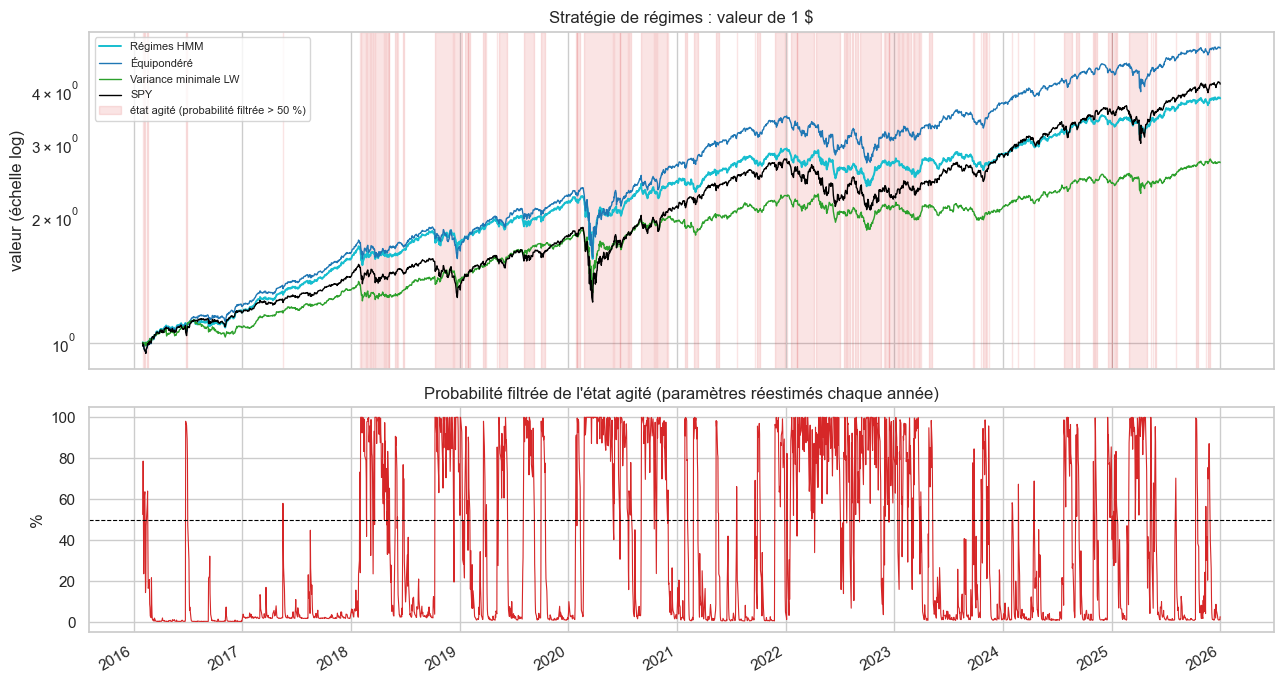

In [57]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
periode = r_bt.index
for nom in ["Régimes HMM", "Équipondéré", "Variance minimale LW", REFERENCE]:
    (1 + r_bt[nom]).cumprod().plot(ax=ax1, color=COULEURS[nom], lw=1.4 if nom == "Régimes HMM" else 1, label=nom)
ax1.fill_between(periode, 0, 1, where=proba_agite.loc[periode] > 0.5, transform=ax1.get_xaxis_transform(),
                 color="tab:red", alpha=0.12, label="état agité (probabilité filtrée > 50 %)")
ax1.set(yscale="log", ylabel="valeur (échelle log)", title="Stratégie de régimes : valeur de 1 $")
ax1.legend(fontsize=8, loc="upper left")
(proba_agite.loc[periode] * 100).plot(ax=ax2, color="tab:red", lw=0.8)
ax2.axhline(50, color="black", lw=0.8, ls="--")
ax2.set(ylabel="%", xlabel="", title="Probabilité filtrée de l'état agité (paramètres réestimés chaque année)")
plt.tight_layout()
plt.show()

**Observations.**
- **Les deux régimes estimés sur toute la période sont bien distincts.** Le régime calme a une volatilité de 9,7 % par an et dure en moyenne 55 jours ; le régime agité a une volatilité de 28,6 % et dure en moyenne 23 jours. Le rendement moyen est fortement positif dans le premier (+28,9 % par an) et négatif dans le second (−19,2 %).
- **Hors échantillon, le régime agité est détecté 46 mois sur 119 (39 %)**, presque jamais en 2016–2017, et souvent de 2018 à 2023.
- **La stratégie de régimes réduit le risque, mais pas assez pour compenser la perte de rendement.**
  - Sa volatilité (14,3 %) et son max drawdown (−29,2 %) sont plus faibles que ceux de l'équipondéré (16,6 % et −31,8 %).
  - Son rendement est plus faible (14,6 % contre 17,8 % par an), et son Sharpe aussi (0,87 contre 0,94).
  - Chaque changement de régime remplace tout le portefeuille : la rotation atteint 531 % par an, soit 0,53 % de frais par an.
- **Le signal arrive après le choc.** La probabilité filtrée ne monte qu'après plusieurs fortes baisses. Le portefeuille passe en variance minimale une fois la chute engagée, puis y reste pendant une partie du rebond, alors que les actions défensives remontent moins vite.

**Conclusion.** Le modèle décrit bien les régimes de volatilité passés, mais, avec cette règle simple et une décision mensuelle, il n'améliore pas l'équipondéré. Le résultat dépend aussi de choix non optimisés (seuil de 50 %, fréquence, stratégie utilisée dans chaque régime) ; les optimiser sur cette même période créerait un risque de sur-ajustement.

## 32. Sauvegarde

Les rendements journaliers de toutes les stratégies du backtest et leur tableau de mesures sont enregistrés dans `data/`.

In [58]:
r_bt.to_csv(DOSSIER / "rendements_backtest.csv")
tableau_bt.rename_axis("strategie").to_csv(DOSSIER / "mesures_backtest.csv")

for f in ["rendements_backtest.csv", "mesures_backtest.csv"]:
    print(f"{f:30s} {(DOSSIER / f).stat().st_size / 1e3:.0f} ko")

rendements_backtest.csv        518 ko
mesures_backtest.csv           2 ko


## 33. Synthèse et limites des étapes 3 à 6

**Résultats du backtest** (février 2016 – décembre 2025, rééquilibrage mensuel, frais de 0,10 %).

| Stratégie | Rendement annualisé | Volatilité | Sharpe | Max drawdown | Rotation annuelle |
|---|---|---|---|---|---|
| Sharpe maximal LW | 24,6 % | 21,5 % | 1,03 | −32,0 % | 687 % |
| Sharpe maximal LW plafonné | 18,5 % | 17,3 % | 0,95 | −28,2 % | 529 % |
| Équipondéré | 17,8 % | 16,6 % | 0,94 | −31,8 % | 52 % |
| Risk parity LW | 16,0 % | 15,4 % | 0,90 | −30,9 % | 65 % |
| Régimes HMM | 14,6 % | 14,3 % | 0,87 | −29,2 % | 531 % |
| HRP | 13,6 % | 14,7 % | 0,80 | −29,3 % | 275 % |
| SPY | 15,5 % | 18,0 % | 0,77 | −33,7 % | — |
| Variance minimale LW | 10,5 % | 13,8 % | 0,64 | −29,2 % | 301 % |
| Variance minimale | 10,3 % | 13,9 % | 0,62 | −29,2 % | 346 % |

**À retenir.**
- **L'équipondéré est très difficile à battre.** Il n'estime rien, coûte peu en frais, et seul le Sharpe maximal le dépasse nettement. Ce résultat rejoint celui de DeMiguel, Garlappi et Uppal (2009) : avec des paramètres estimés, les portefeuilles optimisés font rarement mieux que l'équipondération.
- **Le Sharpe maximal LW obtient le meilleur Sharpe, mais ce résultat est fragile** : avance non significative (t = 1,44), très forte concentration (5 actions effectives), rotation de près de 700 % par an, et dépendance à quelques années exceptionnelles et à NVDA. Avec des frais de 0,50 %, il passe derrière l'équipondéré.
- **Les méthodes fondées sur le risque tiennent leur promesse sur le risque, pas sur le rendement.** La variance minimale réduit la volatilité de 17 % et la CVaR de 20 % par rapport à l'équipondéré, au prix de 7 points de rendement par an. Le risk parity offre le meilleur compromis entre stabilité et performance. Le HRP, avec le lien simple, est moins stable que prévu.
- **Ledoit-Wolf améliore légèrement la variance minimale** (Sharpe de 0,64 contre 0,62, rotation réduite de 13 %). Son effet est réel sur des fenêtres d'un an (conditionnement divisé par 3), mais modeste en performance.
- **Le modèle de régimes (HMM)** identifie bien les phases de forte volatilité, mais trop tard pour une décision mensuelle : il réduit le risque sans améliorer le Sharpe.

**Limites.**
- **Une seule période de 10 ans.** L'erreur-type d'un ratio de Sharpe est d'environ 0,35 (§ 12) : la plupart des écarts entre stratégies ne sont pas significatifs. Le classement pourrait changer sur une autre période, en particulier sans le parcours exceptionnel de NVDA.
- **Biais de survie** (§ 8) : les 39 actions sont des entreprises qui ont réussi jusqu'en 2025. Cela favorise toutes les stratégies par rapport à SPY, et surtout celles qui suivent les gagnants récents, comme le Sharpe maximal.
- **Paramètres fixés a priori** (fenêtre de 252 jours, rééquilibrage mensuel, plafond de 10 %, seuil de 50 % du HMM). Ce choix évite le sur-ajustement, mais d'autres valeurs donneraient d'autres résultats.
- **Modèle de frais simple** : coût proportionnel au volume échangé, sans impact de marché, sans impôts et sans coût de détention.
- **Pas de vente à découvert** : les résultats ne s'appliquent qu'aux portefeuilles investis uniquement en positions acheteuses.